In [1]:
# ==============================================================================
# STEP S -- QUARTERLY SEASONALITY OF THE PRICE DECOMPOSITION (COVID-19 read)
# ------------------------------------------------------------------------------
# WHY THIS STEP: the annual rollup shows a persistent negative selection
# (spatial dispersion of formal-firm formation) + positive transmission
# (within-region real growth), with the lone reversal in 2019->20. To see WHERE
# in the calendar the COVID shock lands, we re-ran the *exact same* engine on a
# (parish, year, quarter) grid, holding each calendar quarter fixed and rolling
# it year over year (Q1 2017->18->...->23, then Q2, ...). Same $1,000/yr floor,
# same methodology; only the time grain changes. This cell just reads those
# results and plots them -- the computation is the quarterly, year-over-year
# run of ecuador_price/decomposition.py.
# Source table: results/decomposition/quarterly_year_over_year_2017_2023/
#               decomposition_summary.csv  (path = pop, per year).
# ==============================================================================
import sys
from pathlib import Path
import pandas as pd

# The project root is the folder that holds ecuador_price/ (this notebook lives in notebooks/).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "ecuador_price").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
from ecuador_price import decomposition as dec, paths, style
style.apply()                      # the project's fonts and colours

QUARTERLY_DIR = paths.decomposition_run("quarterly_year_over_year_2017_2023")
YEARLY_DIR    = paths.decomposition_run("yearly_consecutive_2017_2023")
seas = pd.read_csv(QUARTERLY_DIR / "decomposition_summary.csv")
seas = seas[seas["path"] == "pop"].copy()
seas["quarter"]    = seas["season"].str[1:].astype(int)            # "Q3" -> 3
seas["final_year"] = seas["final_period"].str[:4].astype(int)      # "2018Q3" -> 2018

# The year-over-year steps (drop the full-span "headline" rows) and a readable
# x label per year pair. One row per (quarter, year-pair); pivot to quarter cols.
# In order to analyze seasonality over the course of 2017-2023
# we do the decomposition for each quarter
annual = seas[seas["window_type"] == "step"].copy()
annual["year_pair"] = (annual["initial_year"].astype(str).str[-2:] + "->"
                       + annual["final_year"].astype(str).str[-2:])
order = (annual.sort_values("initial_year")["year_pair"].drop_duplicates().tolist())

def pivot(metric):
    p = annual.pivot(index="year_pair", columns="quarter", values=metric)
    return p.reindex(order) # chronological x axis

sel_piv, trans_piv = pivot("selection_total"), pivot("transmission")
print("transmission (log pts / yr), year-pair x quarter:")
print(trans_piv.round(3).to_string())
print("\nfull-span 2017->2023 selection by quarter:")
print(seas[seas.window_type == "headline"]
      .set_index("quarter")[["selection_total", "transmission"]].round(4).to_string())

transmission (log pts / yr), year-pair x quarter:
quarter        1      2      3      4
year_pair                            
17->18     0.080  0.079  0.066  0.041
18->19     0.025  0.021  0.012  0.001
19->20    -0.051 -0.405 -0.173 -0.062
20->21     0.027  0.432  0.243  0.193
21->22     0.146  0.120  0.107  0.091
22->23     0.066  0.099 -0.008  0.020

full-span 2017->2023 selection by quarter:
         selection_total  transmission
quarter                               
1                -0.0431        0.0494
2                -0.0305        0.0570
3                -0.0189        0.0414
4                -0.0186        0.0482


# Quearterly Seasonality Selection

# Quarterly Seasonality Transmission

## Growth-rate & level distributions by year — how to read the histograms

**All logs here are natural logs (`ln`, base *e*)** — never log₁₀. That is what `np.log` computes and what the engine uses, and it is why a log change doubles as a growth rate (an `ln` change ≈ the fractional change for small moves; the exact % is `e^x − 1`).

**What each panel shows.** One histogram per year (or per window). Every valid parish contributes one value; we bin those values:

- **x-axis — the quantity being distributed** (one parish = one value). We look at three of them:
  - **firm-count (population) growth rate** — `g = ln(firms_{t+1}) − ln(firms_t)` per year. This is the decomposition's *fitness*; "firm growth rate" and "population growth rate" are the **same thing** in this data.
  - **real total-sales growth rate** — `g = ln(sales_{t+1}) − ln(sales_t)` per year (the empirical sales growth).
  - **log real total-sales (level)** — `z = ln(sales_t)`; the *trait* itself, a **level, not a growth**.

  So a growth value `g` is a parish's proportional year-over-year change: `g = 0.10 ≈ +10%`, `g = 0` = no change, `g < 0` = shrank.

- **bins.** The x-range (clipped to the pooled 1st–99th percentile so the bulk is visible) is split into **40 equal-width bars**; each bar collects the parishes whose value lands in that little interval. Wider spread ⇒ growth rates more dispersed across places.

- **y-axis — density.** Bars are normalised so the **total area = 1** (`density=True`): bar height = (fraction of parishes in the bin) ÷ (bin width). Height alone is **not** a count or a probability — only height × width (an *area*) is the fraction of parishes. Normalising this way lets the fitted density curves sit on the same axis and lets years with different parish counts be compared.

**Two fitted curves on every panel** so the shape is judgeable at a glance:
- **solid** = fat-tailed **skew-*t*** (Jones–Faddy);  **dashed** = **Gaussian** (same mean & sd).
- the in-panel `best:` label reports which one wins by AIC.

### Do they fit a skew-*t* or a Gaussian? — they split cleanly
- **Growth rates (firms *and* sales): emphatically skew-*t*.** Excess kurtosis ≈ 3–11 and tail index ≈ 1–2.4 (a Gaussian has excess kurtosis 0 and an "infinite" tail index). AIC prefers the skew-*t* by *hundreds* of points every year — the Gaussian misses both the tall central spike and the heavy tails.
- **The log-sales *level*: essentially Gaussian.** The skew-*t* fit collapses toward a normal (tail index blows up to 60–800) and excess kurtosis ≈ −0.5; AIC is a tie. Plainly: **sales are ≈ log-normal across parishes, but their growth rates are fat-tailed.**

*(Everything is capped at 2023 — 2024–2025 are not used.)*


In [2]:
# ==============================================================================
# STEP D -- setup + helpers for the growth/level distribution figures
# ------------------------------------------------------------------------------
# Rebuilds the same (parish, year) firm-count AND real-sales tables the
# decomposition uses (via the imported engine), CAPPED AT 2023. Defines:
#   YEARS / VALID / FIRMS / SALES / pairs  -> the shared survivor tables
#   fit_both(x)      -> fit skew-t AND Gaussian, compare by AIC
#   the PALETTE + tint()      -> one colour scheme for every distribution figure
#   add_level_axis() -> a top axis that reads a log panel back in real units
#   X_FIRM / X_SALES -> shared x-axis labels for the two growth panels
# The engine and every path come from the ecuador_price package (first cell).
# ==============================================================================
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy import stats

GROWTH_DIR = paths.FIRM_GROWTH_DISTRIBUTIONS
GROWTH_DIR.mkdir(parents=True, exist_ok=True)

MAX_YEAR = 2023                                              # 2024-2025 not used

# Bin count is chosen by a standard rule, not a magic number. "scott" (Scott 1979,
# optimal bin width ~ 3.49·σ·n^(-1/3)) gives ~12-22 bins here. Alternatives numpy
# understands: "fd" (Freedman-Diaconis, IQR-based, robust to outliers -> more bins
# on fat tails), "doane" (Sturges corrected for skew -> fewer), "sturges", "rice".
BIN_RULE = "fd"

# ---- palette -----------------------------------------------------------------
# Three hues carry every distribution figure. What each one MEANS is fixed here,
# so the figures read as one family and no cell has to remember a hex code:
#   variable identity : firms = blue, real sales = red
#   two periods       : earlier = blue, later = red
#   three eras        : pre-COVID = blue, COVID = red, post-COVID = purple
#   pooled/full span  : grey
# The colours themselves come from ecuador_price/style.py, the project palette
# (checked there for colour-blind readers).
BLUE, RED, PURPLE, GREY = style.BLUE, style.RED, style.PURPLE, style.GREY

C_FIRMS, C_SALES = BLUE, RED          # by variable
C_EARLY, C_LATE  = BLUE, RED          # by period, when there are two
ERA_COLORS = {"Pre-COVID": BLUE, "COVID": RED, "Post-COVID": PURPLE,
              "Full span": GREY}


def tint(color, strength=0.35):
    """A pale version of `color`: keep `strength` of it and wash the rest out to
    white. Histogram bars and the fill under a fitted curve use the tint, the
    curve itself the full colour, so light and strong are always the same hue."""
    return tuple(1 - strength * (1 - c) for c in mcolors.to_rgb(color))


# ---- reading a log axis in real units ----------------------------------------
# Every distribution below is in natural logs, where "13.8" means nothing on its
# own. These tick sets put the same positions back in firms, dollars and growth
# multiples along the TOP of a panel. (In matplotlib text a bare "$" opens math
# mode, hence the escaped "\$" in the money labels.)
FIRM_TICKS   = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000]
FIRM_LABELS  = ["1", "3", "10", "30", "100", "300", "1k", "3k", "10k"]
SALES_TICKS  = [1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9, 1e10]
SALES_LABELS = [r"\$1k", r"\$10k", r"\$100k", r"\$1M", r"\$10M", r"\$100M",
                r"\$1B", r"\$10B"]
# a change of Delta ln = x means the quantity was multiplied by exp(x)
MULT_TICKS   = [0.02, 0.1, 0.25, 0.5, 1, 2, 4, 10, 50, 200]
MULT_LABELS  = [r"$\times$0.02", r"$\times$0.1", r"$\times$0.25", r"$\times$0.5",
                r"$\times$1", r"$\times$2", r"$\times$4", r"$\times$10",
                r"$\times$50", r"$\times$200"]


def add_level_axis(ax, ticks, labels):
    """Repeat the x-axis along the TOP of a panel in real units.

    `ticks` are the REAL values (10 firms, 1M dollars, x2) and they are placed at
    ln(tick), which is where that value sits on the log axis the panel already
    uses. Ticks outside the panel's x-limits are simply not drawn, so one
    generous tick list works for every figure.
    """
    top = ax.secondary_xaxis("top")
    top.set_xticks(np.log(ticks))
    top.set_xticklabels(labels, fontsize=10)
    return top


# ---- shared axis labels ------------------------------------------------------
# Growth over a window is a change in logs, Delta ln; the per-year panels divide
# it by the number of years the window spans, which is what "/ yr" says.
X_LNFIRMS = r"$\ln(\mathrm{firms})$"
X_LNSALES = r"$\ln(\mathrm{real\ sales})$"
X_FIRM   = r"$\Delta\ln(\mathrm{firms})\,/\,\mathrm{yr}$"
X_SALES  = r"$\Delta\ln(\mathrm{real\ sales})\,/\,\mathrm{yr}$"
X_DFIRM  = r"$\Delta\ln(\mathrm{firms})$"
X_DSALES = r"$\Delta\ln(\mathrm{real\ sales})$"

panel = dec.load_real_panel()
monthly = dec.monthly_table(panel)
py    = dec.parish_period_table(monthly, "yearly")          # cod_parr, year, firms, sales
YEARS = [y for y in sorted(int(y) for y in py["year"].unique()) if y <= MAX_YEAR]
valid_cells = dec.annual_valid_cells(monthly)               # firms>0 & real sales>$1,000
VALID = {y: dec.valid_parishes(py, str(y), valid_cells) for y in YEARS}
FIRMS = py.pivot(index="cod_parr", columns="year", values="firms")
SALES = py.pivot(index="cod_parr", columns="year", values="sales")   # real (deflated) sales
pairs = list(zip(YEARS[:-1], YEARS[1:]))           # annual steps 2017->18 ... 2022->23


def survivors(y0, y1):
    """Parishes valid in BOTH years, sorted: the set every y0-vs-y1 comparison uses."""
    return sorted(VALID[y0] & VALID[y1])


# The national monthly series (all parishes and sections summed), one row per
# month labelled "2018M01": total_firms is that month's stock of registered
# firms, real_sales that month's flow of real sales.
MONTHLY_NAT = (panel.assign(month=panel["anio"].astype(str) + "M"
                                  + panel["mes"].astype(str).str.zfill(2))
                    .groupby("month")[["total_firms", "real_sales"]].sum()
                    .sort_index())


def fit_both(x):
    """Fit a fat-tailed skew-t and a Gaussian; return both + an AIC verdict.
    tail index = 2*min(a,b) (Student-t-equiv dof of the heavier tail; lower=fatter);
    'skew' key holds the sample skewness (labelled α in the figures)."""
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        a, b, loc, sc = stats.jf_skew_t.fit(x)
        st = stats.jf_skew_t(a, b, loc, sc)
        gs = stats.norm(x.mean(), x.std(ddof=0))
        aic_s = 2 * 4 - 2 * st.logpdf(x).sum()              # skew-t: 4 params
        aic_g = 2 * 2 - 2 * gs.logpdf(x).sum()              # Gaussian: 2 params
    return dict(a=a, b=b, loc=loc, scale=sc, st=st, gs=gs, tail=2 * min(a, b),
                skew=float(stats.skew(x)), exkurt=float(stats.kurtosis(x)),
                aic_s=aic_s, aic_g=aic_g, dAIC=aic_g - aic_s,
                better=("skew-t" if aic_s < aic_g else "Gaussian"))


print(f"ready: {len(YEARS)} years {YEARS[0]}-{YEARS[-1]}, "
      f"{len(VALID[YEARS[-1]])} valid parishes in {YEARS[-1]};  bin rule = {BIN_RULE!r}")

ready: 7 years 2017-2023, 890 valid parishes in 2023;  bin rule = 'fd'


Log number of firms    2017:  skew-t tail index = 11.0,  skew = +0.82,  AIC favours skew-t (dAIC = +94)
Log number of firms    2022:  skew-t tail index = 13.9,  skew = +0.77,  AIC favours skew-t (dAIC = +83)
Log total sales        2017:  skew-t tail index = 81.2,  skew = +0.17,  AIC favours skew-t (dAIC = +0)
Log total sales        2022:  skew-t tail index = 126.6,  skew = +0.15,  AIC favours Gaussian (dAIC = -1)


saved -> results/firm_growth_distributions/baseline_logs_2017_2022.svg


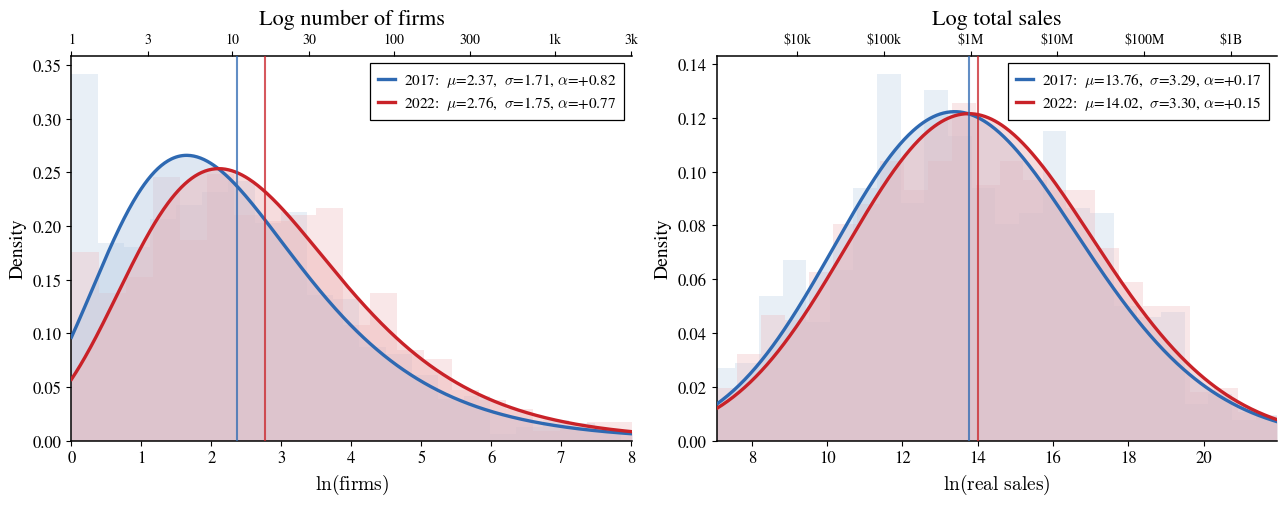

saved -> results/firm_growth_distributions/baseline_log_sales_2017_vs_2022.svg


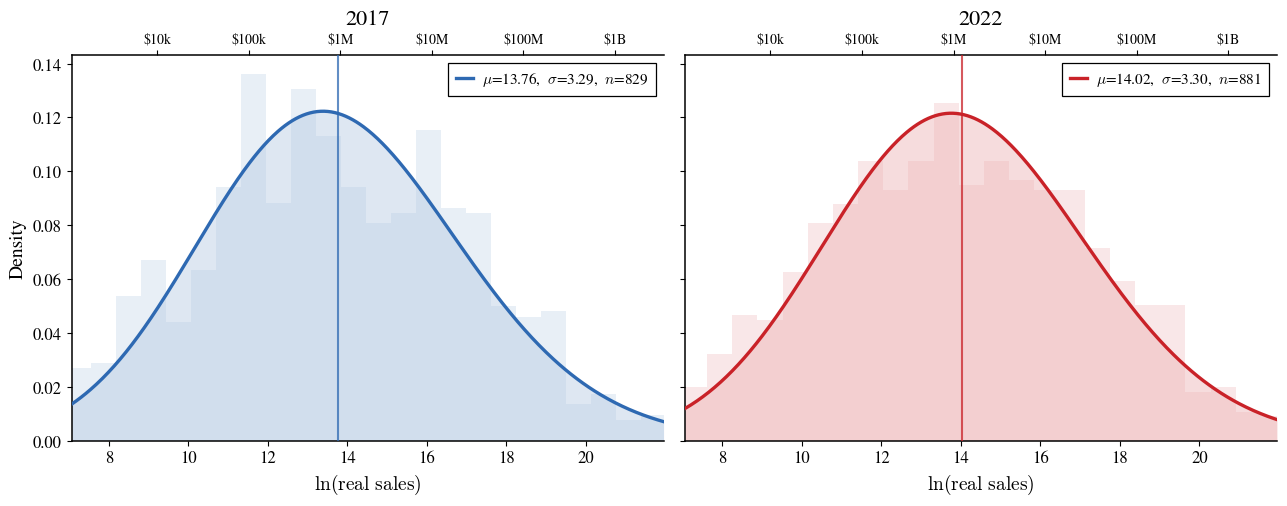

saved -> results/firm_growth_distributions/baseline_log_firms_2017_vs_2022.svg


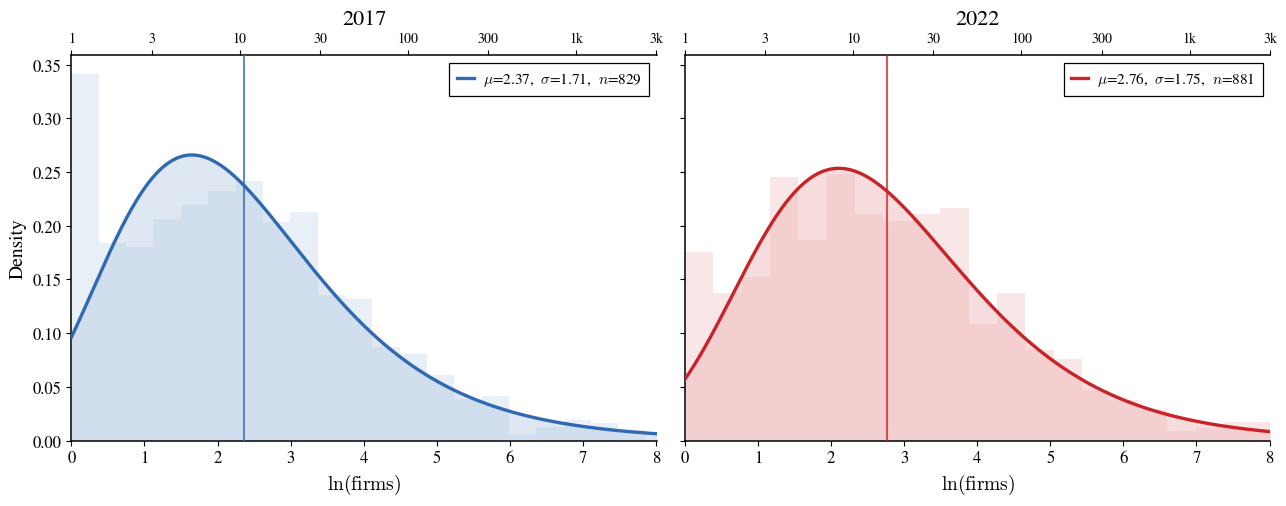


variable              year     n  mu=mean ln        exp(mu)         median     arith. mean              total
Log number of firms   2017   829       2.368           10.7            9.2           141.5          117,329.2
Log number of firms   2022   881       2.764           15.9           13.6           214.6          189,072.2
Log total sales       2017   829      13.758        943,837        790,996     162,023,616    134,317,577,821
Log total sales       2022   881      14.018      1,224,116      1,088,922     193,698,979    170,648,800,354
exp(mu) = geometric mean = the typical parish; the arithmetic mean is the total spread over parishes and sits far out in the right tail.


In [3]:
# ==============================================================================
# STEP D (cont.) -- BASELINE: the LEVEL distributions we start from, in logs
# ------------------------------------------------------------------------------
# Before any growth rate or decomposition: what do the two raw ingredients look
# like ACROSS PARISHES at the start (2017) and at the end of the last full year
# (2022)? Both in natural logs -- in levels the mean sits ~200x above the median
# (Quito alone is 44 bn $ / 35k firms), so only the log scale is readable.
#   Figure 1: log real sales | log firms, both years overlaid
#   Figure 2: log real sales, 2017 | 2022 in their own panels
#   Figure 3: log firms,      2017 | 2022 in their own panels
# Each curve is a fitted CONTINUOUS density -- fit_both()'s skew-t (a skewed
# Student-t: fat tails + asymmetry, the Gaussian is nested in it), drawn over a
# light histogram of the data it was fitted to, with that year's MEAN as a
# vertical line in the same colour. The AIC verdict skew-t vs Gaussian is
# printed, not drawn. Colours are the notebook's period pair (earlier year blue,
# later year red) from the STEP D palette. Each year uses its OWN valid parish
# set (firms > 0, real sales above the $1,000 floor), so n differs a little
# between years.
# The TOP axis of every panel repeats the log axis in real units (firms,
# dollars), and the print-out underneath converts each fitted mean back to a
# level -- exp(mean of ln x) is the GEOMETRIC mean, i.e. the typical parish, not
# the average one. Saved as SVG (vector).
# ==============================================================================
plt.rcParams.update({
    "font.family":      "STIXGeneral",
    "mathtext.fontset": "cm",
    "axes.titlesize":   16,
    "axes.labelsize":   14,
    "xtick.labelsize":  12,
    "ytick.labelsize":  12,
    "axes.linewidth":   1.1,
    "axes.edgecolor":   "black",
})

#                 year   line colour   fill colour
BASELINE_YEARS = [(2017, C_EARLY, tint(C_EARLY)),
                  (2022, C_LATE,  tint(C_LATE))]

#            table  panel title            x label     top-axis ticks (real units)
LOG_VARS = [(FIRMS, "Log number of firms", X_LNFIRMS, FIRM_TICKS,  FIRM_LABELS),
            (SALES, "Log total sales",     X_LNSALES, SALES_TICKS, SALES_LABELS)]


def log_levels(table, year):
    """ln of one value per parish valid in `year` (its own cross-section)."""
    return np.log(table.loc[sorted(VALID[year]), year].dropna().values)


def draw_fit(ax, x, f, label, line_c, fill_c, xg):
    """Light histogram, the skew-t density of the fit `f` already made for x, and
    that distribution's mean as a vertical line in its own colour -- drawn over
    the fill, which at zorder 2 would otherwise wash it out."""
    pdf = f["st"].pdf(xg)
    ax.hist(x, bins=28, density=True, color=fill_c, alpha=0.30, lw=0, zorder=1)
    ax.plot(xg, pdf, color=line_c, lw=2.4, zorder=3, label=label)
    ax.fill_between(xg, pdf, color=fill_c, alpha=0.45, lw=0, zorder=2)
    ax.axvline(x.mean(), color=line_c, lw=1.5, ls="-", alpha=0.75, zorder=4)


def style_dist_axis(ax, title, xlab):
    ax.set_title(title)
    ax.set_xlabel(xlab)
    ax.set_ylabel("Density")
    ax.set_ylim(bottom=0)
    leg = ax.legend(loc="upper right", fontsize=11, frameon=True, fancybox=False,
                    edgecolor="black", framealpha=1.0, handlelength=1.1,
                    handletextpad=0.6, borderpad=0.5, labelspacing=0.35)
    leg.get_frame().set_linewidth(0.9)


# ---- figure 1: log firms | log sales, both years overlaid --------------------
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2))
for ax, (table, title, xlab, ticks, tlabels) in zip(axes, LOG_VARS):
    data = {y: log_levels(table, y) for y, *_ in BASELINE_YEARS}
    pooled = np.concatenate(list(data.values()))
    lo, hi = np.percentile(pooled, [0.5, 99.5])
    xg = np.linspace(lo, hi, 500)
    for year, line_c, fill_c in BASELINE_YEARS:
        x = data[year]
        f = fit_both(x)                      # fitted first: the legend quotes it
        draw_fit(ax, x, f, f"{year}:  $\\mu$={x.mean():.2f},  $\\sigma$={x.std():.2f}, $\\alpha$={f['skew']:+.2f}",
                 line_c, fill_c, xg)
        print(f"{title:22s} {year}:  skew-t tail index = {f['tail']:.1f},  "
              f"skew = {f['skew']:+.2f},  AIC favours {f['better']} "
              f"(dAIC = {f['dAIC']:+.0f})")
    ax.set_xlim(lo, hi)
    style_dist_axis(ax, title, xlab)
    add_level_axis(ax, ticks, tlabels)

fig.tight_layout()
fig.savefig(GROWTH_DIR / "baseline_logs_2017_2022.svg", bbox_inches="tight")
print("saved ->", GROWTH_DIR / "baseline_logs_2017_2022.svg")
plt.show()

# ---- figures 2 & 3: one panel per year, sales then firms ---------------------
for table, stem, xlab, ticks, tlabels in [
        (SALES, "baseline_log_sales", X_LNSALES, SALES_TICKS, SALES_LABELS),
        (FIRMS, "baseline_log_firms", X_LNFIRMS, FIRM_TICKS,  FIRM_LABELS)]:
    data = {y: log_levels(table, y) for y, *_ in BASELINE_YEARS}
    pooled = np.concatenate(list(data.values()))
    lo, hi = np.percentile(pooled, [0.5, 99.5])
    xg = np.linspace(lo, hi, 500)

    fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2), sharey=True)
    for ax, (year, line_c, fill_c) in zip(axes, BASELINE_YEARS):
        x = data[year]
        draw_fit(ax, x, fit_both(x),
                 f"$\\mu$={x.mean():.2f},  $\\sigma$={x.std():.2f},  $n$={len(x):,}",
                 line_c, fill_c, xg)
        ax.set_xlim(lo, hi)
        style_dist_axis(ax, str(year), xlab)
        add_level_axis(ax, ticks, tlabels)
    axes[1].set_ylabel("")

    fig.tight_layout()
    out = GROWTH_DIR / f"{stem}_{BASELINE_YEARS[0][0]}_vs_{BASELINE_YEARS[1][0]}.svg"
    fig.savefig(out, bbox_inches="tight")
    print("saved ->", out)
    plt.show()

# ---- what the fitted mu and sigma are, back in firms and dollars -------------
# exp(mean of ln x) is the GEOMETRIC mean: the typical parish, the one the fitted
# curve is centred on. The arithmetic mean is a different (much larger) animal --
# it is the national total divided by the number of parishes, and it lives out in
# the right tail where Quito and Guayaquil are. Quoting both is the whole point.
DECIMALS = {"Log number of firms": 1, "Log total sales": 0}   # firm counts are
                                                             # monthly averages
print(f"\n{'variable':20s} {'year':>5s} {'n':>5s} {'mu=mean ln':>11s} "
      f"{'exp(mu)':>14s} {'median':>14s} {'arith. mean':>15s} {'total':>18s}")
for table, title, *_ in LOG_VARS:
    for year, *_ in BASELINE_YEARS:
        levels = table.loc[sorted(VALID[year]), year].dropna()
        x, dp = np.log(levels.values), DECIMALS[title]
        print(f"{title:20s} {year:5d} {len(x):5,d} {x.mean():11.3f} "
              f"{np.exp(x.mean()):14,.{dp}f} {levels.median():14,.{dp}f} "
              f"{levels.mean():15,.{dp}f} {levels.sum():18,.{dp}f}")
print("exp(mu) = geometric mean = the typical parish; the arithmetic mean is the "
      "total spread over parishes and sits far out in the right tail.")

## Putting the numbers back in: real units, and the year as the unit of time

Two things the figures above cannot tell you, and both are fixable without changing a single result.

**What a log is worth.** Every distribution in this notebook is in natural logs, because a variable whose top parish is 4,000 times its median has no readable linear axis. But nothing in a log figure is quotable: $\mu = 13.76$ is not a dollar amount. Three conversions close that gap, and the next cell prints all three:

$$\exp(\mu) = \text{geometric mean} \ne \bar x = \text{arithmetic mean}, \qquad \exp(\sigma) = \text{the multiplicative width}, \qquad \exp(\Delta\ln x) = \text{the multiple}$$

The gap between the first two *is* the concentration: the typical (geometric-mean) parish had **10.7 firms** in 2017, the average parish had **141.5** — thirteen times more — because the average is the national total spread over parishes and it sits out in the tail where Quito and Guayaquil are. When the paper says "the typical parish", it means the first number. Every panel below also carries a **second x-axis along the top** in firms, dollars, or multiples, so no figure has to be read in logs alone.

**Why the year and not the month.** The monthly series (STEP I, further down) is the honest raw data and is unusable as a growth story: month-to-month the real-sales flow moves with a standard deviation of **11.5%**, and *every* December is between **+14% and +27%** above its November — seven Decembers, seven spikes. That is the calendar, not the economy. A calendar year contains exactly one of each month, so summing to years removes the seasonal term exactly rather than filtering it approximately, and it is also the grain the decomposition reports in, which keeps this figure and the selection/transmission numbers on one clock. The firm *stock* is quieter (1.7% a month) but gets the same treatment for symmetry.

In [4]:
# ==============================================================================
# STEP D (cont.) -- THE SAME ECONOMY IN REAL UNITS: firms and dollars
# ------------------------------------------------------------------------------
# Everything above and below this cell is in logs, because that is the only
# scale a distribution over 900 parishes is readable on. The cost is that no
# number in those figures is a number anyone can quote. This cell pays that back
# and draws nothing: it prints the levels the logs came from.
#   TABLE 1  the national totals, year by year: how many formal firms, how many
#            real dollars of sales, how much sales per firm, and the year-over-
#            year change in percent (not log points).
#   TABLE 2  the parish cross-section, year by year: how big the typical parish
#            is at the median and at the 10th/90th percentile.
#   TABLE 3  the log-to-level dictionary for the baseline figures -- what each
#            fitted mu, and a one-sigma move away from it, is worth in firms and
#            in dollars.
# Two conventions, both inherited from the engine and worth restating because
# they decide what the levels MEAN:
#   * a parish's firm count in a year is the MEAN of its 12 monthly stocks (a
#     stock, not a flow -- it is not "firms created"), so it is a fraction;
#   * sales are REAL, deflated to constant-2025 dollars by the IPC factor, and
#     summed over the 12 months, so a year's sales is a flow.
# Table 1 uses every parish present in a year; the cross-section tables use the
# decomposition's valid set (firms > 0 and real sales > $1,000), which is why
# their totals are a hair lower.
# Saved as CSV next to the figures, so the numbers can be quoted from the file.
# ==============================================================================

# ---- table 1: the country, year by year --------------------------------------
LEVELS_BY_YEAR = (py[py["year"].isin(YEARS)]
                  .groupby("year")
                  .agg(parishes=("cod_parr", "nunique"),
                       firms=("firms", "sum"),
                       real_sales=("sales", "sum")))
LEVELS_BY_YEAR["sales_per_firm"] = (LEVELS_BY_YEAR["real_sales"]
                                    / LEVELS_BY_YEAR["firms"])
# percent change is what people quote; log points are what the decomposition
# reports. exp(log points) - 1 = the percent change, and the two only agree for
# small moves -- hence both columns.
for col in ["firms", "real_sales", "sales_per_firm"]:
    LEVELS_BY_YEAR[f"{col}_pct"] = LEVELS_BY_YEAR[col].pct_change() * 100
    LEVELS_BY_YEAR[f"{col}_dln"] = np.log(LEVELS_BY_YEAR[col]).diff()

def pct(v, width=8):
    """A percent change, or a dash for the first year (nothing to compare to)."""
    return f"{'--':>{width}s}" if pd.isna(v) else f"{v:{width - 1}.1f}%"


print("NATIONAL LEVELS, all parishes present in the year")
print(f"{'year':>5s} {'parishes':>9s} {'firms':>12s} {'firms %':>9s} "
      f"{'real sales':>14s} {'sales %':>9s} {'sales/firm':>12s} {'s/f %':>8s}")
for y, r in LEVELS_BY_YEAR.iterrows():
    print(f"{y:5d} {r['parishes']:9,.0f} {r['firms']:12,.0f} "
          f"{pct(r['firms_pct'], 9)} {r['real_sales']/1e9:12,.1f}bn "
          f"{pct(r['real_sales_pct'], 9)} {r['sales_per_firm']:12,.0f} "
          f"{pct(r['sales_per_firm_pct'])}")

first, last = YEARS[0], YEARS[-1]
span = LEVELS_BY_YEAR.loc[last] / LEVELS_BY_YEAR.loc[first]
print(f"\n{first} -> {last}:  firms x{span['firms']:.2f} "
      f"({LEVELS_BY_YEAR.loc[first, 'firms']:,.0f} -> "
      f"{LEVELS_BY_YEAR.loc[last, 'firms']:,.0f}),  real sales "
      f"x{span['real_sales']:.2f} (${LEVELS_BY_YEAR.loc[first, 'real_sales']/1e9:.1f}bn "
      f"-> ${LEVELS_BY_YEAR.loc[last, 'real_sales']/1e9:.1f}bn),  sales per firm "
      f"x{span['sales_per_firm']:.2f} "
      f"(${LEVELS_BY_YEAR.loc[first, 'sales_per_firm']:,.0f} -> "
      f"${LEVELS_BY_YEAR.loc[last, 'sales_per_firm']:,.0f})")
print("Compound annual rates: firms "
      f"{(span['firms'] ** (1 / (last - first)) - 1) * 100:+.1f}%/yr, real sales "
      f"{(span['real_sales'] ** (1 / (last - first)) - 1) * 100:+.1f}%/yr.")

# ---- table 2: the parish cross-section, year by year -------------------------
print("\nTHE TYPICAL PARISH (valid set: firms > 0 and real sales > $1,000)")
print(f"{'year':>5s} {'n':>5s} {'firms p10':>10s} {'median':>8s} {'p90':>8s} "
      f"{'sales p10':>12s} {'median':>12s} {'p90':>12s}")
for y in YEARS:
    v = sorted(VALID[y])
    f, s = FIRMS.loc[v, y], SALES.loc[v, y]
    print(f"{y:5d} {len(v):5,d} {f.quantile(.10):10.1f} {f.median():8.1f} "
          f"{f.quantile(.90):8.1f} {s.quantile(.10)/1e6:11.2f}m "
          f"{s.median()/1e6:11.2f}m {s.quantile(.90)/1e6:11.2f}m")

# ---- table 3: what mu and sigma are worth in firms and dollars ---------------
# In a log figure the fitted mu is NOT the average parish: exp(mu) is the
# geometric mean, the middle of the distribution the curve is drawn on. sigma is
# multiplicative -- one sigma to the right multiplies by exp(sigma), not adds.
print("\nREADING THE BASELINE FIGURES IN LEVELS")
for table, name, unit in [(FIRMS, "firms", ""), (SALES, "real sales", "$")]:
    for year, *_ in BASELINE_YEARS:
        x = np.log(table.loc[sorted(VALID[year]), year].dropna().values)
        mu, sd = x.mean(), x.std()
        print(f"  {name:10s} {year}:  mu = {mu:6.3f} -> {unit}{np.exp(mu):,.0f}"
              f"   one sigma = {sd:.2f} -> x{np.exp(sd):.2f} "
              f"(so mu+/-sigma spans {unit}{np.exp(mu - sd):,.0f} to "
              f"{unit}{np.exp(mu + sd):,.0f})")

out_csv = GROWTH_DIR / "levels_by_year.csv"
LEVELS_BY_YEAR.round(4).to_csv(out_csv)
print("\nsaved ->", out_csv)

NATIONAL LEVELS, all parishes present in the year
 year  parishes        firms   firms %     real sales   sales %   sales/firm    s/f %
 2017       884      117,485        --        134.3bn        --    1,143,270       --
 2018       918      129,689     10.4%        142.0bn      5.7%    1,094,555    -4.3%
 2019       943      142,891     10.2%        143.5bn      1.1%    1,004,090    -8.3%
 2020       937      152,442      6.7%        125.3bn    -12.7%      821,989   -18.1%
 2021       954      169,831     11.4%        153.9bn     22.8%      906,366    10.3%
 2022       972      189,299     11.5%        170.6bn     10.9%      901,476    -0.5%
 2023       973      204,390      8.0%        175.1bn      2.6%      856,476    -5.0%

2017 -> 2023:  firms x1.74 (117,485 -> 204,390),  real sales x1.30 ($134.3bn -> $175.1bn),  sales per firm x0.75 ($1,143,270 -> $856,476)
Compound annual rates: firms +9.7%/yr, real sales +4.5%/yr.

THE TYPICAL PARISH (valid set: firms > 0 and real sales > $1,0

saved -> results/firm_growth_distributions/national_monthly_log_levels.svg


saved -> results/firm_growth_distributions/national_monthly_log_levels.png


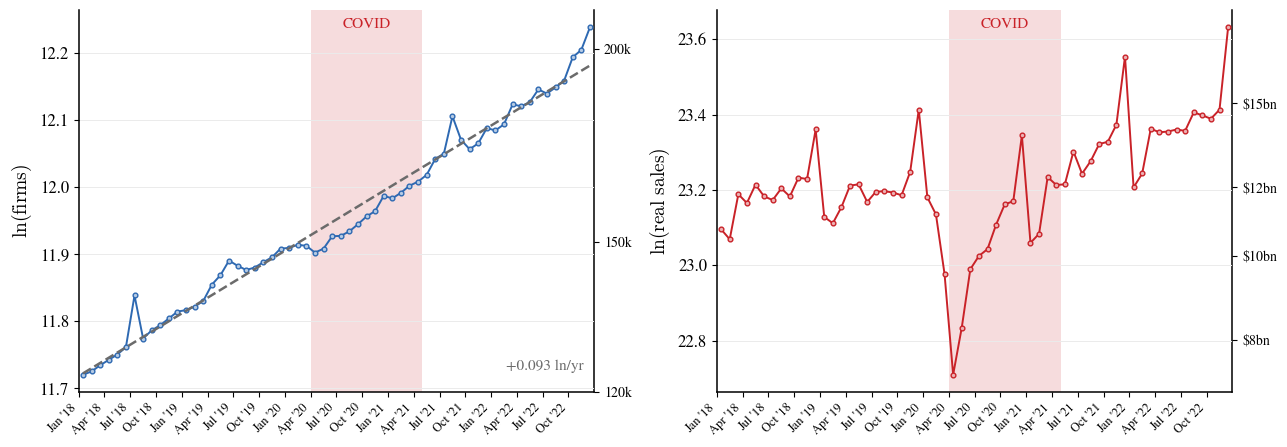

span 2018M01-2022M12 (60 months)
      ln(firms): slope +0.0934 ln/yr = +9.79%/yr, R^2 0.979, residual sd 2.0%, mean residual inside the COVID band -2.2%
 ln(real sales): slope +0.0516 ln/yr = +5.30%/yr, R^2 0.241, residual sd 13.2%, mean residual inside the COVID band -15.8%

real sales with month dummies (calendar removed): slope +0.0428 ln/yr = +4.38%/yr, R^2 0.498 -- the raw sawtooth R^2 above is low because of December, not because the trend is absent.

ln(firms) slope before the band +9.78%/yr, after it +11.74%/yr; 2022M12 sits +5.1% off the pre-COVID line extended -- how much of the shock is a level shift and how much a change of rate.


In [5]:
# ==============================================================================
# STEP D (cont.) -- THE MONTHLY SERIES IN LOGS: is the growth exponential?
# ------------------------------------------------------------------------------
# The cell above summed to calendar years to kill the seasonality. This one goes
# back to the raw monthly grain but plots it in NATURAL LOGS, where the question
# "is this exponential growth?" becomes a question about a straight line: a
# constant proportional growth rate is a straight line in log space, and its
# slope IS that rate (slope b per year -> e^b - 1 percent per year).
#   LEFT   ln(firms), the national monthly stock, one dot per month, with an OLS
#          line through it; the only number on the figure is that line's slope.
#   RIGHT  ln(real sales), the monthly flow. No line: the December spike makes
#          this series a sawtooth, so a straight line through it would be
#          fitting the calendar as much as the trend. The de-seasonalised slope
#          (same regression plus month dummies) is printed to stdout instead.
# The red band is the COVID window. Window, span and tick spacing are the three
# parameters below -- everything else follows from them.
# ==============================================================================

SPAN_FROM,  SPAN_TO  = (2018, 1), (2022, 12)     # first and last month plotted
COVID_FROM, COVID_TO = (2020, 4), (2021,  4)     # first and last month shaded
TICK_EVERY = 3                                   # months between x tick labels


def _decimal_year(y, m, end=False):
    """Month (y, m) as a position on the year axis, matching month_x above:
    the month occupies [y+(m-1)/12, y+m/12); `end` returns its right edge."""
    return y + (m - 1 + (1 if end else 0)) / 12


def _month_label(y, m):
    """(2018, 1) -> "Jan '18"."""
    return f"{pd.Timestamp(y, m, 1):%b} '{y % 100:02d}"


def add_real_yaxis(ax, money=False):
    """Repeat a log y-axis on the RIGHT in real units (firms, or dollars/month),
    so a reader never has to exponentiate 11.9 in their head. The ticks are round
    NUMBERS (150k firms, \\$12bn) placed at their logs -- the mirror image of
    add_level_axis above, which does the same to an x-axis."""
    lo, hi = np.exp(ax.get_ylim())
    nice = [m * 10.0 ** k for k in range(0, 12) for m in (1, 1.2, 1.5, 2, 2.5, 3, 4, 5, 6, 8)]
    ticks = [v for v in nice if lo <= v <= hi]

    def human(v):
        for div, suf in ((1e9, "bn"), (1e6, "M"), (1e3, "k"), (1, "")):
            if v >= div:
                return ("\\$" if money else "") + f"{v/div:g}{suf}"
        return f"{v:g}"

    right = ax.secondary_yaxis("right")
    right.set_yticks(np.log(ticks))
    right.set_yticklabels([human(v) for v in ticks], fontsize=10)
    return right


# ---- the window actually plotted ---------------------------------------------
SPAN = MONTHLY_NAT.loc[f"{SPAN_FROM[0]}M{SPAN_FROM[1]:02d}":f"{SPAN_TO[0]}M{SPAN_TO[1]:02d}"]
span_x = np.array([_decimal_year(int(t[:4]), int(t[5:])) + 0.5 / 12 for t in SPAN.index])
span_ym = [(int(t[:4]), int(t[5:])) for t in SPAN.index]      # (year, month) per point

#            monthly series                 colour    y label      fit?
SERIES_LN = [(SPAN["total_firms"], C_FIRMS, X_LNFIRMS, True),
             (SPAN["real_sales"],  C_SALES, X_LNSALES, False)]

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6))
for ax, (s, color, ylab, do_fit) in zip(axes, SERIES_LN):
    y = np.log(s.values)

    # the COVID band, drawn first so the series sits on top of it, named at its
    # top centre (x in data coords, y in axes fraction -- so the label rides the
    # top of the panel whatever the y limits are)
    band = (_decimal_year(*COVID_FROM), _decimal_year(*COVID_TO, end=True))
    ax.axvspan(*band, facecolor=tint(ERA_COLORS["COVID"], 0.16), lw=0, zorder=0)
    ax.text(sum(band) / 2, 0.98, "COVID", transform=ax.get_xaxis_transform(),
            ha="center", va="top", color=ERA_COLORS["COVID"], fontsize=11)

    ax.plot(span_x, y, lw=1.4, color=color, marker="o", ms=3.4,
            mfc=tint(color), mec=color, mew=1.0, zorder=3)

    if do_fit:
        b, a = np.polyfit(span_x, y, 1)                # ln(x) = a + b * year
        ax.plot(span_x, a + b * span_x, lw=1.8, ls="--", color=GREY, zorder=4)
        # the one number on the figure: the slope, i.e. the growth rate itself.
        # It goes in the corner under the line (empty by construction -- the line
        # rises left to right) and in the line's own grey, so no label is needed.
        ax.text(0.98, 0.05, f"{b:+.3f} ln/yr", transform=ax.transAxes,
                ha="right", va="bottom", color=GREY, fontsize=11)

    ax.set_ylabel(ylab)
    ax.set_xlim(_decimal_year(*SPAN_FROM), _decimal_year(*SPAN_TO, end=True))
    ticks = span_ym[::TICK_EVERY]
    ax.set_xticks([_decimal_year(*ym) for ym in ticks])
    ax.set_xticklabels([_month_label(*ym) for ym in ticks], rotation=45,
                       ha="right", fontsize=9)
    ax.grid(axis="y", color="0.92", lw=0.7)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    add_real_yaxis(ax, money=(color == C_SALES))

fig.tight_layout()
for ext in ("svg", "png"):
    fig.savefig(GROWTH_DIR / f"national_monthly_log_levels.{ext}", bbox_inches="tight")
    print("saved ->", GROWTH_DIR / f"national_monthly_log_levels.{ext}")
plt.show()

# ---- the numbers behind the straight line ------------------------------------
# A log-linear fit is a claim about a CONSTANT growth rate, so what matters is
# not only the slope but how little of the series it leaves unexplained (R^2)
# and how big the misses are in percent (the residual sd).
covid = ((span_x >= _decimal_year(*COVID_FROM)) &
         (span_x <= _decimal_year(*COVID_TO, end=True)))
print(f"span {SPAN.index[0]}-{SPAN.index[-1]} ({len(SPAN)} months)")
for name, s in (("ln(firms)", SPAN["total_firms"]),
                ("ln(real sales)", SPAN["real_sales"])):
    y = np.log(s.values)
    b, a = np.polyfit(span_x, y, 1)
    resid = y - (a + b * span_x)
    r2 = 1 - resid.var() / y.var()
    print(f"{name:>15s}: slope {b:+.4f} ln/yr = {(np.exp(b)-1)*100:+.2f}%/yr, "
          f"R^2 {r2:.3f}, residual sd {resid.std()*100:.1f}%, "
          f"mean residual inside the COVID band {resid[covid].mean()*100:+.1f}%")

# the sales trend once the calendar is taken out: same regression + month dummies
mo = np.array([m for _, m in span_ym])
X = np.column_stack([np.ones_like(span_x), span_x] +
                    [(mo == k).astype(float) for k in range(2, 13)])
ys = np.log(SPAN["real_sales"].values)
beta, *_ = np.linalg.lstsq(X, ys, rcond=None)
r2_ds = 1 - (ys - X @ beta).var() / ys.var()
print(f"\nreal sales with month dummies (calendar removed): "
      f"slope {beta[1]:+.4f} ln/yr = {(np.exp(beta[1])-1)*100:+.2f}%/yr, R^2 {r2_ds:.3f} "
      f"-- the raw sawtooth R^2 above is low because of December, not because the trend is absent.")

# does the firm series bend at COVID? fit the two sides separately and ask how
# far the pre-COVID line misses the last month in the span.
yf = np.log(SPAN["total_firms"].values)
pre, post = span_x < _decimal_year(*COVID_FROM), span_x > _decimal_year(*COVID_TO, end=True)
bp, ap = np.polyfit(span_x[pre], yf[pre], 1)
bq, _ = np.polyfit(span_x[post], yf[post], 1)
print(f"\nln(firms) slope before the band {(np.exp(bp)-1)*100:+.2f}%/yr, "
      f"after it {(np.exp(bq)-1)*100:+.2f}%/yr; "
      f"{SPAN.index[-1]} sits {(yf[-1]-(ap+bp*span_x[-1]))*100:+.1f}% "
      f"off the pre-COVID line extended -- how much of the shock is a level shift "
      f"and how much a change of rate.")

### The economy behind the distributions, in numbers anyone can quote

- **The size of the thing.** Ecuador's formal economy went from **117,485 firms and \$134.3bn of real sales in 2017** to **204,390 firms and \$175.1bn in 2023** — firms ×1.74 (**+9.7% a year**, compounded), real sales ×1.30 (**+4.5% a year**). Over the two baseline years the median parish went from **9.2 firms and \$0.79m** of annual real sales to **13.6 firms and \$1.09m**.
- **The two series are not the same story, and the ratio says so.** Real sales per firm fell from **\$1.14m to \$0.86m, −25% over six years**, and it fell in every single year except the 2021 rebound (−4.3, −8.3, −18.1, +10.3, −0.5, −5.0%). Ecuador added firms about three times faster than it added revenue. Whatever the formalization wave of these years was, it was not an expansion of average firm size.
- **The year the two margins split.** 2020 is the only negative bar in the figure: real sales **−12.7%**, while the firm count still grew **+6.7%**. Nobody deregistered; the flow through the registered firms collapsed. That single fact is what the decomposition later reads as a large negative transmission with the *selection* term going the other way.
- **The stall is at the end, not at the shock.** 2021 (+11.4% firms, +22.8% sales) and 2022 (+11.5%, +10.9%) are the strongest years in the panel. 2023 is where both decelerate together (+8.0%, +2.6%) — the post-COVID stall the moments panel and the entry regressions both flag independently.
- **A word on what "firms" counts.** A parish-year firm count is the *mean of its twelve monthly stocks* of active RUCs, so it is a stock and it is fractional (a parish can have 9.2 firms). It is not a count of firms created, and none of the growth numbers here should be read as gross firm creation — see the entry cell below for what can and cannot be claimed on that.

## From the levels to the change — $\Delta\ln(\mathrm{firms})$ and $\Delta\ln(\mathrm{sales})$

The baseline cell drew where the parishes *stand* in each of the two years. This one draws how far each parish *moved* between them:

$$\Delta\ln(\mathrm{firms})_p = \ln N_p(y_1) - \ln N_p(y_0), \qquad \Delta\ln(\mathrm{real\ sales})_p = \ln S_p(y_1) - \ln S_p(y_0)$$

**Why this difference is legitimate and a difference of the two densities is not.** Subtracting the 2017 density from the 2022 density compares two *populations* standing in different places — the parishes that moved right and the parishes that moved left cancel inside the same bin, and nothing in the result belongs to any particular parish. Subtracting a parish's own two logs follows *that parish*: it is a within-unit difference, and the histogram of those 808 numbers is a genuine distribution of changes. (This is the same argument that licenses differencing firm *counts* per parish in the entry cell below, and forbids differencing sales *densities* to recover entrants' revenue.)

**Reading the axis.** $\Delta\ln$ is unitless and additive, which is why the decomposition lives in it; $\exp(\Delta\ln)$ is the multiple, which is what the top axis of each panel shows. $0$ means unchanged, $+0.69$ means doubled, $-0.69$ means halved. It is *not* a percentage: $+0.52$ is +68%, not +52%, and the two only agree for small moves.

### What the two change distributions say

- **Firms: a narrow bump almost entirely to the right of zero.** Over 2017→2022 the typical parish multiplied its firm stock by **×1.64** (median $\Delta\ln = +0.49$; mean $+0.52$, i.e. ×1.68), with $\sigma = 0.44$ and **90.0% of parishes above zero**. Formalization is the one thing in this data that happened almost everywhere: only 8% of parishes ended the window with fewer firms than they started with.
- **Sales: the same centre, three times the spread, and a fat left tail.** Real sales moved by a nearly identical mean (+0.50, ×1.64) but with $\sigma = 1.34$ — **three times wider** — and only **73.8% of parishes above zero**, with a tail index of 1.7 against 3.9 for firms. Where a parish lands in the revenue distribution is a far more violent lottery than whether it gains firms. Read together with the levels table, that is the extensive/intensive margin split stated as two distributions: the extensive margin (firms) is broad and reliable, the intensive margin (revenue per place) is narrow-centred and heavy-tailed.
- **The two changes barely travel together.** Across parishes $\mathrm{corr}(\Delta\ln N, \Delta\ln S) = +0.28$ over the window, and only $+0.09$ to $+0.26$ in any single year. Knowing that a parish added firms tells you almost nothing about whether its revenue grew — which is exactly why the decomposition needs both a fitness (firm growth) and a trait (log sales) and cannot be run on one of them.
- **The year-by-year table isolates the shock cleanly.** Firm growth sits at $+0.14, +0.14$ per year before COVID, collapses to $+0.008$ with only 54% of parishes positive in 2019→20, recovers to $+0.13, +0.11$, and stalls again at $+0.016$ in 2022→23 — where it also turns **negatively skewed for the only time in the panel** ($\alpha = -0.47$), i.e. the stall is a left tail of losing parishes, not a uniform slowdown. Sales growth does something different in the same year: it stays positive (+0.165) while firms stop. The COVID year is the mirror image — sales $-0.230$ with two-thirds of parishes negative, firms flat.

## Where do the new firms go — do they pick the parishes that already have few?

Without firm identifiers we cannot see entrants. We *can* see the count of firms in a fixed cell in two years, and a count inside a fixed cell differences cleanly, because the cell is the same object in both years:

$$\Delta N_p \;=\; N_p(y_1) - N_p(y_0) \;=\; \underbrace{\text{entries}}_{\text{want}} \;-\; \underbrace{\text{exits}}_{\text{leak 1}} \;\pm\; \underbrace{\text{reclassifications}}_{\text{leak 2}}$$

So the object below is **net entry per parish** — never gross entry, which no method recovers from anonymous counts. The distance between the two is measurable and is printed before anything is drawn: over 2017→2022 the firms lost in shrinking parishes are **0.1% of the firms gained in growing ones**, so at the national aggregate net ≈ gross. Inside a growing parish, entries and exits still cancel invisibly; that is a limit of the data, not of the method.

**The question has two answers and they are not the same answer.**

$$\underbrace{\Delta\ln N_p \;=\; a + b\,\ln N_p(y_0)}_{\textbf{rate: who grows fastest}} \qquad\qquad \underbrace{\frac{\Delta N_d}{\sum_d \Delta N_d} \Big/ \frac{N_d(y_0)}{\sum_d N_d(y_0)}}_{\textbf{mass: who absorbs the cohort, by initial-size decile } d}$$

A parish that goes from 1 firm to 3 has a spectacular *rate* ($\Delta \ln N = +1.1$) and contributes 2 firms to the *mass*. Both panels are drawn because a claim about "new firms going to small places" is ambiguous between them, and the two give different answers here.

**One trap, handled.** Regressing growth on the initial level is mechanically tilted negative — any noise in $N_p(y_0)$ raises the x-axis and lowers the y-axis at the same time (Galton's regression fallacy), so $b < 0$ can appear with no economics behind it. The print-out repeats every regression sorting parishes by an **earlier** year's stock, whose measurement noise is not in the window; a slope that survives that swap is not a mean-reversion artifact.

saved -> results/firm_growth_distributions/entry_vs_initial_size_2017_2022.svg


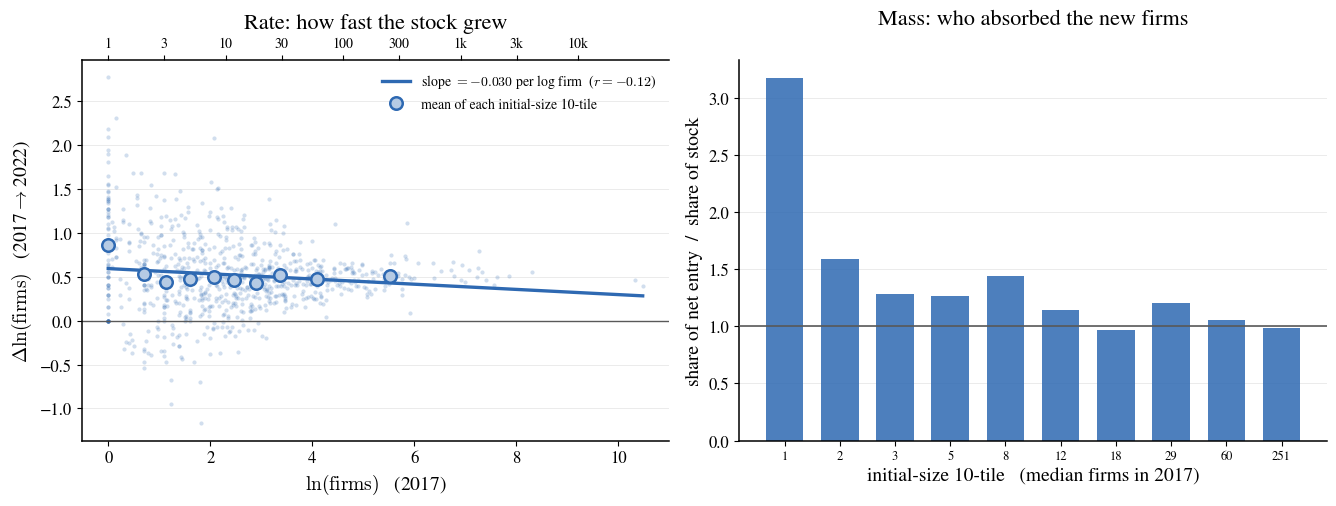

NET ENTRY 2017 -> 2022:  +71,555 firms across 808 parishes (117,294 -> 188,849).
  8.2% of parishes ended with fewer firms; the firms they lost are 0.1% of the firms the growing parishes gained (the net-vs-gross gap).
  Delta ln N on ln N(2017): slope -0.0296 (se 0.0090, p = 1.0e-03, R2 = 0.013). A parish ten times bigger grew -0.068 log points less over the window, against a mean of +0.521 and a spread of 0.437.

tile  parishes  median N0      stock  net added  mean dlnN  stock sh  entry sh  ratio
   1        81        1.0         83       +161     +0.863    0.07%    0.22%   3.17
   2        81        2.0        152       +147     +0.530    0.13%    0.21%   1.59
   3        81        3.1        261       +204     +0.436    0.22%    0.29%   1.28
   4        80        5.0        407       +315     +0.474    0.35%    0.44%   1.27
   5        81        7.9        637       +559     +0.502    0.54%    0.78%   1.44
   6        81       11.8        960       +669     +0.458    0.82%    0.93%

2022->  23   861  +0.0118   2.3e-02 +0.0150 (2021)

              share of stock  share of net entry   own growth
Quito                 26.17%              25.53%       +0.467
Guayaquil             30.30%              23.88%       +0.393
Cuenca                 3.45%               4.21%       +0.556


In [6]:
# ==============================================================================
# STEP D (cont.) -- WHERE DO THE NEW FIRMS GO? Differencing counts, not densities
# ------------------------------------------------------------------------------
# WHAT THIS CAN AND CANNOT CLAIM. The data has no firm identifiers, so a
# difference of two years identifies NET entry only:
#     Delta N_p = N_p(y1) - N_p(y0) = entries - exits +/- reclassifications
# Gross entry is unrecoverable without micro data. What differences cleanly is a
# COUNT inside a fixed cell (a parish), because the cell is the same object in
# both years; what does NOT difference cleanly is a DENSITY (subtracting the
# 2017 sales distribution from the 2022 one), because incumbents move within it
# between years and the subtraction mixes their motion with entry inseparably.
# So: counts, per parish. The negative mass -- firms lost in shrinking parishes
# as a share of firms gained in growing ones -- is printed below, and it is the
# distance between "net" and "gross" that the reader is owed.
#
# THE QUESTION. Do the new firms go to parishes that already have many firms, or
# to parishes that have few? Two answers, and they are not the same answer:
#   RATE (left panel)  Delta ln N regressed on ln N(y0). A negative slope means
#     small parishes grow their firm stock FASTER in percentage terms. This is
#     the firm-count twin of the decomposition's selection term, which is
#     negative for the same reason.
#   MASS (right panel) each initial-size decile's share of the net firms added,
#     against its share of the firms that existed at y0. A ratio above 1 means
#     the decile absorbed more of the cohort than its size entitled it to.
# A rate can be spectacular on a base of one firm and still be invisible in the
# mass. Both panels are drawn because the honest answer needs both.
#
# ONE TRAP, HANDLED. Regressing growth on the initial level is mechanically
# tilted negative: any noise in N(y0) enters the x-axis positively and the y-axis
# negatively (Galton's regression fallacy). The print-out repeats the regression
# sorting parishes by an EARLIER year's stock instead, whose noise is
# independent of the window -- if the slope survives, the tilt is real.
# ENTRY_WINDOW and N_BINS are parameters.
# ==============================================================================
ENTRY_WINDOW = (BASELINE_YEARS[0][0], BASELINE_YEARS[1][0])   # 2017 -> 2022
N_BINS = 10                                                   # deciles of initial size


def ols(x, y):
    """Plain OLS of y on x with a t-test on the slope. Returns the pieces the
    figures and the print-out quote, nothing more."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    b, a = np.polyfit(x, y, 1)
    resid = y - (a + b * x)
    se = np.sqrt((resid ** 2).sum() / (len(x) - 2) / ((x - x.mean()) ** 2).sum())
    return dict(slope=b, intercept=a, se=se, r=float(np.corrcoef(x, y)[0, 1]),
                p=float(2 * stats.t.sf(abs(b / se), len(x) - 2)), n=len(x))


def entry_table(y0, y1, n_bins=N_BINS):
    """One row per surviving parish: the stock it started with, the net firms it
    gained, its log growth, and which initial-size bin it falls in."""
    v = survivors(y0, y1)
    t = pd.DataFrame({"n0": FIRMS.loc[v, y0], "n1": FIRMS.loc[v, y1]})
    t["net"] = t["n1"] - t["n0"]
    t["dln"] = np.log(t["n1"] / t["n0"])
    # rank first, then cut: parish firm counts are the mean of 12 monthly stocks
    # and tie a lot at the small end, which plain qcut cannot split.
    t["bin"] = pd.qcut(t["n0"].rank(method="first"), n_bins, labels=False) + 1
    return t


E0, E1 = ENTRY_WINDOW
ent = entry_table(E0, E1)
fit = ols(np.log(ent["n0"]), ent["dln"])

by_bin = ent.groupby("bin").agg(parishes=("n0", "size"), med_n0=("n0", "median"),
                                stock=("n0", "sum"), net=("net", "sum"),
                                mean_dln=("dln", "mean"))
by_bin["stock_share"] = by_bin["stock"] / by_bin["stock"].sum()
by_bin["entry_share"] = by_bin["net"] / by_bin["net"].sum()
by_bin["ratio"] = by_bin["entry_share"] / by_bin["stock_share"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

# ---- left: the RATE view -----------------------------------------------------
ax = axes[0]
ax.scatter(np.log(ent["n0"]), ent["dln"], s=9, color=C_FIRMS, alpha=0.22,
           lw=0, zorder=1)
xg = np.linspace(np.log(ent["n0"]).min(), np.log(ent["n0"]).max(), 100)
ax.plot(xg, fit["intercept"] + fit["slope"] * xg, color=C_FIRMS, lw=2.4, zorder=3,
        label=f"slope $={fit['slope']:+.3f}$ per log firm  ($r={fit['r']:+.2f}$)")
ax.plot(np.log(by_bin["med_n0"]), by_bin["mean_dln"], ls="none", marker="o",
        ms=9, mfc=tint(C_FIRMS), mec=C_FIRMS, mew=1.8, zorder=4,
        label=f"mean of each initial-size {N_BINS}-tile")
ax.axhline(0, color="0.35", lw=1.0, zorder=2)
ax.set_xlabel(X_LNFIRMS + f"   ({E0})")
ax.set_ylabel(X_DFIRM + f"   ({E0}$\\to${E1})")
ax.set_title("Rate: how fast the stock grew")
add_level_axis(ax, FIRM_TICKS, FIRM_LABELS)     # the same axis in firms

# ---- right: the MASS view ----------------------------------------------------
ax = axes[1]
ax.bar(by_bin.index, by_bin["ratio"], width=0.68, color=C_FIRMS, alpha=0.85,
       zorder=2)
ax.axhline(1.0, color="0.35", lw=1.2, zorder=3)
ax.set_xticks(by_bin.index)
ax.set_xticklabels([f"{v:,.0f}" for v in by_bin["med_n0"]], rotation=0, fontsize=9)
ax.set_xlabel(f"initial-size {N_BINS}-tile   (median firms in {E0})")
ax.set_ylabel("share of net entry  /  share of stock")
# pad matches the height the left panel's second axis adds, so the two titles line up
ax.set_title("Mass: who absorbed the new firms", pad=26)

for ax in axes:
    ax.grid(axis="y", color="0.92", lw=0.7)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=10, loc="upper right")   # only the left
                                                                # panel has series

fig.tight_layout()
out = GROWTH_DIR / f"entry_vs_initial_size_{E0}_{E1}.svg"
fig.savefig(out, bbox_inches="tight")
print("saved ->", out)
plt.show()

# ---- the numbers -------------------------------------------------------------
print(f"NET ENTRY {E0} -> {E1}:  {ent['net'].sum():+,.0f} firms across "
      f"{len(ent):,} parishes ({ent['n0'].sum():,.0f} -> {ent['n1'].sum():,.0f}).")
print(f"  {(ent['net'] < 0).mean():.1%} of parishes ended with fewer firms; the "
      f"firms they lost are {-ent.loc[ent['net'] < 0, 'net'].sum() / ent.loc[ent['net'] > 0, 'net'].sum():.1%} "
      f"of the firms the growing parishes gained (the net-vs-gross gap).")
print(f"  Delta ln N on ln N({E0}): slope {fit['slope']:+.4f} "
      f"(se {fit['se']:.4f}, p = {fit['p']:.1e}, R2 = {fit['r'] ** 2:.3f}). "
      f"A parish ten times bigger grew {fit['slope'] * np.log(10):+.3f} log points "
      f"less over the window, against a mean of {ent['dln'].mean():+.3f} and a "
      f"spread of {ent['dln'].std():.3f}.")

print(f"\n{'tile':>4s} {'parishes':>9s} {'median N0':>10s} {'stock':>10s} "
      f"{'net added':>10s} {'mean dlnN':>10s} {'stock sh':>9s} {'entry sh':>9s} {'ratio':>6s}")
for b, r in by_bin.iterrows():
    print(f"{b:4d} {r['parishes']:9,.0f} {r['med_n0']:10,.1f} {r['stock']:10,.0f} "
          f"{r['net']:+10,.0f} {r['mean_dln']:+10.3f} {r['stock_share']:8.2%} "
          f"{r['entry_share']:8.2%} {r['ratio']:6.2f}")

# the same regression for every annual step, plus the lagged-sort check
print(f"\n{'step':>10s} {'n':>5s} {'slope':>8s} {'p':>9s} {'slope on an':>13s}")
print(f"{'':>10s} {'':>5s} {'':>8s} {'':>9s} {'earlier sort':>13s}")
for a, b in [ENTRY_WINDOW] + pairs:
    t = entry_table(a, b)
    f_now = ols(np.log(t["n0"]), t["dln"])
    lag = a - 1                      # sort on a year whose noise is not in the window
    if lag in YEARS:
        v = sorted(VALID[lag] & VALID[a] & VALID[b])
        f_lag = ols(np.log(FIRMS.loc[v, lag]),
                    np.log(FIRMS.loc[v, b] / FIRMS.loc[v, a]))
        lag_txt = f"{f_lag['slope']:+.4f} ({lag})"
    else:
        lag_txt = "--"
    print(f"{a}->{str(b)[-2:]:>4s} {f_now['n']:5,d} {f_now['slope']:+8.4f} "
          f"{f_now['p']:9.1e} {lag_txt:>13s}")

# the two metros need no regression: their shares speak for themselves
print(f"\n{'':12s} {'share of stock':>15s} {'share of net entry':>19s} {'own growth':>12s}")
for code, nm in [("170150", "Quito"), ("090150", "Guayaquil"), ("010150", "Cuenca")]:
    if code in ent.index:
        r = ent.loc[code]
        print(f"{nm:12s} {r['n0'] / ent['n0'].sum():15.2%} "
              f"{r['net'] / ent['net'].sum():19.2%} {r['dln']:+12.3f}")

### What the entry-vs-size split shows

**Short answer: yes in rate, no in mass — and the deconcentration that does exist is one metro, not the countryside.**

- **The rate tilt is real, statistically, and small, economically.** $\Delta\ln N$ on $\ln N(2017)$ gives $b = -0.030$ (se 0.009, $p = 10^{-3}$), so a parish **ten times bigger grew 0.068 log points less** over five years — against a mean move of $+0.52$ and a spread of $0.44$. That is 13% of the average move and $R^2 = 1.3\%$: initial size is a real but nearly invisible determinant of where the firm stock grew. The decile means make the shape plain — the bottom decile averages $+0.86$, and deciles 2 through 10 are flat at $+0.43$ to $+0.53$ with no gradient among them. The tilt is *entirely* the smallest parishes, the ones going from 1 firm to 2 or 3.
- **In mass, entry is almost exactly proportional to the existing map.** The top decile held **90.02% of the 2017 stock and absorbed 88.65% of the net entry** (ratio 0.98); the bottom decile's spectacular ratio of **3.17** is 161 firms out of 71,555. Deciles 2–9 sit between 0.97 and 1.59. Formalization did not relocate the economy — it thickened it roughly where it already was, with a slight rural-ward lean that rounds to nothing in absolute numbers.
- **The one substantive deconcentration is Guayaquil.** It held **30.3% of the 2017 firm stock but took only 23.9% of the net entry** — the single largest deviation from proportionality anywhere in the table. Quito is flat (26.2% → 25.5%) and Cuenca over-enters (3.4% → 4.2%). "Firms are spreading out" is, in this window, mostly "Guayaquil is losing relative ground", not a small-parish boom.
- **The tilt is not structural — it disappears in the shock and reverses in the stall.** Year by year: $-0.011$, $-0.015$, **$+0.004$ (2019→20, not significant)**, $-0.006$ (ns), $-0.012$, **$+0.012$ (2022→23)**. Both the COVID year and the 2023 stall have big parishes growing their firm stocks *faster* than small ones. The negative tilt is a normal-times phenomenon that the two disruptions switch off.
- **How much of it is Galton?** Sorting on an earlier year's stock instead: $-0.015 \to -0.014$ (2018→19) and $+0.012 \to +0.015$ (2022→23) survive nearly intact, while 2021→22 halves ($-0.012 \to -0.007$). So mean reversion inflates the tilt in some years but does not create it — with the caveat that this check needs a third year of data and is therefore unavailable for the 2017→22 window itself.
- **Why this is the decomposition's selection term wearing different clothes.** Selection is the firm-weighted covariance between a parish's relative firm growth (fitness) and its log sales (trait); log sales and log firm count are tightly related across parishes, so "big parishes grow their firm stock slower" and "selection is negative" are two readings of one fact. The agreement is a consistency check, not a new result: the year this slope turns positive, **2019→20**, is exactly the year selection flips sign (STEP G). The 2022→23 sign is the one place the two part company — this slope turns positive while total selection stays negative, which is precisely the split STEP G describes for that year (small and mid deciles positive, the top decile dragging the total down).

## Per-window, per-distribution figures (reference style)

The figures below reproduce the layout of the reference panel: for **each time window** a single row of three panels — **Firm (Population) Growth Rate**, **Log Average Sales (baseline level)**, **Empirical Sales Growth Rate** — each showing the histogram with **only the one curve it actually fits** (fat-tailed **skew-*t*** for the growth rates, **Gaussian** for the level), a parameter box ($\nu$ = tail index, $\mu$ = centre, $\sigma$ = spread, plus skew), and vertical lines at $0$ and at the mean.

### Why is the y-axis always positive? (it is *not* the proportional change)
This is the key thing to get straight:

- **The proportional change is the *x*-axis, and it is NOT always positive.** Read the x ticks: they run from negative (parishes that **shrank**, $g<0$) through $0$ (no change) to positive (parishes that **grew**, $g>0$). Each parish is one value on this axis.
- **The *y*-axis is Density — how *common* each growth value is** — and *that* is what can never go negative. Density is a frequency (a count of parishes per unit of x-width); you cannot have a negative number of parishes, so it is always $\ge 0$. The curve is **tallest where growth is most common** (near the typical value) and falls toward $0$ out in the tails.

So "always positive" is a property of the **density axis** by definition; the economic quantity you care about (the growth rate) lives on the **x-axis** and does take negative values. A left-heavy shape means more shrinking parishes; a right-heavy shape means more fast growers.


In [7]:
# ==============================================================================
# STEP D (cont.) -- reference-style single-panel helper (one fitted curve)
# ------------------------------------------------------------------------------
# ref_panel draws ONE histogram with only the distribution it fits: skew-t if it
# beats the Gaussian by a real margin (ΔAIC > 10), else Gaussian. Bin count via
# the BIN_RULE literature rule, a single vertical line at the MEAN (no 0 line),
# axes zoomed tight to the 1st-99th percentile with no blank margins. Parameter
# box (nu=tail index, mu=centre, sigma=spread, alpha=skew) top-left, distribution
# name top-right. window_series returns the three per-parish arrays on a shared set.
# ==============================================================================
import numpy as np, matplotlib.pyplot as plt

AIC_MARGIN = 10.0                      # skew-t must beat Gaussian by this to be used
BAR = style.tint(style.PURPLE, 0.5); CURVE = style.PURPLE     # muted purple bars, dark purple fit curve


def ref_panel(ax, x, title, xsym):
    """One reference-style density panel; returns the chosen distribution name."""
    f = fit_both(x)
    use_skewt = f["dAIC"] > AIC_MARGIN
    dist = f["st"] if use_skewt else f["gs"]
    name = "skew-t" if use_skewt else "Gaussian"

    lo, hi = np.percentile(x, [1, 99])                  # tight window -> no blank margins
    xg = np.linspace(lo, hi, 400)
    counts, _, _ = ax.hist(x, bins=BIN_RULE, range=(lo, hi), density=True,
                           color=BAR, edgecolor="white", lw=0.2)
    pdf = dist.pdf(xg)
    ax.plot(xg, pdf, color=CURVE, lw=2)
    ax.axvline(float(np.mean(x)), color="0.15", lw=1.2)     # MEAN only (no 0 line)

    ax.set_xlim(lo, hi)                                      # bars fill the panel edge-to-edge
    ax.set_ylim(0, max(counts.max(), float(pdf.max())) * 1.06)
    ax.margins(x=0)

    if use_skewt:
        box = (f"$\\nu$ = {f['tail']:.2f}\n$\\mu$ = {f['loc']:.3f}\n"
               f"$\\sigma$ = {f['scale']:.3f}\n$\\alpha$ = {f['skew']:+.2f}")
    else:
        box = f"$\\mu$ = {np.mean(x):.2f}\n$\\sigma$ = {np.std(x):.2f}"
    ax.text(0.03, 0.97, box, transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="0.7"))
    ax.text(0.97, 0.97, name, transform=ax.transAxes, va="top", ha="right", fontsize=10)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xsym, fontsize=12)
    ax.set_ylabel("Density", fontsize=11)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    return name


def window_series(y0, y1, exclude=()):
    """Firm-growth, baseline log-sales level (at y0), and sales-growth for the
    survivors valid at BOTH ends -- the three distributions share one parish set.
    exclude: parish codes to drop (e.g. the metros) before computing anything."""
    surv = sorted((VALID[y0] & VALID[y1]) - set(exclude))
    clean = lambda s: s.replace([np.inf, -np.inf], np.nan).dropna().values
    gp = (np.log(FIRMS.loc[surv, y1]) - np.log(FIRMS.loc[surv, y0])) / (y1 - y0)
    z0 = np.log(SALES.loc[surv, y0])
    gy = (np.log(SALES.loc[surv, y1]) - np.log(SALES.loc[surv, y0])) / (y1 - y0)
    return clean(gp), clean(z0), clean(gy)


# The two GROWTH panels the overlay cells draw, named by which slot of
# window_series' (gp, z0, gy) triple they read: 0 = firm growth, 2 = sales growth.
# (Slot 1, the log-sales level, gets its own panel only in the per-window figure.)
series_defs = [("Firm-count growth", X_FIRM,  0),
               ("Real-sales growth", X_SALES, 2)]


## Figures 6 & 7 at coarser geographies — canton and province level

Figures 6 and 7 above are drawn at the **parish** level (one value per parish). The Ecuador DPA code `cod_parr = "PPCCPP"` nests purely by prefix — **canton = first 4 digits**, **province = first 2** — so the *same* three distributions (firm-count growth, log real-sales level, real-sales growth) can be produced at coarser geographies simply by rolling the `(parish, year)` firm-count and real-sales table up to each parent unit and re-running the identical `ref_panel` machinery.

The cells below reproduce **Figure 6** (per time window) and **Figure 7** (per year-over-year step) at the **canton** and **province** levels. The validity floor (`firms > 0` and real sales `> SALES_FLOOR`) is re-applied at the coarser unit, but it is essentially never binding once parishes are summed. Note that as the geography coarsens the number of units drops sharply (≈890 parishes → ≈220 cantons → ≈24 provinces), so the province histograms are necessarily coarse; the fat tails of the growth distributions are strongest at the parish level and average out as units aggregate.

In [8]:
# ==============================================================================
# STEP D (cont.) -- roll the (parish, year) table UP to canton & province
# ------------------------------------------------------------------------------
# The DPA code cod_parr = "PPCCPP" nests by prefix, so a canton is the first 4
# digits and a province the first 2. We sum firm counts and real sales over the
# child parishes to get one (unit, year) row per coarser unit, then expose the
# SAME wide firms/sales pivots + {year: valid-unit set} triple the parish figures
# use (FIRMS / SALES / VALID), so ref_panel / window_series logic is reused verbatim.
# ==============================================================================
import numpy as np

def build_level_tables(prefix_width):
    """Aggregate the (parish, year) firms & sales up to the DPA level named by the
    first `prefix_width` code digits (4 = canton, 2 = province). Returns
    (firms_wide, sales_wide, {year: valid-unit set}) mirroring FIRMS / SALES / VALID."""
    t = py.copy()
    t["code"] = t["cod_parr"].astype(str).str[:prefix_width]
    agg = (t.groupby(["code", "year"], as_index=False)
             .agg(firms=("firms", "sum"), sales=("sales", "sum")))
    agg = agg[agg["year"] <= MAX_YEAR]
    firms = agg.pivot(index="code", columns="year", values="firms")
    sales = agg.pivot(index="code", columns="year", values="sales")
    valid = {int(y): set(agg.loc[(agg["year"] == y) & (agg["firms"] > 0)
                                 & (agg["sales"] > dec.SALES_FLOOR), "code"])
             for y in sorted(int(y) for y in agg["year"].unique())}
    return firms, sales, valid


def level_window_series(firms, sales, valid, y0, y1):
    """Coarse-geography analogue of window_series (identical formulas): firm-count
    growth, log real-sales level, and real-sales growth for units valid at BOTH ends."""
    surv = sorted(valid[y0] & valid[y1])
    clean = lambda s: s.replace([np.inf, -np.inf], np.nan).dropna().values
    gp = (np.log(firms.loc[surv, y1]) - np.log(firms.loc[surv, y0])) / (y1 - y0)
    z0 = np.log(sales.loc[surv, y0])
    gy = (np.log(sales.loc[surv, y1]) - np.log(sales.loc[surv, y0])) / (y1 - y0)
    return clean(gp), clean(z0), clean(gy)


LEVELS = {"canton": 4, "province": 2}
LVL_TABLES = {name: build_level_tables(w) for name, w in LEVELS.items()}
for name, (f_, s_, v_) in LVL_TABLES.items():
    ylast = max(v_)
    print(f"{name:>8}: {len(v_[ylast])} valid units in {ylast}  "
          f"(vs {len(VALID[max(VALID)])} parishes)")


  canton: 221 valid units in 2023  (vs 890 parishes)
province: 24 valid units in 2023  (vs 890 parishes)


## Overlaying the yearly distributions — the COVID shock in one picture

Figures 6/7 draw each year in its own row, which makes shapes readable but comparisons across years hard. The two cells below put **every annual step on one axis**:

1. **Overlay** — each year's fitted skew-*t* density for firm-count growth and real-sales growth, coloured light→dark through time, with the **COVID step (2019→20) in red** and the **rebound (2020→21) in orange**. Where a curve *sits* is the typical parish's growth; its *width* is how unequal growth was across parishes.
2. **Moments** — each distribution reduced to mean / sd / skewness and tracked year by year, so the shock is a point on a line rather than a shape to squint at.

**What they show.** COVID moved the *location*, not the *spread*: mean real-sales growth swings from ≈ +0.02 (2018→19) to **−0.23** log pts/yr (≈ −21%) and back to +0.24 in the rebound, and mean firm-count growth stalls from ≈ +0.14 to ≈ **+0.01** — but the cross-parish sd barely moves (≈ 0.80 for sales, ≈ 0.24 for firms) in the shock year. The asymmetry flips instead: sales-growth skewness goes from ≈ +1.1 (2017→18, a right tail of booming parishes) to **−0.55** in the COVID step (a left tail of collapsing parishes), then back to ≈ +1.0 in the rebound. Note also 2022→23: firm-count growth stalls *again* (mean ≈ +0.02, skew turns negative) — a second, post-COVID slowdown worth keeping an eye on.

## A cleaner view: pre-COVID vs COVID vs post-COVID

The six-curve overlay above is honest but busy. Since the non-COVID years barely differ from one another, the cleanest comparison pools them into **three eras** — pre-COVID (2017→19), the COVID year (2019→20), and post-COVID (2020→23) — using the same multi-year survivor windows as Figure 6, so each era is one annualised distribution.

**Why this change in the distribution *characterises* the COVID shock.** Compare what moved and what didn't:

- **The location moved, the spread didn't.** The COVID curve is the pre-COVID curve *slid left* — mean sales growth −0.23 vs ≈ +0.11 log pts/yr, mean firm growth ≈ 0 vs +0.14 — while the spread is essentially unchanged. (Compare spreads at the *annual* grain, in the moments plot above, where the COVID-year sd ≈ 0.80 matches every other year. In this pooled figure the pre/post curves look narrower simply because multi-year annualised growth averages out year-to-year noise — a window-length artefact, not a COVID effect.) That is the signature of a **common macro shock**: (almost) every parish was displaced by a similar amount, rather than some parishes decoupling from others (which would have *widened* the distribution).
- **The asymmetry flipped.** In normal years the sales-growth distribution carries a **right** tail (a minority of booming parishes drags skew positive). In the COVID year the tail switches sides — a minority of *collapsing* parishes (tourism gateways, oil towns; see STEP H) drags skew negative. Same fat-tailed mechanics, opposite sign: the extreme events changed from booms to busts.
- **The post-COVID curve sits back on top of the pre-COVID one.** Pooling 2020→23 gives a distribution nearly indistinguishable from 2017→19 in location, spread *and* skew — the rebound restored not just the average but the whole cross-parish *shape*. The shock was a one-year displacement, not a regime change in how growth is distributed across places. (The one caveat: the year-by-year moments show 2022→23 drifting again — visible only at the annual grain, smoothed away here.)

saved -> results/firm_growth_distributions/dist_overlay_eras.png


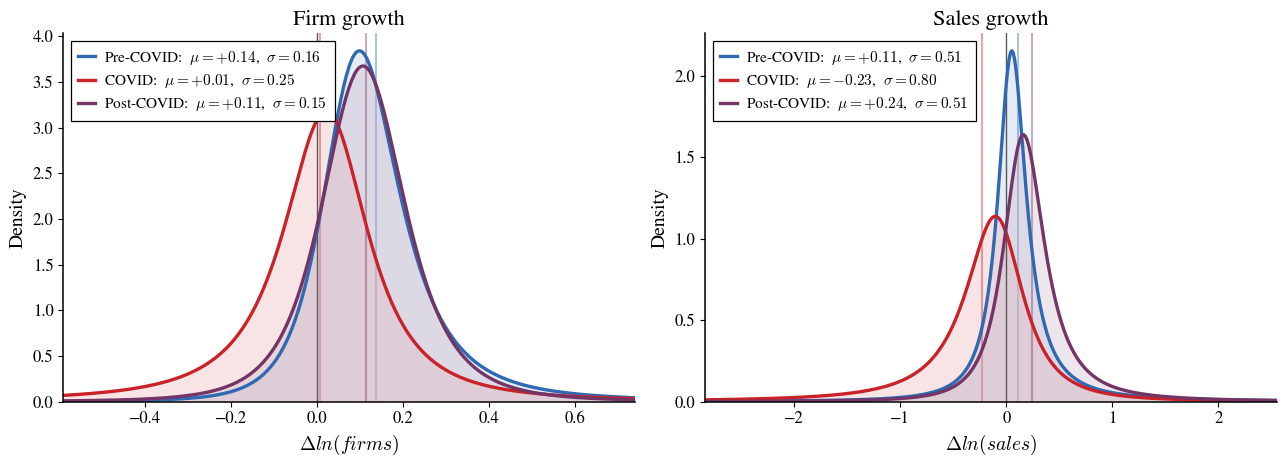

saved -> results/firm_growth_distributions/dist_overlay_eras_nometro.png


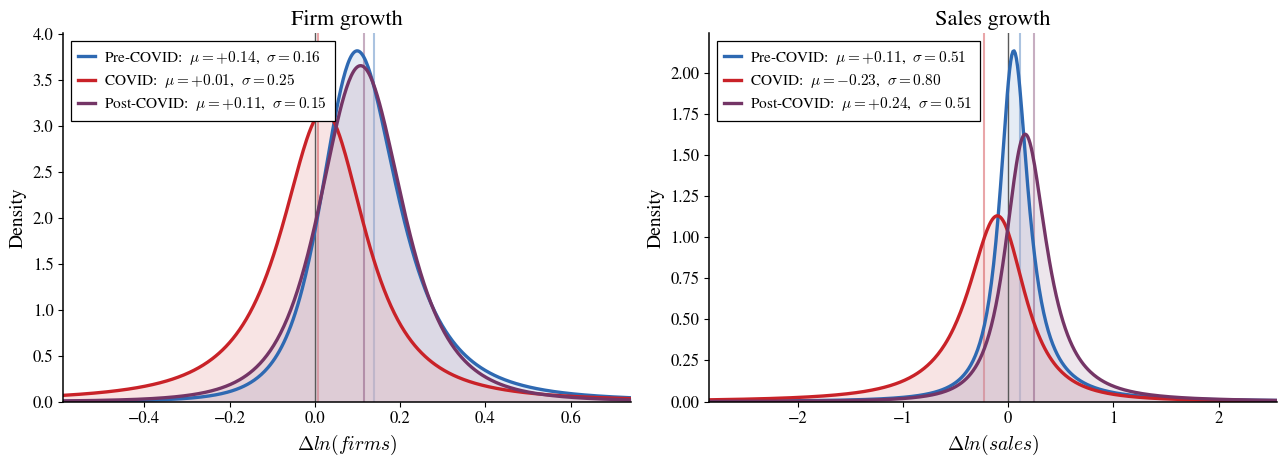

In [9]:
# ==============================================================================
# STEP E (cont.) -- THREE-ERA overlay: pre-COVID / COVID / post-COVID
# ------------------------------------------------------------------------------
# Restyled to match the "Empirical Income Growth Rate" reference figure:
#   * Computer-Modern / LaTeX serif look (STIXGeneral text + cm mathtext)
#   * full box spines, larger tick and label fonts
#   * a framed (boxed) legend in the upper-left with the era moments
#   * era MEANS marked with a CONTINUOUS, faded vertical line (no dashes)
#   * light colour fill under each fitted curve, in the era tint
#   * saved as PNG + PDF + SVG (SVG is vector -> crisp at any zoom, editable)
#   * MINIMAL text: short panel titles, math-only x-labels, no suptitle
#     (the all-parishes / no-metro distinction lives in the FILENAME and in
#     the paper's figure caption, where that detail belongs)
# Same machinery as before: three pooled windows, one fitted skew-t per era,
# drawn twice (all parishes / without metros).
# ==============================================================================

# ---- reference-style rcParams (set once, before plotting) --------------------
plt.rcParams.update({
    "font.family":      "STIXGeneral",   # serif that matches CM math glyphs
    "mathtext.fontset": "cm",            # Computer Modern for $...$
    "axes.titlesize":   16,
    "axes.labelsize":   14,
    "xtick.labelsize":  12,
    "ytick.labelsize":  12,
    "axes.linewidth":   1.1,
    "axes.edgecolor":   "black",
})
# If you compile with a full LaTeX install available, you can instead use
# plt.rcParams["text.usetex"] = True for an exact match.

# ---- palette -----------------------------------------------------------------
ERA_PRE,   PRE_DOT   = ERA_COLORS["Pre-COVID"],  tint(ERA_COLORS["Pre-COVID"])
ERA_COVID, COVID_DOT = ERA_COLORS["COVID"],      tint(ERA_COLORS["COVID"])
ERA_POST,  POST_DOT  = ERA_COLORS["Post-COVID"], tint(ERA_COLORS["Post-COVID"])

#        name          y0     y1    line colour     fill colour
ERAS = [("Pre-COVID",  2017, 2019, ERA_PRE,   PRE_DOT),
        ("COVID",      2019, 2020, ERA_COVID, COVID_DOT),
        ("Post-COVID", 2020, 2022, ERA_POST,  POST_DOT)]

METROS = ("170150", "090150", "010150")                    # Quito, Guayaquil

VARIANTS = [("all parishes",                               (),
             "dist_overlay_eras"),
            ("without the metros (Quito & Guayaquil)",     METROS,
             "dist_overlay_eras_nometro")]

# minimal panel titles + math-only x-labels, overriding the verbose ones
# in series_defs (order must match series_defs)
MINIMAL_LABELS = [("Firm growth",  r"$\Delta ln(firms)$"),
                  ("Sales growth", r"$\Delta ln(sales)$")]

for subtitle, exclude, stem in VARIANTS:
    fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
    for ax, (title, xlab), (_, _, idx) in zip(axes, MINIMAL_LABELS, series_defs):
        data = {era: window_series(y0, y1, exclude)[idx]
                for era, y0, y1, *_ in ERAS}
        pooled = np.concatenate(list(data.values()))
        lo, hi = np.percentile(pooled, [0.5, 99.5])
        xg = np.linspace(lo, hi, 500)

        for era, y0, y1, line_c, fill_c in ERAS:
            x  = data[era]
            f  = fit_both(x)
            mu = float(np.mean(x))
            # compact, reference-style legend entry (add
            # f",  $\\alpha={f['skew']:+.2f}$" back in if you want skewness too)
            lab = f"{era}:  $\\mu={mu:+.2f}$,  $\\sigma={np.std(x):.2f}$"
            pdf = f["st"].pdf(xg)
            ax.plot(xg, pdf, color=line_c, lw=2.4, label=lab)
            ax.fill_between(xg, pdf, color=fill_c, alpha=0.35, lw=0)
            # era mean -> continuous but faded line in the era colour
            ax.axvline(mu, color=line_c, lw=1.5, ls="-", alpha=0.40, zorder=1)

        ax.axvline(0, color="0.35", lw=1.0, zorder=1)       # zero reference
        ax.set_xlim(lo, hi); ax.set_ylim(bottom=0)
        ax.set_title(title)
        ax.set_xlabel(xlab); ax.set_ylabel("Density")

        # boxed legend, like the stats box in the reference figure
        leg = ax.legend(loc="upper left", fontsize=11, frameon=True,
                        fancybox=False, edgecolor="black", framealpha=1.0,
                        handlelength=1.1, handletextpad=0.6,
                        borderpad=0.5, labelspacing=0.35)
        leg.get_frame().set_linewidth(0.9)

    fig.tight_layout()
    fig.savefig(GROWTH_DIR / f"{stem}.png", dpi=200, bbox_inches="tight")
    fig.savefig(GROWTH_DIR / f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(GROWTH_DIR / f"{stem}.svg", bbox_inches="tight")
    print("saved ->", GROWTH_DIR / f"{stem}.png")
    plt.show()

saved -> results/firm_growth_distributions/dist_window_2017_2019.png


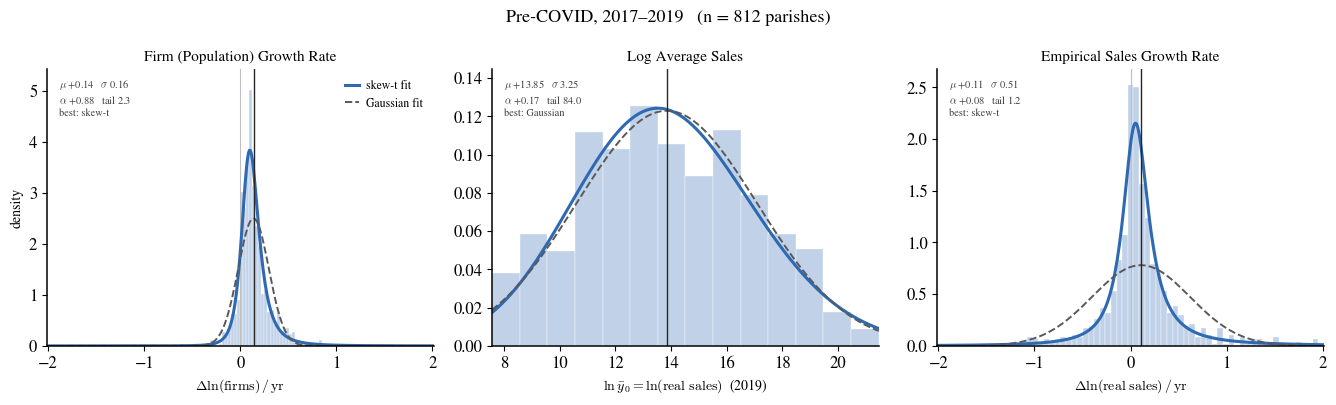

saved -> results/firm_growth_distributions/dist_window_2019_2020.png


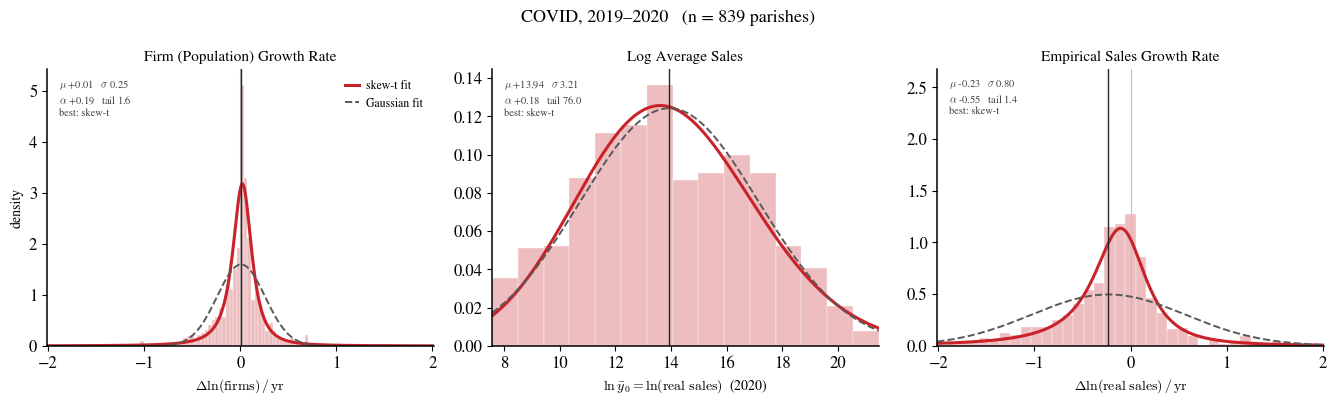

saved -> results/firm_growth_distributions/dist_window_2020_2023.png


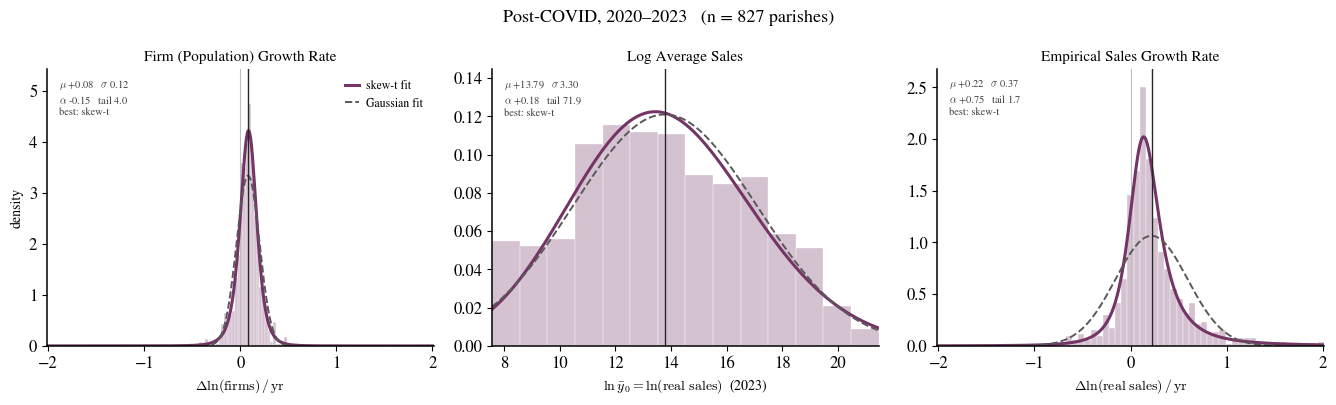

In [10]:
# ==============================================================================
# FIGURE 6 -- one reference-style row PER time window (3 distributions each)
# ------------------------------------------------------------------------------
# Windows: full span 2017-2023, pre-COVID, COVID, post-COVID. Growth panels are
# annualised (per year); the middle panel is the BASELINE log-sales level at the
# window's start year. Each panel: density histogram (BIN_RULE bins) in the
# window's light tint, skew-t fit in the window colour, Gaussian fit dashed,
# a mean line, and mu / sigma / alpha (= sample skewness, as in fit_both) plus
# the tail index and AIC verdict in the corner. One file per window.
# COMPARABLE AXES: the two GROWTH panels share ONE x-range symmetric about 0
# (pooled over all windows and both series, light zero line) and the LEVEL
# panel shares its own pooled x-range. Each COLUMN (firm growth / level /
# sales growth) also shares one y-limit across the three windows, so panel
# heights are comparable row to row as well.
# Needs STEP D + window_series(y0, y1) -> (gp, z0, gy) from the overlay cell.
# ==============================================================================

# ---- palette (same as the era overlay; re-declared so this cell stands alone)
ERA_PRE,   PRE_DOT   = ERA_COLORS["Pre-COVID"],  tint(ERA_COLORS["Pre-COVID"])
ERA_COVID, COVID_DOT = ERA_COLORS["COVID"],      tint(ERA_COLORS["COVID"])
ERA_POST,  POST_DOT  = ERA_COLORS["Post-COVID"], tint(ERA_COLORS["Post-COVID"])
CUSTOM_GRAY, GRAY_DOT = ERA_COLORS["Full span"], tint(ERA_COLORS["Full span"])

#            name          y0     y1    line colour     bar colour
WINDOWS  = [("Pre-COVID",  2017, 2019, ERA_PRE,   PRE_DOT),
            ("COVID",      2019, 2020, ERA_COVID, COVID_DOT),
            ("Post-COVID", 2020, 2023, ERA_POST,  POST_DOT)]

def window_panel(ax, x, title, xlabel, line_c, fill_c, bins=BIN_RULE,
              xlim=None, ylim=None):
    """One reference-style panel: density histogram in the light tint, skew-t
    fit in the window colour, Gaussian fit dashed grey, mean line, and the
    panel stats in the corner (alpha = sample skewness, per fit_both).
    xlim / ylim: shared axis ranges; if None, this panel fits its own."""
    f = fit_both(x)
    lo, hi = xlim if xlim is not None else np.percentile(x, [1, 99])
    xg = np.linspace(lo, hi, 400)
    # tints are pale already, so a heavier alpha than the old 0.40 keeps the
    # bars soft but visible
    counts, _, _ = ax.hist(x, bins=bins, range=(lo, hi), density=True,
                           color=fill_c, alpha=0.85, edgecolor="white", lw=0.3)
    p1, p2 = f["st"].pdf(xg), f["gs"].pdf(xg)
    ax.plot(xg, p1, color=line_c, lw=2.2, label="skew-t fit")
    ax.plot(xg, p2, color="0.35", lw=1.4, ls="--", label="Gaussian fit")
    if lo < 0 < hi:
        ax.axvline(0, color="0.75", lw=0.8, zorder=1)                # centre
    ax.axvline(float(np.mean(x)), color="0.15", lw=1.0)              # mean only
    ax.set_xlim(lo, hi)
    top = ylim if ylim is not None else \
        max(counts.max(), float(p1.max()), float(p2.max())) * 1.06
    ax.set_ylim(0, top)
    ax.margins(x=0)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.text(0.03, 0.97,
            (f"$\\mu$ {np.mean(x):+.2f}   $\\sigma$ {np.std(x):.2f}\n"
             f"$\\alpha$ {f['skew']:+.2f}   tail {f['tail']:.1f}\n"
             f"best: {f['better']}"),
            transform=ax.transAxes, va="top", fontsize=7.5, color="0.25")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def panel_top(x, xlim, bins=BIN_RULE):
    """Tallest thing window_panel will draw for x: histogram bar or either pdf."""
    f = fit_both(x)
    counts, _ = np.histogram(x, bins=bins, range=xlim, density=True)
    xg = np.linspace(xlim[0], xlim[1], 400)
    return max(counts.max(), float(f["st"].pdf(xg).max()),
               float(f["gs"].pdf(xg).max()))


# ---- shared x-ranges: growth panels symmetric about 0, level panel pooled ----
ALL = {name: window_series(y0, y1) for name, y0, y1, *_ in WINDOWS}
g_pool  = np.concatenate([np.r_[gp, gy] for gp, _, gy in ALL.values()])
g_max   = float(np.percentile(np.abs(g_pool), 99))
XLIM_G  = (-g_max, g_max)                              # centred at 0
z_pool  = np.concatenate([z0 for _, z0, _ in ALL.values()])
XLIM_Z  = tuple(np.percentile(z_pool, [1, 99]))

# ---- shared y-limits: one top PER COLUMN across the three windows ------------
YLIM_FIRM  = 1.06 * max(panel_top(gp, XLIM_G) for gp, _, _  in ALL.values())
YLIM_LEVEL = 1.06 * max(panel_top(z0, XLIM_Z) for _, z0, _  in ALL.values())
YLIM_SALES = 1.06 * max(panel_top(gy, XLIM_G) for _, _, gy  in ALL.values())

for name, y0, y1, line_c, fill_c in WINDOWS:
    gp, z0, gy = ALL[name]
    x_level = rf"$\ln \bar y_0=\ln(\mathrm{{real\ sales}})$  ({y1})"

    fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.1))
    window_panel(axs[0], gp, "Firm (Population) Growth Rate", X_FIRM,  line_c, fill_c,
              xlim=XLIM_G, ylim=YLIM_FIRM)
    window_panel(axs[1], z0, "Log Average Sales",             x_level, line_c, fill_c,
              xlim=XLIM_Z, ylim=YLIM_LEVEL)
    window_panel(axs[2], gy, "Empirical Sales Growth Rate",   X_SALES, line_c, fill_c,
              xlim=XLIM_G, ylim=YLIM_SALES)

    axs[0].set_ylabel("density", fontsize=10)
    axs[0].legend(frameon=False, fontsize=8.5, loc="upper right",
                  handlelength=1.2, handletextpad=0.6)

    fig.suptitle(f"{name}, {y0}–{y1}   (n = {gp.size} parishes)", fontsize=13)
    fig.tight_layout()
    out = GROWTH_DIR / f"dist_window_{y0}_{y1}.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    fig.savefig(GROWTH_DIR / f"dist_window_{y0}_{y1}.pdf", bbox_inches="tight")
    print(f"saved -> {out}")
    plt.show()

   pair            series   mean    sd  alpha  tail
2017→18 firm-count growth  0.140 0.233  0.408 1.560
2017→18 real-sales growth  0.214 0.792  1.105 1.044
2018→19 firm-count growth  0.137 0.238  0.562 1.723
2018→19 real-sales growth  0.016 0.800  0.092 1.133
2019→20 firm-count growth  0.008 0.250  0.192 1.600
2019→20 real-sales growth -0.230 0.803 -0.548 1.394
2020→21 firm-count growth  0.125 0.220  0.257 2.025
2020→21 real-sales growth  0.236 0.752  1.031 1.736
2021→22 firm-count growth  0.111 0.240  0.295 2.386
2021→22 real-sales growth  0.243 0.830  0.847 1.078
2022→23 firm-count growth  0.016 0.266 -0.470 1.893
2022→23 real-sales growth  0.165 0.743  0.281 1.278
saved -> results/firm_growth_distributions/dist_moments_by_year.png


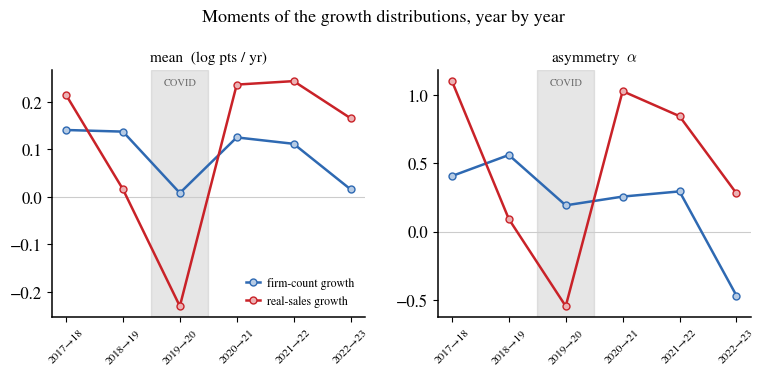

In [11]:
# ==============================================================================
# STEP E (cont.) -- moments of the growth distributions year by year
# ------------------------------------------------------------------------------
# The overlays show shapes; this reduces each year's distribution to the TWO
# numbers that carry the COVID story: MEAN (the location shift -- where the
# typical parish sits) and alpha = sample skewness (which tail dominates --
# the flip). The sd and the fitted tail index are kept in the printed table
# but dropped from the figure: the spread barely moves and the tail index is
# too fit-sensitive to add much, so they earn a sentence, not a panel. The
# COVID step is shaded in red. Needs STEP D + window_series.
# ==============================================================================

# ---- palette (as before; re-declared so this cell stands alone) --------------
FIRM_C,  FIRM_DOT  = C_FIRMS, tint(C_FIRMS)       # firm-count growth
SALES_C, SALES_DOT = C_SALES, tint(C_SALES)       # real-sales growth
# the COVID band is grey in these two panels: red already names a series here
COVID_C, COVID_DOT = GREY, tint(GREY, 0.55)

COVID_PAIR = (2019, 2020)
SERIES = [("firm-count growth", FIRM_C, FIRM_DOT),
          ("real-sales growth", SALES_C, SALES_DOT)]

rows = []
for p in pairs:
    gp, _, gy = window_series(*p)
    for name, x in [("firm-count growth", gp), ("real-sales growth", gy)]:
        f = fit_both(x)
        rows.append(dict(pair=f"{p[0]}→{p[1] % 100:02d}", series=name,
                         mean=np.mean(x), sd=np.std(x),
                         alpha=f["skew"], tail=f["tail"]))
mom = pd.DataFrame(rows)
print(mom.round(3).to_string(index=False))

#          metric   panel title                       zero line?
PANELS = [("mean",  "mean  (log pts / yr)",           True),
          ("alpha", "asymmetry  $\\alpha$",           True)]
# dropped panels, re-add to bring back: ("sd", "sd across parishes", False),
# ("tail", "tail index  (lower = fatter)", False)  [+ log y-scale for "tail"]

covid_i = pairs.index(COVID_PAIR)
xticks  = range(len(pairs))
xlabels = [f"{p[0]}→{p[1] % 100:02d}" for p in pairs]

fig, axes = plt.subplots(1, len(PANELS), figsize=(3.9 * len(PANELS), 3.8),
                         sharex=True)
for ax, (metric, ptitle, zero) in zip(axes, PANELS):
    ax.axvspan(covid_i - 0.5, covid_i + 0.5, color=COVID_DOT, alpha=0.30, zorder=0)
    if zero:
        ax.axhline(0, color="0.8", lw=0.8, zorder=1)
    for name, line_c, dot_c in SERIES:
        v = mom[mom.series == name][metric].values
        ax.plot(xticks, v, lw=1.8, color=line_c, marker="o", ms=5,
                mfc=dot_c, mec=line_c, mew=1.0, label=name)
    ax.annotate("COVID", xy=(covid_i, 0.97), xycoords=("data", "axes fraction"),
                ha="center", va="top", fontsize=7.5, color=COVID_C)
    ax.set_xticks(list(xticks))
    ax.set_xticklabels(xlabels, rotation=45, fontsize=8)
    ax.set_title(ptitle, fontsize=11)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

axes[0].legend(frameon=False, fontsize=8.5, loc="best",
               handlelength=1.2, handletextpad=0.6)
fig.suptitle("Moments of the growth distributions, year by year", fontsize=13)
fig.tight_layout()
fig.savefig(GROWTH_DIR / "dist_moments_by_year.png", dpi=200, bbox_inches="tight")
fig.savefig(GROWTH_DIR / "dist_moments_by_year.pdf", bbox_inches="tight")
print("saved ->", GROWTH_DIR / "dist_moments_by_year.png")
plt.show()

### What the moments panel plots

Each point is one annual step (e.g. 2019→20); purple is firm-count growth $g=\Delta\ln(\text{firms})$, orange is real-sales growth $g=\Delta\ln(\text{real sales})$, both per parish and annualised (log points per year, so 0.10 ≈ +10 %/yr). Each panel reduces that year's whole cross-parish distribution to one number:

- **mean** — the plain cross-parish average $\bar g=\frac{1}{n}\sum_i g_i$. This is the *location* of the distribution: where the typical parish sits. A drop in the mean says (almost) everyone shifted down, independent of any change in shape. Units: log points / yr.
- **asymmetry $\alpha$** — the *sample skewness* $\frac{1}{n}\sum_i\big((g_i-\bar g)/\sigma\big)^3$, the same $\alpha$ printed in the histogram corners (not the skew-t shape parameter). Its sign says which tail dominates: $\alpha<0$ = long **left** tail (a minority of parishes doing far worse than the bulk), $\alpha>0$ = long **right** tail (a minority doing far better); $\alpha=0$ for any symmetric distribution.

The standard deviation and the fitted tail index ($2\min(a,b)$ from `fit_both`, the Student-t-equivalent dof of the heavier tail) are kept in the printed table but not plotted: the cross-parish spread barely moves across years, and the tail index is too fit-sensitive to read cleanly, so the COVID story is carried by *location* (mean) and *which tail* ($\alpha$). The red band marks the 2019→20 step.

### Quick read — the two updates and what they say

**What changed.** (1) The three-era overlay now draws a dashed vertical line at each era's **mean**, in the era's colour, and the whole figure is drawn a second time **without the two metro parishes** (Quito 170150, Guayaquil 090150), saved as `dist_overlay_eras_nometro`. (2) The moments figure keeps only the **mean** and **asymmetry $\alpha$** panels; the sd and the fitted tail index stay in the printed table but lost their panels (the spread barely moves and the tail index is too fit-sensitive to read cleanly year to year).

**What the mean lines show.** The dashed lines make the era story literal. Sales-growth means run **+0.11 → −0.23 → +0.22** log pts/yr (pre → COVID → post): COVID slid the whole distribution left of zero, and the post-COVID mean lands slightly *right* of the pre-COVID one — a rebound that overshot, not just recovered. Firm-count growth runs **+0.14 → +0.01 → +0.08**: formation stalled to zero in the COVID year and resumed at roughly half its pre-COVID pace, which is the annual-grain echo of the 2022→23 drift in the moments panel.

**What the no-metro test shows: nothing moves — and that is the result.** Every era mean is unchanged to three decimals (sales: +0.109 / −0.230 / +0.219 with or without the metros; firm growth likewise) and the fitted curves overlap. These are *unweighted per-parish* distributions, so Quito and Guayaquil are just 2 of ~810–840 points — the era shapes, the COVID left-shift and the skew flip are carried by the hundreds of ordinary parishes. That is the mirror image of the *weighted* decomposition terms (STEP H), where the metros dominate: the metros decide the aggregate, but they do not shape the cross-parish distribution.

**Reading the slimmed moments panel.** Two panels now carry the year-by-year story cleanly: the mean dips (sales to −0.23, firms to ≈0) exactly in the red 2019→20 band while $\alpha$ flips from its usual positive (right tail of booming parishes) to −0.55 (left tail of collapsing ones), and both recover the following step. The one thing to keep watching is 2022→23: the firm-growth mean falls back near zero and its $\alpha$ turns negative — a drift that has nothing to do with COVID and shows up only at the annual grain.


saved -> results/firm_growth_distributions/dist_quantile_fan.png


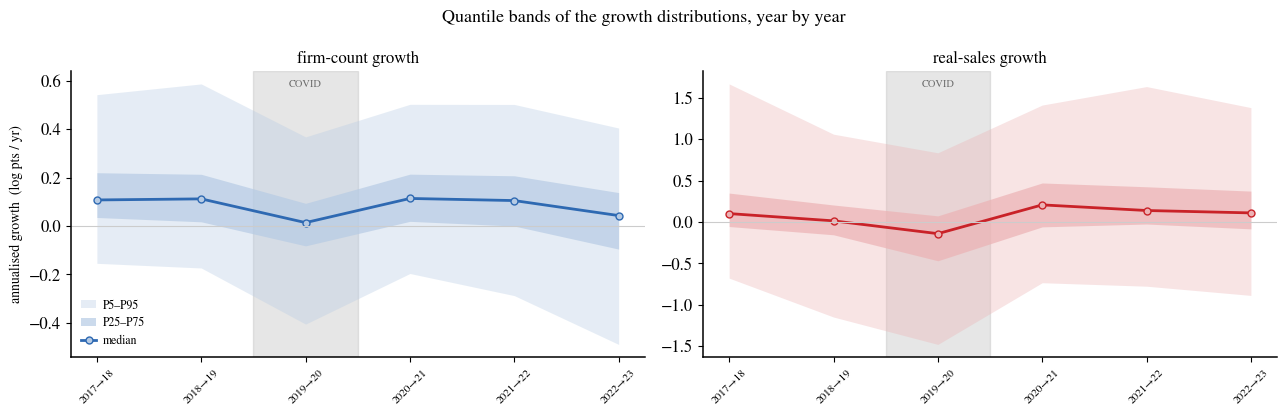

In [12]:
# ==============================================================================
# STEP E (cont.) -- quantile fan of the growth distributions, year by year
# ------------------------------------------------------------------------------
# Complement to the moments panel: instead of summary numbers, track the whole
# distribution. Median line, interquartile band (P25-P75, darker) and P5-P95
# band (lighter) per annual step. COVID shows up as the whole fan dropping
# (location), stretching (spread) and turning lopsided (asymmetry) in one
# glance. Needs STEP D + window_series.
# ==============================================================================

# ---- palette ------------------------------------------------------------------
FIRM_C,  FIRM_DOT  = C_FIRMS, tint(C_FIRMS)       # firm-count growth
SALES_C, SALES_DOT = C_SALES, tint(C_SALES)       # real-sales growth
# the COVID band is grey in these two panels: red already names a series here
COVID_C, COVID_DOT = GREY, tint(GREY, 0.55)

COVID_PAIR = (2019, 2020)
QS = [5, 25, 50, 75, 95]

Q = {"firm-count growth": [], "real-sales growth": []}
for p in pairs:
    gp, _, gy = window_series(*p)
    Q["firm-count growth"].append(np.percentile(gp, QS))
    Q["real-sales growth"].append(np.percentile(gy, QS))
Q = {k: np.array(v) for k, v in Q.items()}              # (n_pairs, 5) each

covid_i = pairs.index(COVID_PAIR)
x       = np.arange(len(pairs))
xlabels = [f"{p[0]}\u2192{p[1] % 100:02d}" for p in pairs]

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.2), sharex=True)
for ax, (name, line_c, fill_c) in zip(axes,
        [("firm-count growth", FIRM_C, FIRM_DOT),
         ("real-sales growth", SALES_C, SALES_DOT)]):
    q = Q[name]
    ax.axvspan(covid_i - 0.5, covid_i + 0.5, color=COVID_DOT, alpha=0.30, zorder=0)
    ax.fill_between(x, q[:, 0], q[:, 4], color=fill_c, alpha=0.35, lw=0,
                    label="P5\u2013P95")
    ax.fill_between(x, q[:, 1], q[:, 3], color=fill_c, alpha=0.70, lw=0,
                    label="P25\u2013P75")
    ax.plot(x, q[:, 2], color=line_c, lw=2.0, marker="o", ms=5,
            mfc=fill_c, mec=line_c, mew=1.0, label="median")
    ax.axhline(0, color="0.8", lw=0.8)
    ax.annotate("COVID", xy=(covid_i, 0.97), xycoords=("data", "axes fraction"),
                ha="center", va="top", fontsize=7.5, color=COVID_C)
    ax.set_xticks(list(x))
    ax.set_xticklabels(xlabels, rotation=45, fontsize=8)
    ax.set_title(name, fontsize=12)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

axes[0].set_ylabel("annualised growth  (log pts / yr)", fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, loc="best",
               handlelength=1.2, handletextpad=0.6)
fig.suptitle("Quantile bands of the growth distributions, year by year", fontsize=13)
fig.tight_layout()
fig.savefig(GROWTH_DIR / "dist_quantile_fan.png", dpi=200, bbox_inches="tight")
fig.savefig(GROWTH_DIR / "dist_quantile_fan.pdf", bbox_inches="tight")
print("saved ->", GROWTH_DIR / "dist_quantile_fan.png")
plt.show()

### What the quantile fan plots

Same yearly cross-parish growth distributions as the moments panel, but with no summary statistics and no fitted model: each annual step is sliced into five percentiles, stacked vertically —

- **median line (P50)** — half the parishes grew faster, half slower. A robust location measure: unlike the mean, it cannot be dragged by a handful of extreme parishes.
- **dark band (P25–P75)** — the interquartile range: the middle half of all parishes lives inside it. Its height is a robust measure of spread.
- **light band (P5–P95)** — 90 % of parishes. The gap between the light and dark bands is the tail region; when it stretches on one side only, that one-sided stretch is exactly the asymmetry the $\alpha$ panel summarises.

Reading an event like COVID: the whole fan dropping = a location shock hitting essentially all parishes; the bands widening = rising dispersion; the median sitting nearer the top of its bands than the bottom = a long left tail (mean < median). Because percentiles are outlier-robust, agreement between this figure and the moments panel is evidence that the story is carried by the bulk of parishes, not by a few extreme observations.

## Entering firms without firm IDs — what differencing two years can and cannot claim

**The question.** What does the cohort of *newly entering* formal firms look like — and in the year Ecuador formalized fastest, did the new firms replicate the map of the existing formal economy or enter somewhere else?

**What differencing identifies.** This data has no firm identifiers, only anonymous counts per (parish, sector, month) cell. Differencing two years therefore identifies **net** entry only:

$$\Delta N_p \;=\; N_p(y_1) - N_p(y_0) \;=\; \underbrace{\text{entries}}_{\text{want}} \;-\; \underbrace{\text{exits}}_{\text{leak 1}} \;\pm\; \underbrace{\text{reclassifications}}_{\text{leak 2: address/activity moves, reactivations}}$$

Gross entry is unrecoverable — no method fixes that without micro data. But the *distance* between net and gross is measurable from the data itself, and the cell below prints it before drawing anything:

- **The negative mass.** Firms lost in shrinking parishes as a share of firms gained in growing ones. In 2021→22 it is **1.3%** — the netting that differencing hides inside growing parishes can be larger than what shows up in shrinking ones, but a tiny negative mass is exactly what a "entry ≫ exit" year looks like.
- **The monthly bound.** Summing only the *positive* month-to-month increments of the national stock gives a lower bound on gross entry that annual netting cannot hide: **≥ 31,112** for 2022, against a Dec→Dec net of **+28,838**. Net captures ≥ 93% of (this bound on) gross at the aggregate.
- **A constant-hazard robustness overlay.** If a uniform share $\delta$ of incumbents had exited everywhere, true gross entry would be $E_p = \Delta N_p + \delta N_p(y_0)$. The figure overlays $\delta = 5\%,10\%$ as dashed curves — if they sit on top of the orange curve, every *distributional* claim is robust to exit; only the *level* of entry stays a lower bound.

**What differencing does *not* license.** Subtracting the **sales** (or growth) *densities* of two years does **not** give the sales of entrants: incumbents move within those distributions between years, so a density difference mixes incumbent dynamics with entry inseparably. Only **counts within fixed cells** difference cleanly — everything below is counts.

**Design choices.** (i) **December-to-December** stocks, not the annual-mean stocks the decomposition uses: a Dec→Dec change is "firms added during calendar year $y_1$", while the annual-mean difference is the same flow smoothed (both are printed; they agree on the year). (ii) The cohort year is chosen *by the data*: the largest national net entry ≤ 2023 is **2021→22** (+28,838) under both definitions — with the aside that 2022→23 collapses to **+4,391**, the same post-COVID stall the moments panel flagged. (iii) A parish absent from one December counts as zero stock, so brand-new parishes enter the cohort at full weight.

### What the entrant cohort shows

- **The cohort is a left-shifted, slightly narrower copy of the stock.** Across parishes the net-entry counts are ≈ lognormal with $\mu = 0.83$, $\sigma = 0.66$ in $\log_{10}$, against $\mu = 1.21$, $\sigma = 0.75$ for the incumbent stock — the typical parish gained ~7 net firms on a stock of ~16. The two dashed gross-entry proxies ($\delta = 5\%, 10\%$) sit almost on top of the orange curve, so this shape survives any plausible uniform exit rate; only the *level* of gross entry is a lower bound.
- **Entry tracks the existing map, but less concentrated than it.** The share-share slope is **0.70** ($r = 0.81$): entrant shares rise with stock shares, but sub-proportionally. The metros are the clearest case and need no regression: **Quito took 19.0% of net entry against 25.8% of the stock, Guayaquil 18.4% against 28.0%** — both visibly below the 45° line — while Cuenca over-entered (4.5% vs 3.6%). In the fastest formalization year on record, formalization *diffused* the map of the formal economy rather than intensifying its concentration — consistent with the marginal formalizing firm being small, peripheral activity rather than metro business creation.
- **One honesty caveat on the slope.** The log–log fit conditions on $\Delta N_p > 0$, so the 307 flat-or-shrinking parishes (mostly tiny) are excluded — "small parishes over-enter" holds *conditional on entering at all*. The metro under-entry needs no such conditioning and is the robust half of the statement.

### The revenue side — differencing the sales-per-firm distributions

The natural next question: can differencing the **average real sales per firm** between the two years say what the entrants' revenue looks like — many-but-small? Attribution of revenue *levels* to entrants stays impossible without firm IDs (per cell, ΔSales mixes incumbent growth with entrant sales inseparably), but the *relative size* of the marginal entrant **is** recoverable, provided the differencing is done in the right direction. Two facts, both printed by the cell below, decide that direction:

1. **The aggregate mean difference alone pins down nothing.** Entrants are ~11% of firms, so the entrant term in $\bar z = S/N$ is small against incumbent swings: solving $x_e = [S_1 - S_0(1+g)]/E$ for the entrant mean revenue, an assumed incumbent growth $g$ anywhere in $[-5\%, +8\%]$ moves the answer from **138%** of the average firm down to **25%**. Any claim built on the national mean shift is really a claim about the assumed $g$.
2. **The raw cross-parish distribution moves the *wrong way*.** Between 2021 and 2022 the parish distribution of $\ln(S_p/N_p)$ shifts **right** (+0.13) — the rebound lifting incumbents — even though thousands of small entrants are diluting it underneath. Read naively, the raw difference would *reject* the many-but-small hypothesis that is in fact true.

**The fix is to difference across parishes within the year pair, not across years in the aggregate.** Regressing the change in log sales-per-firm on the entry rate,

$$\Delta\ln(S_p/N_p) \;=\; a \;+\; b\,\Delta\ln N_p,$$

the **intercept** absorbs the common incumbent drift (whatever the macro year did) and the **slope** is the composition effect: high-entry parishes' averages fall relative to low-entry ones only if the entering firms are smaller than the incumbent average. The marginal net entrant then carries $\approx (1+b)$ of the parish's average-firm revenue. Identification requires parishes' *idiosyncratic* incumbent growth to be uncorrelated with their entry rate; demand-driven entry (local booms lift incumbents *and* attract entrants) biases $b$ upward, so $(1+b)$ is an **upper bound** on entrant size — the safe direction for concluding "small". A long-window accounting check backs the cross-section: over 2017→23 firms grew **+74%** while real sales grew **+30%** (sales per firm **−25%**), a six-year one-directional dilution that incumbent decline alone would struggle to sustain.

### What the dilution split shows

- **Many but small — confirmed, as an upper bound.** The dilution slope is $b = -0.70$: each 1% of extra firms costs a parish 0.70% of average sales per firm, so the marginal net entrant of 2021→22 carries **at most ~0.30 of an average firm's revenue** (and less if entry chases demand). This is the same number as the sales-growth elasticity $\theta \approx 0.28$ from the identity $\Delta\ln S = \Delta\ln N + \Delta\ln(S/N)$ — two views of one regression.
- **The intercept tells the incumbent story separately:** +0.21 is the rebound drift shared by everyone — exactly the force that pushed the raw distribution right and would have fooled the naive year-on-year difference.
- **The long window makes it structural.** Sales per firm falls every single year except the 2021 rebound (−4.3, −8.3, −18.1, +10.3, −0.5, −5.0%); even crediting incumbents with zero real growth over 2017→23, the net-added cohort averages **41%** of a 2017 firm. Ecuador's formalization decade added firms about three times faster than it added revenue.
- **Two limits to keep in the caption.** (i) The scatter's $r$ is small — entry explains little of *where revenue moved*; revenue dynamics remain an incumbent/intensive-margin story, consistent with transmission dominating selection in the decomposition. (ii) Even a perfectly measured entrant revenue would mix newly *created* activity with previously informal activity becoming newly *visible* to SRI — no firm-level dataset resolves that, so "low-revenue entrants" should be read as "low *formal* revenue at entry".

### From a bound to a distribution — two firm-ID-free windows on entrant revenue

The dilution slope compresses the entrant-size story into one number. To see it as a **distribution**, the obvious construction — impute each parish's entrant revenue as $x_e = [S_1 - S_0(1+g)]/\Delta N$ and histogram it — fails outright: parish-level incumbent noise makes 25–60% of parishes come out *negative* (the share depending on the assumed $g$), and dropping them truncates the distribution so severely that its median flips **above** the incumbent average — a pure selection artifact saying the opposite of the truth. So that histogram is deliberately not drawn.

Dropping to **parish × CIIU-section cells** instead gives two constructions that need no incumbent-growth assumption at all:

1. **Where entrants land.** Every existing cell has an observable incumbent revenue-per-firm $z = S/N$ at $Y_0$. Weighting those $z$ by the net entrants each cell received (vs by the incumbent firms sitting there) shows which part of the revenue spectrum absorbed the cohort. Covers the ~94% of cell-level entry that flowed into existing cells — but says nothing about the entrants' *own* revenue.
2. **What entrants earn — measured, not imputed.** Cells with **zero** firms at $Y_0$ ("greenfield": the first firm(s) of a parish–sector combination) contain *only* entrants, so their $S/N$ at $Y_1$ is a direct observation of entrant revenue — the one place the aggregation is harmless. Sales are annualised by the months the cell actually reports (the median greenfield cell appears ~2 months before year-end). Covers the other ~6% — a *selected frontier slice*, so read it as the marginal entrant, not the cohort average, and expect it to sit below the dilution bound rather than at it.

### What the two windows show

- **Left — entrants land across the whole revenue spectrum, not in its poor end.** The entrant-weighted curve is nearly indistinguishable from the incumbent-weighted one (entrant-weighted median receiving-cell $z$ ≈ \$384k vs \$304k firm-weighted incumbent) — if anything entry tilts toward the *richer* cells, the commerce-hub sectors of the bigger parishes. Combined with STEP N's share-share panel: entry follows the map of existing activity, mildly deconcentrated in space, not segregated by cell revenue.
- **Right — but what they earn is almost nothing.** The greenfield slice, the only place entrant revenue is directly measurable, is a **spike at zero plus a thin tail**: median ≈ \$100/yr annualised, half the firms in cells earning under \$100 per firm-year, yet a 99th percentile above \$2M — a mass of registered-but-barely-selling micro-entrants sprinkled with a few real businesses. This sits far *below* the dilution bound (≤ 0.30 × average firm), exactly as it should: the bound covers the whole cohort's average, the greenfield slice is its selected frontier.
- **The reconciled picture of the 2022 formalization wave:** many firms (+11.5% net), placed roughly proportionally to the existing economy (slope 0.70, same revenue spectrum of cells), carrying on average at most ~0.30 of an average firm's revenue — and at the observable frontier, essentially none. "A lot, but low-revenue" is now a distribution, not an inference.
- **Caveats.** Greenfield is 6% and selected (first firm in a parish–sector); the other 94% remain bounded only through the dilution slope. Annualising ~2 reported months assumes a constant rate and ignores ramp-up, so entrant *steady-state* revenue is understated by both selection and timing — the qualitative gap (\$10² vs \$10⁵·⁵) is far too large for either to overturn. Net cell entry slightly understates gross (cell-level negative mass exists but is small in this year); and, as throughout, "revenue at entry" is *formal* revenue — newly visible, not necessarily newly created.

## Did proximity to the big revenue parishes shield formal firms during COVID — and at what scale?

**The question.** During the COVID year, did parishes *close* to the big revenue centres keep creating formal firms while remote, low-revenue parishes lost them? And is that a **macro**-scale fact (whole remote provinces did worse) or a **fine**-scale one (within a province, the parishes far from a hub did worse)?

**The design**, in four ingredients (each a parameter, so it can be varied):

1. **Hubs** = the smallest set of parishes holding `HUB_SHARE` of national real sales in `HUB_YEAR` (pre-shock, 2019). At 75% that is 7 parishes — Guayaquil, Quito, Durán, Cuenca, Samborondón, Cumbayá, Machala — i.e. the Guayaquil and Quito metros plus Cuenca and Machala.
2. **Distance** = each non-hub parish's straight-line distance (km) from its centroid to the *nearest* hub centroid, from the official DPA shapefile (already in metres, UTM 17S).
3. **Outcomes** = firm-count growth (net formal-firm formation, the decomposition's fitness) and real-sales growth in the COVID step 2019→20; plus each parish's **excess** = COVID growth minus its *own* pre-COVID pace (2017→19, annualised), which nets out permanent parish-level differences.
4. **Scales** = the same regression of growth on ln(distance) run three ways — **overall** (raw, mixes scales), **macro** (on province means: only cross-province variation survives), **fine** (on deviations from province means: only within-province variation survives) — and then the whole thing repeated with **cantons** as the unit. All slopes control for ln(2019 sales), so "far" is not just proxying "small".

**A reading note for the binned figure:** the raw decile curves can look flat even when proximity matters, because they mix the two scales — provinces differ a lot in level, and the gradient (as the forest plot shows) lives *within* provinces. That is exactly why the scale split is the right test.

In [13]:
# ==============================================================================
# STEP F -- revenue hubs + each parish's distance to the nearest hub
# ------------------------------------------------------------------------------
# Parish centroids come from the official DPA shapefile (EPSG:32717 = UTM 17S,
# metres -> /1e3 = km; fine for relative distances). Hubs = top parishes by
# HUB_YEAR real sales until HUB_SHARE of the national total is covered; every
# other parish gets its straight-line distance to the NEAREST hub.
# ==============================================================================
import geopandas as gpd

SHAPE_PARR = paths.SHAPEFILES["parish"]
HUB_YEAR  = 2019     # size is measured PRE-shock
HUB_SHARE = 0.75    # hubs = top parishes holding this share of national real sales

gdf  = gpd.read_file(SHAPE_PARR)[["DPA_PARROQ", "DPA_DESPAR", "DPA_DESCAN", "geometry"]]
cent = gdf.set_index("DPA_PARROQ").geometry.centroid          # UTM 17S, metres

sales19 = SALES[HUB_YEAR].dropna().sort_values(ascending=False)
sales19 = sales19[sales19.index.isin(cent.index)]             # need a location for everyone
cum  = sales19.cumsum() / sales19.sum()
hubs = list(sales19.index[:int((cum <= HUB_SHARE).sum()) + 1])
names = gdf.set_index("DPA_PARROQ")
print(f"{len(hubs)} hub parishes hold {cum.iloc[len(hubs)-1]:.0%} of {HUB_YEAR} real sales:")
for h in hubs:
    print(f"   {h}  {names.loc[h,'DPA_DESPAR']:<28s} ({names.loc[h,'DPA_DESCAN']})"
          f"  ${sales19[h]/1e9:.1f}B")

hub_xy   = np.column_stack([cent.loc[hubs].x, cent.loc[hubs].y])
other    = [p for p in sales19.index if p not in hubs]
other_xy = np.column_stack([cent.loc[other].x, cent.loc[other].y])
dist_km  = pd.Series(
    np.sqrt(((other_xy[:, None, :] - hub_xy[None, :, :]) ** 2).sum(-1)).min(1) / 1e3,
    index=pd.Index(other, name="cod_parr"), name="dist_km")
print(f"\n{len(other)} non-hub parishes; distance to nearest hub: "
      f"median {dist_km.median():.0f} km, max {dist_km.max():.0f} km")

7 hub parishes hold 76% of 2019 real sales:
   090150  GUAYAQUIL                    (GUAYAQUIL)  $45.2B
   170150  QUITO                        (DISTRITO METROPOLITANO DE QUITO)  $45.1B
   090750  ELOY ALFARO (DURAN)          (DURAN)  $5.1B
   010150  CUENCA                       (CUENCA)  $5.0B
   091650  SAMBORONDON                  (SAMBORONDON)  $2.8B
   170157  CUMBAYA                      (DISTRITO METROPOLITANO DE QUITO)  $2.6B
   070150  MACHALA                      (MACHALA)  $2.5B

929 non-hub parishes; distance to nearest hub: median 92 km, max 350 km


### What the proximity analysis shows — honestly

**The first-order fact: proximity did NOT visibly shield anyone.** Look at the binned figure — the COVID line is essentially flat, and the overall parish-level correlation between distance and COVID-year firm growth is zero (slope +0.001, p = 0.91, size-controlled). The shock was near-universal: parishes next to Quito and Guayaquil lost their firm-formation momentum just like remote ones.

**What survives careful testing is only a faint fine-scale tilt.** Within provinces, the slope of *excess* firm growth (COVID minus own pre-COVID pace) on ln(distance) is −0.075 (p ≈ 0.005), and it is statistically sturdy: it holds without the size control (−0.077), after winsorizing the outcome at the 1/99 percentiles (−0.068), in a rank correlation (Spearman ρ = −0.13, p = 0.0002), when dropping any single province (all 23 leave-one-out slopes stay negative), and 14 of 20 provinces individually show a negative slope.

**But its magnitude is small.** Within a province, parishes only span about ×2.4 in distance to a hub (p90 − p10 ≈ 0.87 log-km), so the realistic within-province effect is ≈ **−0.065 log pts/yr (≈ −6%)** — against a cross-parish sd of excess growth of **0.31**. Distance explains ≈ **1% of the variance** (R² ≈ 0.01). A "10× farther" comparison would triple that number, but 10× distance differences only exist *across* provinces — and at that macro scale the slope is zero (slightly positive, insignificant), and canton aggregation erases everything.

**Bottom line.** COVID's hit to formal-firm formation was geographically broad-based; proximity to the revenue hubs bought, at most, a modest *average* tilt detectable only within provinces and only with the full sample's statistical power. Which parishes suffered was overwhelmingly idiosyncratic (the sd across parishes dwarfs the distance gradient), not a simple function of distance to the big centres. The scale finding still stands — whatever geographic structure exists lives *below* the canton grain, not between provinces — but "shielding" is too strong a word for an effect this size.

*(Robustness knobs: `HUB_SHARE` — 0.5 gives just Quito + Guayaquil and the same qualitative picture; `HUB_YEAR`, `PRE`, `SHOCK`, `N_BINS`, and `control_size` in `slope()`.)*

## Why did selection flip sign in 2019→20 — and how to see it

The decomposition's **selection term is nothing more than a covariance you can draw**: for the population path,

$$S=\frac{1}{n}\sum_i p_i\Big(\frac{w_i}{\bar W}-1\Big)(z_i-\bar z)$$

where $p_i$ = parish $i$'s initial share of all firms, $w_i/\bar W - 1$ = its **relative fitness** (firm-count growth relative to the firm-weighted national average), $z_i$ = its **initial trait** $\ln(\text{real sales})$, and $\bar z$ the firm-weighted mean trait. So $S<0$ means *low-revenue parishes are adding firms faster than high-revenue ones* (formal-firm formation dispersing down the size distribution) and $S>0$ means the opposite — firm formation tilting toward the big-revenue parishes.

The three cells below make the 2019→20 flip visible from the micro data, in three ways:

1. **The cloud and its tilt** — one panel per annual step: every parish plotted as (trait, relative fitness), dot area = firm share, with the $p$-weighted regression line. Selection is literally the tilt of that line (times the trait variance). Every normal year tilts *down*; the COVID panel tilts *up*. (The recomputed $S$ is verified against the engine's `selection_transmission_by_year.csv` to machine precision.)
2. **Who flips it** — each parish's contribution $p_i(w_i/\bar W-1)(z_i-\bar z)$ summed by size decile. A contribution is *positive* either because a big parish out-grew the average **or** because a small parish under-grew it — so this panel shows which end of the size distribution drives the sign.
3. **At what scale** — the engine already splits total selection into between-province, canton-within-province, and parish-within-canton components (law of total covariance); stacking them per year shows where the flip lives.

verification vs engine (pop path):
  2017->2018: recomputed -0.045120  engine -0.045120  match=True
  2018->2019: recomputed -0.059700  engine -0.059700  match=True
  2019->2020: recomputed +0.034167  engine +0.034167  match=True
  2020->2021: recomputed -0.034638  engine -0.034638  match=True
  2021->2022: recomputed -0.033817  engine -0.033817  match=True
  2022->2023: recomputed -0.018313  engine -0.018313  match=True


saved -> results/selection_anatomy/selection_flip_scatter.png


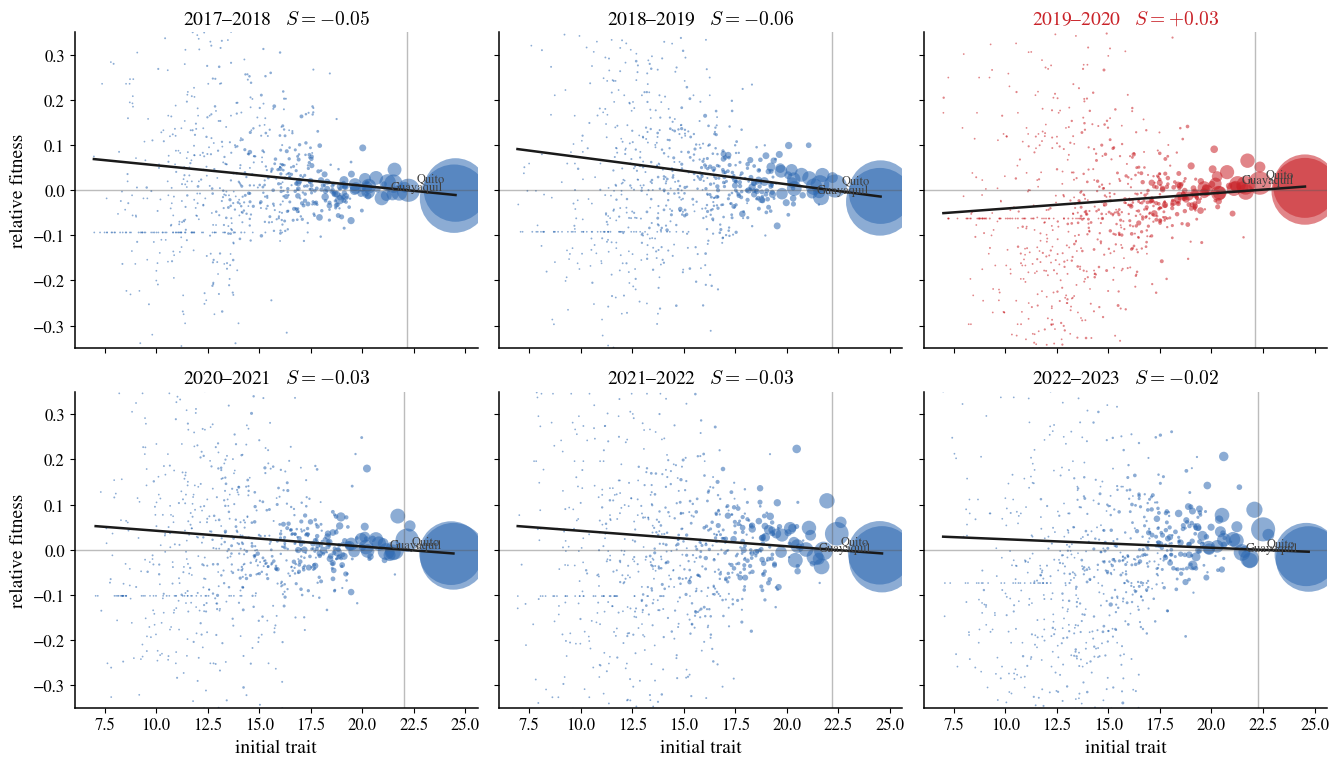

In [14]:
# ==============================================================================
# STEP G -- the selection covariance from micro data: verify, then draw the tilt
# ------------------------------------------------------------------------------
# Restyled to match the era-overlay figure:
#   * Computer-Modern / LaTeX serif look (STIXGeneral text + cm mathtext)
#   * full box spines, larger tick and label fonts
#   * MINIMAL text: panel title = year pair + S only (2 decimals), math-only
#     axis labels, no suptitle (the mechanics go in the paper's caption)
#   * COVID panel flagged by colour alone (era red: dots + title)
#   * reference lines continuous + faded, like the mean lines in the overlay
#   * saved as PNG + PDF + SVG
# ==============================================================================
SEL_DIR = paths.SELECTION_ANATOMY
SEL_DIR.mkdir(parents=True, exist_ok=True)

# ---- reference-style rcParams (same block as the era overlay; harmless if
#      already set earlier in the notebook) ------------------------------------
plt.rcParams.update({
    "font.family":      "STIXGeneral",   # serif that matches CM math glyphs
    "mathtext.fontset": "cm",            # Computer Modern for $...$
    "axes.titlesize":   14,
    "axes.labelsize":   14,
    "xtick.labelsize":  12,
    "ytick.labelsize":  12,
    "axes.linewidth":   1.1,
    "axes.edgecolor":   "black",
})

def selection_table(y0, y1):
    'Per-parish ingredients of the engine pop-path selection term.'
    surv = sorted(VALID[y0] & VALID[y1])
    n0, n1 = FIRMS.loc[surv, y0], FIRMS.loc[surv, y1]
    z = np.log(SALES.loc[surv, y0])
    p = n0 / n0.sum()                       # initial firm share
    w = n1 / n0                             # fitness (firm-count ratio)
    W, Z = (p * w).sum(), (p * z).sum()     # firm-weighted means
    t = pd.DataFrame({"p": p, "relfit": w / W - 1, "z": z, "zdev": z - Z})
    t["contrib"] = t["p"] * t["relfit"] * t["zdev"] / (y1 - y0)
    return t

eng = pd.read_csv(YEARLY_DIR / "selection_by_step.csv")
eng = eng[eng.path == "pop"].set_index("window")
print("verification vs engine (pop path):")
for y0, y1 in pairs:
    mine, theirs = selection_table(y0, y1)["contrib"].sum(), eng.loc[f"{y0}_to_{y1}", "selection_total"]
    print(f"  {y0}->{y1}: recomputed {mine:+.6f}  engine {theirs:+.6f}  match={np.isclose(mine, theirs)}")

# COVID uses the era palette from the overlay figure; other years a neutral blue
COVID_C, BASE_C = style.SHOCK, style.BASELINE

fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.8), sharex=True, sharey=True)
for ax, (y0, y1) in zip(axes.ravel(), pairs):
    t = selection_table(y0, y1)
    covid = (y0, y1) == COVID_PAIR
    S = t["contrib"].sum()
    # weighted fit line: slope = cov_w/var_w, through (Z, 0) since the p-weighted
    # mean of relative fitness is 0 by construction
    b = S * (y1 - y0) / (t["p"] * t["zdev"] ** 2).sum()
    Z = (t["p"] * t["z"]).sum()
    xg = np.linspace(t["z"].min(), t["z"].max(), 2)
    ax.scatter(t["z"], t["relfit"], s=8e3 * t["p"] + 1.5, alpha=0.55,
               color=COVID_C if covid else BASE_C, lw=0)
    ax.plot(xg, b * (xg - Z), color="0.1", lw=1.8)
    # reference lines: continuous but faded, matching the era-mean treatment
    ax.axhline(0, color="0.35", lw=1.0, alpha=0.40, zorder=1)
    ax.axvline(Z, color="0.35", lw=1.0, alpha=0.40, zorder=1)
    for hub in ["170150", "090150"]:                      # Quito, Guayaquil
        if hub in t.index:
            ax.annotate(names.loc[hub, "DPA_DESPAR"].title(),
                        (t.loc[hub, "z"], t.loc[hub, "relfit"]),
                        textcoords="offset points", xytext=(-8, 6),
                        ha="right", fontsize=9, color="0.25")
    # minimal title: year pair + S at 2 decimals; COVID flagged by colour only
    ax.set_title(f"{y0}\u2013{y1}   $S={S:+.2f}$",
                 color=COVID_C if covid else "black")

axes.ravel()[0].set_ylim(-0.35, 0.35)                     # display clip; S uses all points
for ax in axes[:, 0]:
    ax.set_ylabel("relative fitness")
for ax in axes[1, :]:
    ax.set_xlabel("initial trait")

fig.tight_layout()
fig.savefig(SEL_DIR / "selection_flip_scatter.png", dpi=200, bbox_inches="tight")
fig.savefig(SEL_DIR / "selection_flip_scatter.pdf", bbox_inches="tight")
fig.savefig(SEL_DIR / "selection_flip_scatter.svg", bbox_inches="tight")
print("saved ->", SEL_DIR / "selection_flip_scatter.png")
plt.show()

### Why this scatter *is* the selection term — the math, and how to read it

**The math.** For one annual window $t_0\to t_1$, the engine's pop-path selection term is the Price-equation covariance

$$S \;=\; \frac{1}{\Delta t}\sum_i p_i\Big(\frac{w_i}{\bar W}-1\Big)(z_i-\bar z) \;=\; \frac{1}{\Delta t}\,\mathrm{Cov}_p\!\Big(\frac{w}{\bar W},\,z\Big),$$

with, for each parish $i$: $p_i=n_i(t_0)/\sum_j n_j(t_0)$ the initial **firm share** (the weight), $w_i=n_i(t_1)/n_i(t_0)$ the **fitness** (firm-count growth factor), $\bar W=\sum_i p_i w_i$, $z_i=\ln(\text{real sales at }t_0)$ the **trait**, and $\bar z=\sum_i p_i z_i$. `selection_table()` rebuilds exactly these ingredients from the micro data, and the verification loop above confirms the sum of per-parish contributions matches `selection_total` in the engine's CSV to machine precision — so the scatter is not an *illustration* of the selection term; it is the selection term, drawn point by point.

**Why the tilt of the cloud equals $S$.** A weighted covariance is, geometrically, a tilt: the $p$-weighted least-squares slope of relative fitness on the trait is $b=\mathrm{Cov}_p/\mathrm{Var}_p(z)$, so

$$S=\frac{b\cdot\mathrm{Var}_p(z)}{\Delta t}\qquad\text{— the "tilt × trait variance" in the figure title.}$$

The fitted line passes through $(\bar z,\,0)$ by construction, because the $p$-weighted mean of $w/\bar W-1$ is exactly zero. Hence: flat cloud ⇒ $S=0$; tilt up ⇒ $S>0$ (firm formation concentrating in high-revenue parishes); tilt down ⇒ $S<0$ (firm formation dispersing toward low-revenue parishes).

**How to read a panel.** Each dot is a parish: $x$ = initial trait $z_i$, $y$ = relative fitness (did its firm count grow faster or slower than the firm-weighted national average), dot area = firm share $p_i$ — Quito and Guayaquil are the labelled giants. The grey crosshairs at $x=\bar z$ and $y=0$ cut the cloud into four quadrants, and a parish's contribution $p_i(w_i/\bar W-1)(z_i-\bar z)/\Delta t$ is **positive** in the NE (big-revenue, over-growing) and SW (small-revenue, under-growing) quadrants and **negative** in the NW and SE. Because the contribution is $p$-weighted and bilinear, big dots far from *both* crosshairs dominate $S$; the swarm of tiny dots matters mostly through its collective position.

**Empirically**, that is the whole flip in one glance: in every normal year the cloud tilts *down* — small parishes add firms at above-average rates while the giants grow slowest, so $S<0$. In the 2019→20 panel the tilt inverts: average firm growth collapses and the small, low-$z$ parishes fall below the new bar (SW quadrant, positive contributions) while the big-revenue parishes hold on at or above it — the weighted line tilts *up* and $S>0$. The next cells decompose exactly who carries that sign, by size decile and by geographic scale.


inc path -- flat parish-level S vs engine cumulative multiscale:
  2017->2018: flat -0.018163  engine -0.019919  same sign=True
  2018->2019: flat -0.006378  engine -0.008233  same sign=True
  2019->2020: flat -0.008850  engine -0.013498  same sign=True
  2020->2021: flat -0.017334  engine -0.017168  same sign=True
  2021->2022: flat -0.014082  engine -0.014156  same sign=True
  2022->2023: flat -0.020066  engine -0.019211  same sign=True


saved -> results/selection_anatomy/selection_flip_scatter_inc.png


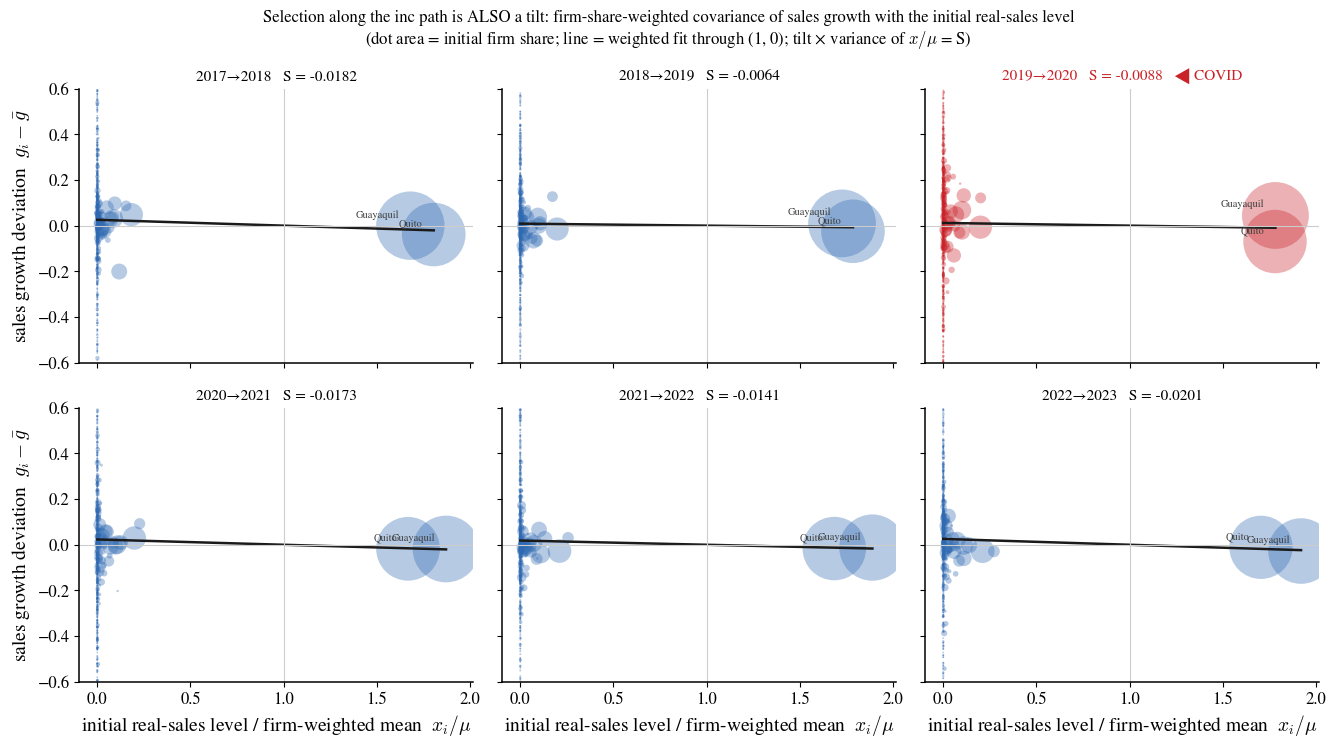


den path -- flat parish-level S vs engine cumulative multiscale:
  2017->2018: flat -0.009018  engine -0.007486  same sign=True
  2018->2019: flat -0.014390  engine -0.012549  same sign=True
  2019->2020: flat +0.004288  engine +0.004986  same sign=True
  2020->2021: flat -0.009681  engine -0.008983  same sign=True
  2021->2022: flat -0.012217  engine -0.011083  same sign=True
  2022->2023: flat -0.012832  engine -0.011738  same sign=True


saved -> results/selection_anatomy/selection_flip_scatter_den.png


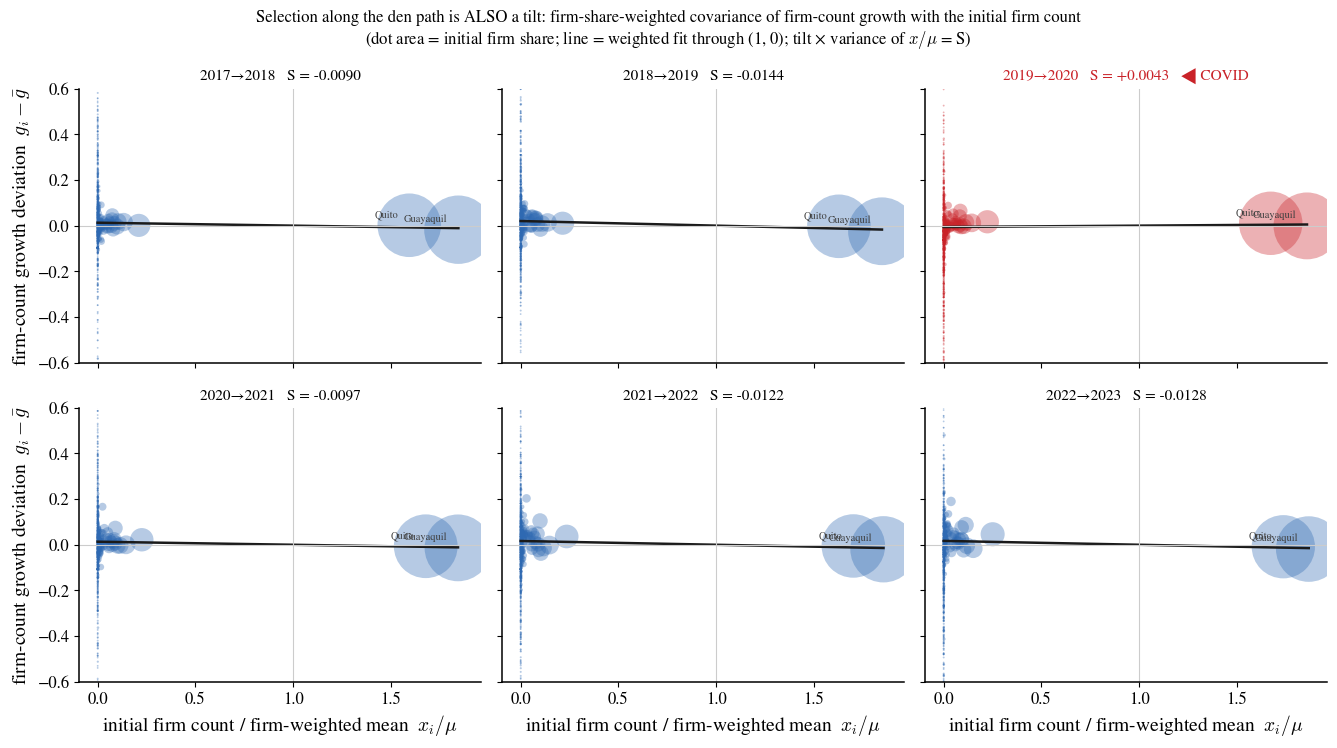

In [15]:
# ==============================================================================
# STEP G (cont.) -- the same tilt for the OTHER two paths: _inc and _den
# ------------------------------------------------------------------------------
# The scatter above draws the pop-path (Price) selection. The engine's other
# two paths are Olley-Pakes style: with the SAME initial firm-share weights p,
#     S = sum_i p_i (g_i - gbar) (x_i - mu) / mu
#   inc: x = real-sales LEVEL,   g = real-sales log growth (annualised)
#   den: x = FIRM COUNT itself,  g = firm-count log growth
# where mu = sum p x (the firm-weighted "experienced" mean) and gbar = sum p g.
# Plotting x/mu on the x axis (dimensionless, mean at 1) and g - gbar on the y
# axis makes S = Cov_p(g, x/mu): the p-weighted fit line's tilt IS selection,
# exactly as in the pop figure -- the math is in the markdown below.
# VERIFICATION CAVEAT: the flat parish->country covariance recomputed here
# matches the engine's cumulative multiscale selection (master run,
# selection_by_step.csv) in sign and magnitude but NOT to machine precision:
# the O-P machinery renormalizes each level by its own mu, so the three-scale
# sum does not telescope into one flat covariance the way the pop path does.
# ==============================================================================
MASTER_BY_STEP = YEARLY_DIR / "selection_by_step.csv"


def op_selection_table(y0, y1, X):
    'Per-parish ingredients of an Olley-Pakes path (X=SALES -> inc, X=FIRMS -> den).'
    surv = sorted(VALID[y0] & VALID[y1])
    n0 = FIRMS.loc[surv, y0]
    p  = n0 / n0.sum()                                    # initial firm share
    x0 = X.loc[surv, y0]                                  # initial level (the trait)
    g  = (np.log(X.loc[surv, y1]) - np.log(x0)) / (y1 - y0)   # annualised log growth
    mu, gbar = (p * x0).sum(), (p * g).sum()              # firm-weighted means
    t = pd.DataFrame({"p": p, "gdev": g - gbar, "xrel": x0 / mu})
    t["contrib"] = t["p"] * t["gdev"] * (t["xrel"] - 1)   # sums to S (already per yr)
    return t


mast = pd.read_csv(MASTER_BY_STEP)
#         path   levels   x-axis trait            y-axis growth
OP_PATHS = [("inc", SALES, "real-sales level",    "sales growth"),
            ("den", FIRMS, "firm count",          "firm-count growth")]

for path, X, xname, gname in OP_PATHS:
    eng_p = mast[mast.path == path].set_index("window")
    print(f"\n{path} path -- flat parish-level S vs engine cumulative multiscale:")
    for y0, y1 in pairs:
        mine   = op_selection_table(y0, y1, X)["contrib"].sum()
        theirs = eng_p.loc[f"{y0}_to_{y1}", "selection_total"]
        print(f"  {y0}->{y1}: flat {mine:+.6f}  engine {theirs:+.6f}  "
              f"same sign={np.sign(mine) == np.sign(theirs)}")

    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.6), sharex=True, sharey=True)
    for ax, (y0, y1) in zip(axes.ravel(), pairs):
        t = op_selection_table(y0, y1, X)
        covid = (y0, y1) == COVID_PAIR
        S = t["contrib"].sum()
        # weighted fit line: slope = cov_w/var_w, through (1, 0) since both the
        # p-weighted mean of gdev and of xrel-1 are 0 by construction
        b = S / (t["p"] * (t["xrel"] - 1) ** 2).sum()
        xg = np.linspace(t["xrel"].min(), t["xrel"].max(), 2)
        ax.scatter(t["xrel"], t["gdev"], s=8e3 * t["p"] + 1.5, alpha=0.35,
                   color=style.RED if covid else style.BLUE, lw=0)
        ax.plot(xg, b * (xg - 1), color="0.1", lw=1.8)
        ax.axhline(0, color="0.8", lw=0.8); ax.axvline(1, color="0.8", lw=0.8)
        for hub in ["170150", "090150"]:                  # Quito, Guayaquil
            if hub in t.index:
                ax.annotate(names.loc[hub, "DPA_DESPAR"].title(),
                            (t.loc[hub, "xrel"], t.loc[hub, "gdev"]),
                            textcoords="offset points", xytext=(-8, 6),
                            ha="right", fontsize=7.5, color="0.25")
        ax.set_title(f"{y0}→{y1}   S = {S:+.4f}" + ("   ◀ COVID" if covid else ""),
                     fontsize=11, color=style.RED if covid else "black")
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    axes.ravel()[0].set_ylim(-0.6, 0.6)                   # display clip; S uses all points
    for ax in axes[:, 0]:
        ax.set_ylabel(f"{gname} deviation  $g_i-\\bar{{g}}$")
    for ax in axes[1, :]:
        ax.set_xlabel(f"initial {xname} / firm-weighted mean  $x_i/\\mu$")
    fig.suptitle(f"Selection along the {path} path is ALSO a tilt: firm-share-weighted "
                 f"covariance of {gname} with the initial {xname}\n(dot area = initial "
                 "firm share; line = weighted fit through (1, 0); "
                 "tilt × variance of $x/\\mu$ = S)", fontsize=12)
    fig.tight_layout()
    fig.savefig(SEL_DIR / f"selection_flip_scatter_{path}.png", dpi=200,
                bbox_inches="tight")
    fig.savefig(SEL_DIR / f"selection_flip_scatter_{path}.pdf", bbox_inches="tight")
    print("saved ->", SEL_DIR / f"selection_flip_scatter_{path}.png")
    plt.show()


### The `_inc` and `_den` tilts are *also* selection — the proof, step by step

**1. Where the term comes from.** The engine's Olley–Pakes machinery decomposes, for any group of parishes, the level-weighted average growth of $x$ (real-sales level for `inc`, firm count for `den`). With $p_i$ the initial **firm share**, $x_i$ the initial **level**, $g_i=\Delta\ln x_i/\Delta t$ the annualised **log growth**, and the firm-weighted means $\mu=\sum_i p_i x_i$ and $\bar g=\sum_i p_i g_i$, the engine computes (`_part_d_calculate_selection_terms` in `runPrice.py`, `sel_inc`):

$$\text{total} \;=\; \frac{\sum_i p_i\, g_i\, x_i}{\mu}
\;=\; \underbrace{\bar g}_{\text{transmission}} \;+\; \underbrace{\frac{1}{\mu}\sum_i p_i\,(g_i-\bar g)(x_i-\mu)}_{\displaystyle S \;=\; \text{selection}}$$

The identity is two lines of algebra: $\sum_i p_i g_i x_i = \sum_i p_i g_i (x_i-\mu) + \mu\bar g$, and inside the first sum $g_i$ can be replaced by $g_i - \bar g$ because $\sum_i p_i(x_i-\mu)=0$, so $\sum_i p_i\,\bar g\,(x_i-\mu) = \bar g \cdot 0$. What is left over after transmission is **exactly** the $p$-weighted covariance of growth with the initial level, normalised by $\mu$:

$$S \;=\; \frac{\mathrm{Cov}_p(g,\,x)}{\mu}.$$

**2. From the covariance to the tilt — and back (why both are the same).** Put on the axes exactly what the figure plots: $\hat x_i = x_i/\mu$ (initial level relative to the firm-weighted mean, so $\sum_i p_i \hat x_i = 1$) and $\hat g_i = g_i-\bar g$ (growth deviation, so $\sum_i p_i \hat g_i = 0$). Dividing $x$ by the constant $\mu$ scales the covariance by $1/\mu$, hence

$$S \;=\; \frac{\mathrm{Cov}_p(g,x)}{\mu} \;=\; \mathrm{Cov}_p\big(\hat g,\,\hat x\big).$$

Now fit the $p$-weighted least-squares line of $\hat g$ on $\hat x$ — the black line in each panel. Weighted OLS gives slope and intercept

$$b \;=\; \frac{\mathrm{Cov}_p(\hat g,\hat x)}{\mathrm{Var}_p(\hat x)} \;=\; \frac{S}{\mathrm{Var}_p(\hat x)},
\qquad a \;=\; \underbrace{\textstyle\sum p\hat g}_{=0} - b\cdot \underbrace{\textstyle\sum p\hat x}_{=1} \;=\; -b,$$

so the fitted line is $\hat g = b(\hat x - 1)$: it **must** pass through $(1,0)$ — the crosshairs — and its slope satisfies

$$\boxed{\,S \;=\; b \times \mathrm{Var}_p(\hat x)\,}$$

That is the whole proof in both directions. Given the decomposition's $S$, the drawn slope is $b=S/\mathrm{Var}_p(\hat x)$; given the cloud, tilt × spread² recovers $S$ *exactly* — not an approximation, because a weighted covariance and a weighted regression slope differ only by the (positive) variance factor. Flat line ⇔ $S=0$; the sign of the tilt **is** the sign of selection. This is the same argument as the pop-path box above with two substitutions: relative fitness $w/\bar W-1$ → growth deviation $g-\bar g$, and log-sales trait $z$ → relative level $x/\mu$ (and there the crosshair sits at $(\bar z, 0)$ instead of $(1,0)$).

**3. Why the *reading* of the plot is selection, not growth.** Subtracting $\bar g$ kills every shock shared by all parishes: if the whole country speeds up or collapses uniformly, $\bar g$ (transmission) absorbs it and the cloud shifts *vertically not at all* — every $\hat g_i$ is unchanged. The only thing that can tilt the line is **differential** growth that lines up with initial size — precisely what "selection" means in the Price/O-P decomposition. Per parish, the contribution is the bilinear $p_i\,\hat g_i\,(\hat x_i-1)$: positive in the NE (big and over-growing) and SW (small and under-growing) quadrants, negative in NW/SE.

**4. What changes vs the pop scatter — and what the figures show.** Because the O-P trait is the **level** $x$, not its log, the $x$-axis compresses brutally: $\mu$ is the *size-biased* mean (the parish in which the average firm sits), so nearly every parish sits at $\hat x\approx 0$ and only Quito and Guayaquil ($\hat x\approx 1.6$–$1.9$) sit to the right of the crosshair. $S_{\text{inc}}$ and $S_{\text{den}}$ are therefore, to first order, a **metros-versus-everyone** contrast, whereas the pop path's log trait spreads all 800+ parishes along the axis and lets the small ones vote. That difference in what the axis *is* explains the empirical result printed above:

- **`den` follows `pop`**: negative tilt every normal year (small parishes out-grow the giants in firm counts — Gibrat is violated toward dispersion), and the tilt flips **positive** in 2019→20 (the metros' firm stocks held while small parishes fell behind the mean). Same fitness ingredient as pop (firm growth), so the same flip — just read on the level ladder and $/\mu$-normalised.
- **`inc` does *not* flip**: $S_{\text{inc}}<0$ in the COVID year too. In sales, the metros were hit *with* (indeed slightly worse than) everyone else — Quito's and Guayaquil's $\hat g$ sit at or below 0 in the red panel — so differential sales growth kept favouring small parishes even while differential *firm-count* growth favoured the metros. The COVID selection flip is a **demographic** (firm-formation) phenomenon, not a revenue one.

**5. One honesty note on the verification.** For the pop path the multiscale cumulative selection telescopes exactly into the flat parish-level covariance, which is why the pop cell matches the engine to machine precision. The O-P paths do not telescope: each level divides its own covariance by its **own** group mean $\mu_P$, so the engine's cumulative (between-provinces + within terms) differs from the flat parish→country covariance by the dispersion of the $\mu_P$'s. The printout above shows the two side by side — same sign in every window, same magnitude (ratios ≈ 0.7–1.2) — so the tilt drawn here is the faithful single-scale version of the same selection term, not a different quantity.


## The three paths, formally — population, income, density: every expectation, every covariance, step by step

This is the reference derivation for everything the decomposition cells compute. One window $t_0\to t_1$, elapsed time $\Delta t = t_1 - t_0$ years, and the **survivor set** of parishes valid at both ends (firms $>0$, real sales $\ge \$1{,}000$/yr at $t_0$ and $t_1$). All sums run over that set.

### 0. Common objects

For each parish $i$: $n_i(t)$ = active-firm count, $y_i(t)$ = real (deflated) total sales. From these, four ingredients that every path draws on:

$$p_i \;=\; \frac{n_i(t_0)}{N_0},\quad N_0=\sum_j n_j(t_0)
\qquad\qquad
w_i \;=\; \frac{n_i(t_1)}{n_i(t_0)},\qquad \bar W=\sum_i p_i w_i = \frac{N_1}{N_0}$$

$$g^{y}_i \;=\; \frac{\ln y_i(t_1)-\ln y_i(t_0)}{\Delta t}
\qquad\qquad
g^{n}_i \;=\; \frac{\ln n_i(t_1)-\ln n_i(t_0)}{\Delta t}\;=\;\frac{\ln w_i}{\Delta t}$$

$p_i$ is the **initial firm share** — the probability that a firm drawn uniformly at random at $t_0$ sits in parish $i$. Every expectation and covariance below is taken with respect to a *probability measure over firms*, and each path is characterised by (a) which measure, (b) which random variable. Writing $E_p[\cdot]$ and $\operatorname{Cov}_p(\cdot,\cdot)$ for moments under the weights $p$, note the identity used repeatedly below: for any $a, b$,

$$\operatorname{Cov}_p(a,b) \;=\; \sum_i p_i\,(a_i-E_p[a])(b_i-E_p[b]) \;=\; \sum_i p_i\,a_i b_i \;-\; E_p[a]\,E_p[b],$$

and $\operatorname{Cov}_p(a,b)=\sum_i p_i\,(a_i-E_p[a])\,b_i$ — one factor may be left uncentred because the other is already centred.

---

### 1. Population path — the Price equation on the trait $z=\ln y$

**The decomposed object.** The trait is $z_i(t)=\ln y_i(t)$, log real sales of the parish. The tracked aggregate is the **firm-weighted mean trait**

$$\bar z(t) \;=\; E_{p(t)}\big[z(t)\big] \;=\; \sum_i p_i(t)\, z_i(t)
\qquad\text{= the log revenue of the parish in which the average firm sits.}$$

Both the *weights* and the *trait* move between $t_0$ and $t_1$ — the Price equation splits $\Delta\bar z$ into the part due to each.

**Step 1 — how the measure moves.** The final firm share is

$$p_i(t_1) \;=\; \frac{n_i(t_1)}{N_1} \;=\; \frac{n_i(t_0)\,w_i}{N_0\,\bar W} \;=\; p_i\,\frac{w_i}{\bar W}\;\equiv\;p'_i .$$

Reweighting by relative fitness $w_i/\bar W$ **is** the change of measure — this is where "selection" enters mechanically: parishes with above-average firm growth gain probability mass.

**Step 2 — add and subtract.** With $\Delta z_i = z_i(t_1)-z_i(t_0)$,

$$\begin{aligned}
\Delta \bar z \;=\; \bar z(t_1)-\bar z(t_0)
&\;=\; \sum_i p_i \frac{w_i}{\bar W}\, z_i(t_1) \;-\; \sum_i p_i\, z_i(t_0) \\[2pt]
&\;=\; \sum_i p_i \frac{w_i}{\bar W}\,\big(z_i(t_0)+\Delta z_i\big) \;-\; \sum_i p_i\, z_i(t_0) \\[2pt]
&\;=\; \underbrace{\sum_i p_i\Big(\frac{w_i}{\bar W}-1\Big)\, z_i(t_0)}_{\text{weights moved, trait frozen}}
\;+\; \underbrace{\sum_i p_i \frac{w_i}{\bar W}\,\Delta z_i}_{\text{trait moved, under the new weights}} .
\end{aligned}$$

**Step 3 — recognise the moments.** Since $E_p[w/\bar W - 1]=0$, the first bracket is a covariance with one factor uncentred; the second is an expectation under the final measure $p'$:

$$\boxed{\;\frac{\Delta\bar z}{\Delta t}
\;=\; \underbrace{\frac{1}{\Delta t}\operatorname{Cov}_p\!\Big(\frac{w}{\bar W},\, z(t_0)\Big)}_{S_{\text{pop}}\;=\;\texttt{selection\_total}}
\;+\; \underbrace{E_{p'}\!\Big[\frac{\Delta z}{\Delta t}\Big]}_{T_{\text{pop}}\;=\;\texttt{transmission}}\;}$$

So the pop path is: **selection = a covariance under the *initial* firm measure** (between relative firm fitness and the initial log-revenue trait) and **transmission = an expectation under the *final* firm measure** (of each parish's own log-revenue growth). Note the asymmetry of measures — it is exact, not a convention: selection uses $p$ because it prices the *initial* position of each parish; transmission uses $p'$ because the growth a firm experiences is weighted by where firms *ended up*.

**Units.** $w/\bar W$ is dimensionless; $z$ is in log dollars, but a change of currency or deflator base multiplies $y$ by a constant $c$, i.e. shifts $z$ by $\ln c$ — and both $\operatorname{Cov}_p(\cdot, z)$ and $\Delta z_i$ are invariant to additive shifts. Hence $S_{\text{pop}}$, $T_{\text{pop}}$, $\Delta\bar z/\Delta t$ are all pure numbers per year: **log points per year** ($0.01 \approx 1\%/\text{yr}$).

---

### 2. Income path — Olley–Pakes on the level $x=y$

**The decomposed object.** Here the trait is the sales **level** itself, $y_i(t_0)$, and the growth variable is $g^y_i$. Define the firm-weighted mean level and mean growth

$$\mu_y \;=\; E_p[y(t_0)] \;=\; \sum_i p_i\, y_i(t_0)
\qquad\qquad
\bar g^y \;=\; E_p[g^y],$$

$\mu_y$ = the *experienced* revenue level: total sales of the parish where the average firm sits (a size-biased mean — big parishes count once per firm). The engine's `inc` total is

$$G_{\text{inc}} \;=\; \frac{\sum_i p_i\, g^y_i\, y_i(t_0)}{\mu_y}
\;=\; \sum_i q_i\, g^y_i \;=\; E_q\big[g^y\big],
\qquad q_i \;\equiv\; \frac{p_i\, y_i(t_0)}{\mu_y},\;\; \sum_i q_i = 1 .$$

$q$ is a second change of measure — the **size-biased tilt** of $p$ by the level $y$ (weight $\propto n_i\,y_i$). So the object is *"mean sales growth, weighted by where the sales level actually sits."* (In continuous time $g_i y_i = \dot y_i$, so $G_{\text{inc}} = \big(\tfrac{d}{dt}\sum_i p_i y_i\big)/\mu_y$ at frozen shares: the growth rate of the experienced revenue level.)

**Step 1 — split $E_q$ against $E_p$.** Using $\sum_i p_i g^y_i y_i = \operatorname{Cov}_p(g^y, y) + \bar g^y \mu_y$ (the covariance identity of §0):

$$E_q[g^y] \;=\; \frac{\operatorname{Cov}_p(g^y,\,y) + \bar g^y\,\mu_y}{\mu_y}
\;=\; \bar g^y \;+\; \frac{\operatorname{Cov}_p(g^y,\,y)}{\mu_y}.$$

**Step 2 — name the pieces.**

$$\boxed{\;\underbrace{E_q[g^y]}_{G_{\text{inc}}}
\;=\; \underbrace{E_p[g^y]}_{T_{\text{inc}}\;=\;\texttt{transmission}}
\;+\; \underbrace{\frac{\operatorname{Cov}_p(g^y,\,y)}{\mu_y}}_{S_{\text{inc}}\;=\;\texttt{selection\_total}}\;}$$

Read it as a **reweighting gap**: selection is exactly the difference between the size-biased mean growth and the plain firm-weighted mean growth,

$$S_{\text{inc}} \;=\; E_q[g^y] - E_p[g^y].$$

If big-revenue parishes grow their sales faster than small ones, tilting the measure toward them ($p\to q$) raises the mean — $S_{\text{inc}}>0$; if the small out-grow the big, $S_{\text{inc}}<0$. No differential growth, no gap. Both moments here live on the **initial** measure(s); unlike the Price path, nothing is evaluated under final weights — instead the second measure is the *size tilt* $q$, not the *fitness tilt* $p'$.

**Units — why the $/\mu_y$ must be there.** $g^y$ is per year; $y$ is in dollars. So $\operatorname{Cov}_p(g^y, y)$ has units **dollars/yr** — it depends on the currency and deflator base. Dividing by $\mu_y$ (dollars) cancels the scale: under $y\mapsto c\,y$ both numerator and denominator pick up $c$, and $S_{\text{inc}}$ is a pure number per year. The normalisation plays *for the level* the role the logarithm plays *for the trait* in the pop path; equivalently $S_{\text{inc}}=\operatorname{Cov}_p(g^y,\, y/\mu_y)$, a covariance with the dimensionless relative size — which is precisely what the `inc` scatter plots.

---

### 3. Density path — the same machinery on the level $x=n$

Substitute the firm count for sales everywhere in §2: trait $n_i(t_0)$, growth $g^n_i$, and

$$\mu_n \;=\; E_p[n(t_0)] \;=\; \sum_i \frac{n_i(t_0)^2}{N_0} \;=\; N_0 \times \mathrm{HHI},
\qquad
r_i \;\equiv\; \frac{p_i\,n_i(t_0)}{\mu_n}\;\propto\; n_i(t_0)^2 .$$

$\mu_n$ is the **experienced density** — the firm count of the parish in which the average firm sits (hence $N\times$HHI, the Herfindahl of firm shares). The identical two steps give

$$\boxed{\;\underbrace{E_r[g^n]}_{G_{\text{den}}}
\;=\; \underbrace{E_p[g^n]}_{T_{\text{den}}}
\;+\; \underbrace{\frac{\operatorname{Cov}_p(g^n,\,n)}{\mu_n}}_{S_{\text{den}}}\;}
\qquad\text{with}\qquad
S_{\text{den}} \;=\; E_r[g^n]-E_p[g^n].$$

**Interpretation.** $S_{\text{den}}$ is the per-year relative drift of the experienced density caused purely by differential firm growth — a **Gibrat test**: under proportional growth ($g^n_i$ independent of $n_i$, "a parish's growth rate doesn't depend on its size"), the covariance is identically zero at every scale. $S_{\text{den}}<0$ = the firm mass disperses (small parishes out-grow dense ones); $S_{\text{den}}>0$ = it concentrates. Units: $g^n$ per year, $n$ and $\mu_n$ in firms — the ratio is again a pure number per year, directly comparable to $S_{\text{inc}}$.

---

### 4. The dictionary — how each path maps into the others (and where it can't)

$$\begin{array}{l|c|c|c|c}
\textbf{path} & \textbf{object decomposed} & \textbf{transmission (expectation)} & \textbf{selection (covariance)} & \textbf{units}\\[2pt]\hline
\texttt{pop} & \Delta\, E_{p(t)}[\ln y]/\Delta t & E_{p'}[\Delta \ln y/\Delta t]\;\;(p'\!=\text{final shares}) & \tfrac{1}{\Delta t}\operatorname{Cov}_p\!\big(w/\bar W,\ \ln y\big) & \text{log pts/yr}\\[4pt]
\texttt{inc} & E_q[g^y],\;\; q\propto n\,y & E_p[g^y]\;\;(p=\text{initial shares}) & \operatorname{Cov}_p\!\big(g^y,\ y\big)/\mu_y & 1/\text{yr}\\[4pt]
\texttt{den} & E_r[g^n],\;\; r\propto n^2 & E_p[g^n] & \operatorname{Cov}_p\!\big(g^n,\ n\big)/\mu_n & 1/\text{yr}
\end{array}$$

All three share the initial firm measure $p$ in the selection covariance; they differ in *which second measure* defines the decomposed object ($p'$ = fitness-tilted for `pop`; $q, r$ = size-tilted for `inc`, `den`) and in *which pair of variables* enters the covariance.

**`inc` ↔ `den`: an exact isomorphism.** Replace $y \to n$ and every formula in §2 becomes §3, term for term. (Operationally that is literally how the engine computes `den`: a second run with the trait columns holding $n$, whose `_inc`-named outputs are renamed `den`.) Any statement proved for one holds for the other with the variable swapped.

**`den` ↔ `pop`: first-order equivalent fitness, different trait ladder.** The two fitness variables are transforms of the same object $w_i$:

$$g^n_i - \bar g^n \;=\; \frac{\ln w_i - E_p[\ln w]}{\Delta t},
\qquad
\frac{w_i}{\bar W}-1 \;=\; \frac{w_i - E_p[w]}{E_p[w]} ,$$

and for growth factors near 1, $\ln w_i \approx w_i - 1$, so **the two $y$-axes agree to first order in growth rates**; they separate only at second order (Jensen curvature: $E_p[\ln w] \le \ln E_p[w]$, with gap $\approx \tfrac12\operatorname{Var}_p(w)/\bar W^2$). The genuine difference is the **trait**: `pop` covaries firm fitness with $\ln y$ (the *revenue* ladder, in logs), `den` with $n$ (the *count* ladder, in levels). Both ask "does differential firm formation line up with size?", measuring size on different ladders — which is why they moved together empirically, COVID flip included.

**level ↔ log: the expansion that connects (and separates) them.** For any fitness variable $f$ and positive trait $x$ with mean $\mu$, expand $\ln x$ around $\mu$:

$$\ln x \;=\; \ln\mu \;+\; \frac{x-\mu}{\mu} \;-\; \frac{(x-\mu)^2}{2\mu^2} \;+\; \cdots
\quad\Longrightarrow\quad
\operatorname{Cov}_p(f,\ln x) \;=\; \frac{\operatorname{Cov}_p(f,x)}{\mu}\;-\;\frac{\operatorname{Cov}_p\!\big(f,(x-\mu)^2\big)}{2\mu^2}\;+\;\cdots$$

If parish sizes were tightly clustered around $\mu$, a log-trait covariance and a $/\mu$-normalised level covariance would be the same number — "getting from one to the other" is just this expansion. But parish sizes span **orders of magnitude**, so the expansion does not close: the level trait weights a parish's leverage *linearly in its size* (Quito's deviation $y-\mu$ is thousands of times a rural parish's), while the log trait prices a *doubling* equally anywhere on the ladder. This is not a nuisance — it is the substantive difference between the paths: `inc`/`den` selection is a statement about the giants versus the rest; `pop` selection lets all 800+ parishes vote.

**`pop` ↔ `inc`: no reduction.** These differ in *both* slots — fitness ($w$ from firm counts vs $g^y$ from sales) *and* trait ($\ln y$ vs $y$) — so neither is an approximation of the other, and they may legitimately disagree in sign. The COVID year is the proof by example: $S_{\text{pop}}>0$ and $S_{\text{den}}>0$ (firm *formation* concentrated toward big parishes) while $S_{\text{inc}}<0$ (sales *growth* still favoured the small ones). One shock, two different covariances, two different answers — both correct.

---

### 5. How to interpret each number

- $S_{\text{pop}}$ (log pts/yr): per year, how much the log revenue of the average firm's parish changes **purely because firms re-locate mass along the revenue ladder** (formation/closure), holding every parish's own revenue fixed. Negative (its structural sign here) = formal-firm formation disperses down-ladder; the 2019→20 positive is the concentration flip.
- $T_{\text{pop}}$ (log pts/yr): the real revenue growth **experienced by the average surviving firm in its own parish** — the within-place growth channel; it, not selection, carries the COVID collapse (−0.155 in 2019→20).
- $S_{\text{inc}}$ (1/yr): the gap $E_q[g^y]-E_p[g^y]$ — how much faster the *experienced* revenue level grows than the plain mean, i.e. whether the revenue mass is concentrating ($>0$) or dispersing ($<0$) in relative terms. Persistently negative, COVID included: mean reversion in revenue levels, metros never out-grow the pack in sales.
- $S_{\text{den}}$ (1/yr): the relative drift of experienced density $N\times$HHI due to differential firm growth — the Gibrat deviation. Negative structurally (deconcentration of the firm mass), positive only in 2019→20.
- All three selection terms are per-year pure numbers (log pts/yr and 1/yr coincide to first order), so magnitudes are directly comparable across paths — the engine's multiscale identity $\text{total}=\text{selection}+\text{transmission}$ holds exactly for each path at every scale.


### Why selection flipped — what the three figures say

**The normal regime (every non-COVID year): $S<0$ because formal-firm formation disperses down the size ladder.** The cloud tilts down — small, low-revenue parishes add firms at above-average *rates*, while the giant parishes grow slowest. The decile chart shows the negative total is dominated by the **top decile** (−13 to −33 ×10⁻³, i.e. Quito and Guayaquil expanding their firm stocks *more slowly* than the country) with a broad shallow negative from everyone else.

**2019→20: both ends of the covariance changed sign at once.** The national average firm growth collapsed to ≈ 0, and around that new low bar:
- **Quito stayed slightly above average** (relative fitness +0.9%, firm share p = 0.26, trait deviation +2.4) — its single contribution is **+0.0056, about 16% of the whole +0.034 flip**. Guayaquil sat almost exactly at the average (−0.25%), pulling mildly against (−0.0017).
- **The swarm of small parishes fell below average** — small ($z<\bar z$) × under-growing ($w<\bar W$) = *positive* contribution. That is why in the COVID panel **every size decile turns positive**: the usual catch-up of small parishes didn't just pause, it inverted.

So the flip is exactly the phenomenon asked about earlier — *during COVID, formal firms held on in the big-revenue parishes while the small parishes' firm formation collapsed* — but it is a **size (trait) effect, not a proximity effect**: the distance-to-hub analysis (STEP F) found essentially no gradient, whereas the selection covariance, which conditions on the parish's *own* revenue, flips strongly. Being big protected a parish; being *near* something big did not.

**Scale:** the engine's nested split shows the flip happened **at all three scales simultaneously** — between provinces (+0.015), cantons within provinces (+0.008), *and* parishes within cantons (+0.011) — each of which is negative in every normal year. The concentration-shock was self-similar across the hierarchy, unlike the (absent) distance gradient.

**Aftermath:** 2020→21 snaps straight back to the normal dispersion regime (−0.035). But note **2022→23**: the small/mid deciles turn positive again while the top decile drags hard (−33 ×10⁻³) — total S is still negative only because of the giants. Combined with the firm-formation stall seen in STEP E, the post-2022 pattern of small-parish underperformance looks like a partial echo of the COVID configuration, worth watching in 2024 data.

## Which parishes carried the +selection — and who took the transmission hit

Transmission decomposes over parishes exactly like selection does. For the population path the identity is

$$\underbrace{\tfrac{1}{n}\sum_i p_i\Big(\tfrac{w_i}{\bar W}-1\Big)(z_i-\bar z)}_{S\ \text{(selection)}}\;+\;\underbrace{\tfrac{1}{n}\sum_i q_i\,\Delta z_i}_{T\ \text{(transmission)}}\;=\;\Delta\bar z, \qquad q_i=\frac{n_{i1}}{\sum_j n_{j1}}$$

so each parish owns one **selection contribution** (its firm-share-weighted covariance term) and one **transmission contribution** (its own change in $\ln$ real sales, weighted by its **final** firm share $q_i$). Both are verified below to sum exactly to the engine's `selection_total` and `transmission`.

Two different "who" questions, two different views:
- **Ranked bars** — the largest *aggregate* contributors. Transmission weighted by firm share is inevitably dominated by the metros; that is the honest answer to "who dragged the national number".
- **Maps + the raw-hit list** — where things happened on the ground. For "who was hit hardest" the unweighted $\Delta z_i$ (each parish's own real-sales log change) is the right quantity, restricted to parishes with at least `MIN_FIRMS` firms so tiny-parish noise doesn't top the list. Parish names come from `raw data/dpa.xlsx` (the shapefile lacks Galápagos — it appears in the bars/lists but not on the maps).

verify per-parish sums vs engine (pop path):
  2017->2018: S -0.0451  T +0.0641  match=True
  2018->2019: S -0.0597  T +0.0139  match=True
  2019->2020: S +0.0342  T -0.1552  match=True
  2020->2021: S -0.0346  T +0.2124  match=True
  2021->2022: S -0.0338  T +0.1129  match=True
  2022->2023: S -0.0183  T +0.0442  match=True


saved -> results/selection_anatomy/covid_carriers_bars.png


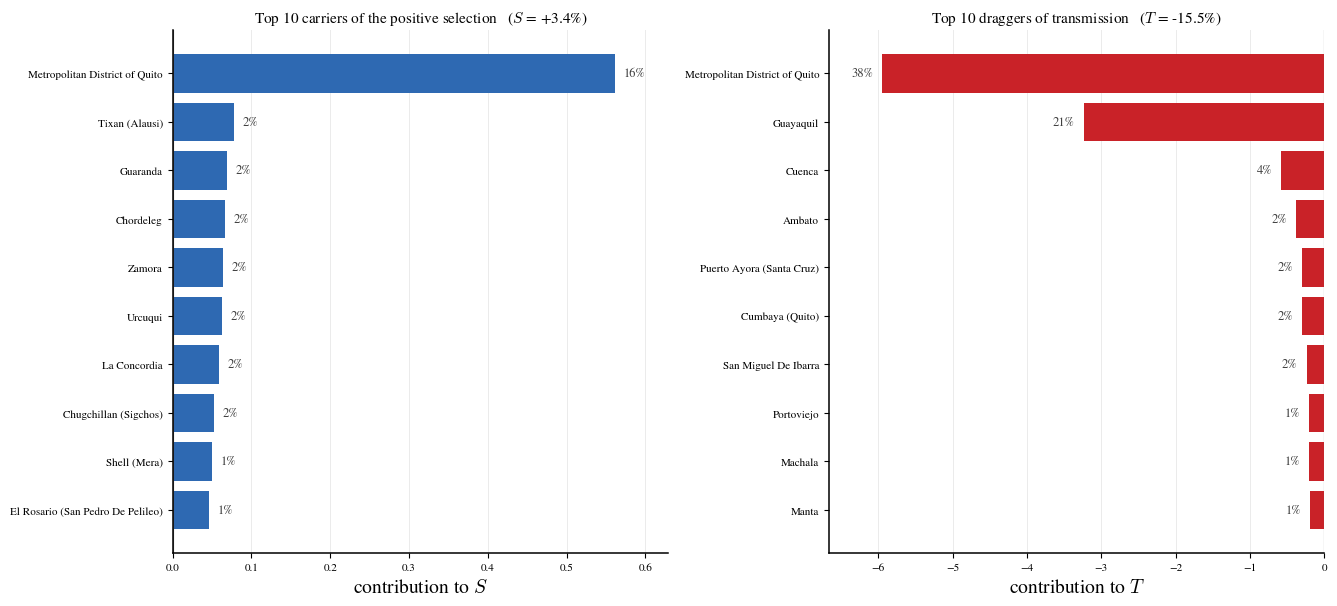


Top 10 carriers of the positive selection   ($S$ = +3.4%)
  Metropolitan District of Quito      +0.561 %/yr   16.4% of term
  Tixan (Alausi)                      +0.077 %/yr    2.3% of term
  Guaranda                            +0.069 %/yr    2.0% of term
  Chordeleg                           +0.066 %/yr    1.9% of term
  Zamora                              +0.064 %/yr    1.9% of term
  Urcuqui                             +0.062 %/yr    1.8% of term
  La Concordia                        +0.059 %/yr    1.7% of term
  Chugchillan (Sigchos)               +0.052 %/yr    1.5% of term
  Shell (Mera)                        +0.049 %/yr    1.4% of term
  El Rosario (San Pedro De Pelileo)   +0.046 %/yr    1.4% of term

Top 10 draggers of transmission   ($T$ = -15.5%)
  Metropolitan District of Quito      -5.950 %/yr   38.3% of term
  Guayaquil                           -3.237 %/yr   20.9% of term
  Cuenca                              -0.578 %/yr    3.7% of term
  Ambato                         

In [16]:
# ==============================================================================
# STEP H -- per-parish selection AND transmission contributions + ranked bars
# ------------------------------------------------------------------------------
# price_table() extends selection_table() with the transmission side: q = FINAL
# firm share, dz = own annualised change in ln(real sales), trans_c = q*dz.
# Identity check: sum(sel_c) == selection_total and sum(trans_c) == transmission
# in selection_transmission_by_year.csv, for every annual step.
# Display names: "Parish (Canton)", canton dropped when it only repeats the
# parish; the handful of official names that are a paragraph long are renamed by
# hand. PARR_NAME (code -> display name) is reused by the map cells below.
# ==============================================================================
import re

dpa = pd.read_excel(paths.DPA_XLSX, dtype=str, header=None)
dpa = dpa[dpa[1].astype(str).str.match(r"^\d{6}$", na=False)]
PARR_RAW = {c: (p.title().strip(), k.title().strip())
            for c, k, p in zip(dpa[1], dpa[5], dpa[7])}   # code -> (parish, canton)

RENAME = {"170150": "Metropolitan District of Quito"}


def parish_name(code):
    'dpa.xlsx first (has Galápagos), shapefile second (has post-2010 units), code last.'
    if code in RENAME:
        return RENAME[code]
    if code in PARR_RAW:
        parr, cant = PARR_RAW[code]
    elif code in names.index:
        parr = names.loc[code, "DPA_DESPAR"].title()
        cant = names.loc[code, "DPA_DESCAN"].title()
    else:
        return code
    parr = re.sub(r"\s*\(.*?\)", "", parr).strip()      # 'El Rosario (Rumichaca)'
    return parr if parr.lower() in cant.lower() or cant.lower() in parr.lower() \
        else f"{parr} ({cant})"


PARR_NAME = {c: parish_name(c) for c in PARR_RAW}


def price_table(y0, y1):
    'Per-parish selection AND transmission contributions (pop path).'
    surv = sorted(VALID[y0] & VALID[y1])
    n0, n1 = FIRMS.loc[surv, y0], FIRMS.loc[surv, y1]
    z0, z1 = np.log(SALES.loc[surv, y0]), np.log(SALES.loc[surv, y1])
    n = y1 - y0
    p, q = n0 / n0.sum(), n1 / n1.sum()          # initial / FINAL firm shares
    w = n1 / n0
    W, Z0 = (p * w).sum(), (p * z0).sum()
    t = pd.DataFrame({"p": p, "q": q, "relfit": w / W - 1, "z0": z0,
                      "dz": (z1 - z0) / n})
    t["sel_c"]   = t["p"] * t["relfit"] * (t["z0"] - Z0) / n
    t["trans_c"] = t["q"] * t["dz"]
    t["name"] = [parish_name(i) for i in t.index]
    return t


print("verify per-parish sums vs engine (pop path):")
for y0, y1 in pairs:
    t = price_table(y0, y1)
    ok = (np.isclose(t.sel_c.sum(),   eng.loc[f"{y0}_to_{y1}", "selection_total"]) and
          np.isclose(t.trans_c.sum(), eng.loc[f"{y0}_to_{y1}", "transmission"]))
    print(f"  {y0}->{y1}: S {t.sel_c.sum():+.4f}  T {t.trans_c.sum():+.4f}  match={ok}")

# ---- the two ranked bars -----------------------------------------------------
# S and T are shares of the year's change in mean log real sales, so x100 reads
# straight off as "% per year". Each bar end carries that parish's share of the
# term named in the panel title -- the magnitude is on the axis, so it is not
# printed twice.
t = price_table(*COVID_PAIR)
K = 10
S_TOT, T_TOT = t.sel_c.sum(), t.trans_c.sum()

panels = [(t.nlargest(K, "sel_c"), "sel_c", S_TOT, style.SELECTION,
           f"Top {K} carriers of the positive selection   ($S$ = {S_TOT * 100:+.1f}%)",
           r"contribution to $S$"),
          (t.nsmallest(K, "trans_c"), "trans_c", T_TOT, style.TRANSMISSION,
           f"Top {K} draggers of transmission   ($T$ = {T_TOT * 100:+.1f}%)",
           r"contribution to $T$ ")]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.2))
for ax, (sub, col, tot, color, title, xlab) in zip(axes, panels):
    sub = sub.iloc[::-1]                                   # biggest at the top
    val, share = sub[col] * 100, sub[col] / tot
    ax.barh(sub["name"], val, color=color)
    pad = 0.02 * val.abs().max()
    for y, (v, sh) in enumerate(zip(val, share)):
        ax.text(v + pad * np.sign(v), y, f"{sh:.0%}", fontsize=9, color="0.25",
                va="center", ha="left" if v > 0 else "right")
    ax.set_xlim(min(0, val.min() * 1.12), max(0, val.max() * 1.12))
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlab)
    ax.axvline(0, color="0.4", lw=0.8)
    ax.grid(axis="x", color="0.92", lw=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(SEL_DIR / f"covid_carriers_bars.{ext}", dpi=200, bbox_inches="tight")
print("saved ->", SEL_DIR / "covid_carriers_bars.png")
plt.show()

for sub, col, tot, _, title, _ in panels:
    print(f"\n{title}")
    for _, r in sub.iterrows():
        print(f"  {r['name']:<34s} {r[col] * 100:+7.3f} %/yr   {r[col] / tot:5.1%} of term")

### Who carried what — the two lists side by side

**The +selection flip was carried by one resilient giant plus hundreds of small casualties.** Quito alone contributes +5.6 ×10⁻³ (≈ 16% of S = +0.034) *from the top end* — its firm stock kept growing slightly above the collapsed national average. Every other name in the top-15 works *from the bottom end*: small, low-revenue parishes (Tixán, Guaranda, Chordeleg, Zamora, Urcuquí, Chugchillán…) whose firm counts fell well below average — small × under-growing = positive contribution, each worth ≲ 0.8 ×10⁻³, and the map shows this faint red tint spread across essentially the whole country. The deep-blue rebels on the selection map are the anti-pattern parishes: Guayaquil satellites (Daule) and Santo Domingo, big-ish places that kept *adding* firms through the shock.

**The transmission hit has two honest answers.**
- *Weighted* (who dragged the national T = −0.155): overwhelmingly the metros — **Quito −59 ×10⁻³ and Guayaquil −32 ×10⁻³ together account for ≈ 59%** of the national transmission collapse, followed by Cuenca, Ambato and the other provincial capitals. With ≈ 55% of all firms between them, their incumbents' sales collapse *is* most of the aggregate number.
- *Raw* (who was hit hardest locally, ≥ 100 firms): a tourism/transport/extraction roll-call — **Puerto Ayora (Galápagos) −69%**, La Concordia −46%, **Baños de Agua Santa −40%**, **Tababela (Quito's airport parish) −36%**, Puerto Francisco de Orellana (El Coca, oil) −33%, Nayón −30%, Puerto Baquerizo Moreno −28%, Zaruma (mining) −26%, plus Ambato and Latacunga among the big commercial cities.

**The synthesis worth keeping:** Quito tops *both* lists. Its incumbent firms' sales collapsed harder than almost anywhere (transmission), yet its *firm count* held above average (selection) — the two terms move on different margins (intensive vs extensive), and COVID split them in opposite directions in the same place. Meanwhile the hardest local hits track *industry exposure* (tourism gateways, the airport parish, oil towns), not remoteness — one more reason the distance-to-hub gradient in STEP F came out empty.

### What a positive or negative selection contribution means for ONE parish

National selection is a sum of per-parish products $s_i = p_i\,(w_i/\bar W - 1)\,(z_i-\bar z)$, so each parish's sign comes from a simple **quadrant rule** — is it bigger or smaller than the (firm-weighted) average parish, and is its firm stock growing faster or slower than the (firm-weighted) average?

| | **grows faster than avg** $(w_i>\bar W)$ | **grows slower than avg** $(w_i<\bar W)$ |
|---|---|---|
| **high-revenue parish** $(z_i>\bar z)$ | **+** concentration: the big get busier (COVID Quito) | **−** dispersion: the big lag (normal-year Quito/Guayaquil) |
| **low-revenue parish** $(z_i<\bar z)$ | **−** dispersion: catch-up from below (normal-year small parishes) | **+** concentration: the small fall behind (COVID small parishes) |

Two things follow. First, a parish's sign says nothing about whether it is doing well *absolutely* — a small parish that merely grows *slower than average* contributes positively (it pushes firm activity toward the top). Second, the *magnitude* is scaled by the parish's firm share $p_i$ **and** by how far it sits from the average size $|z_i-\bar z|$: that is why Quito and Guayaquil, with ≈ a quarter of all firms each and traits ≈ 2.4 log points above the mean, can dominate the national number with relative-fitness deviations of *under one percentage point*, while a tiny remote parish needs a huge growth swing to register at all.

So "negative selection" nationally = the bottom-left + top-right quadrants outweigh the others (firm formation flowing *down* the size ladder), and the COVID flip = the whole cloud rotating into the top-left + bottom-right quadrants (formation retreating *up* the ladder).

## STEP I — why Quito? The two metros' opposite selection signs, unpacked

STEP H left a puzzle. In the COVID step **Quito is the single largest *positive* selection contributor and Guayaquil the single largest *negative* one**, even though they are the two most similar units in the country (both huge, both far above $\bar z$) — and *both* are top transmission draggers. By the quadrant rule above, with $z\gg\bar z$ their selection sign is decided purely by whether their firm stock grew faster or slower than the firm-weighted national average, so the whole difference rides on a small relative-fitness gap. The two cells below chase that gap into the micro data:

1. **the monthly firm-stock trajectories** of the two metro parishes through the pandemic (did anyone actually *lose* firms?), and
2. **a CIIU-section decomposition** of each metro's 2019→20 firm-count change (which industries created Quito's edge).

Data note: firm counts here are *active-taxpayer stocks* (RUC registrations active with the SRI), so they measure formal-firm existence, not activity — a firm can have near-zero sales and still be counted. That is exactly why the extensive margin (selection) and the intensive margin (transmission) can point in opposite directions in the same city.

saved -> results/selection_anatomy/metro_firm_stock_monthly.png


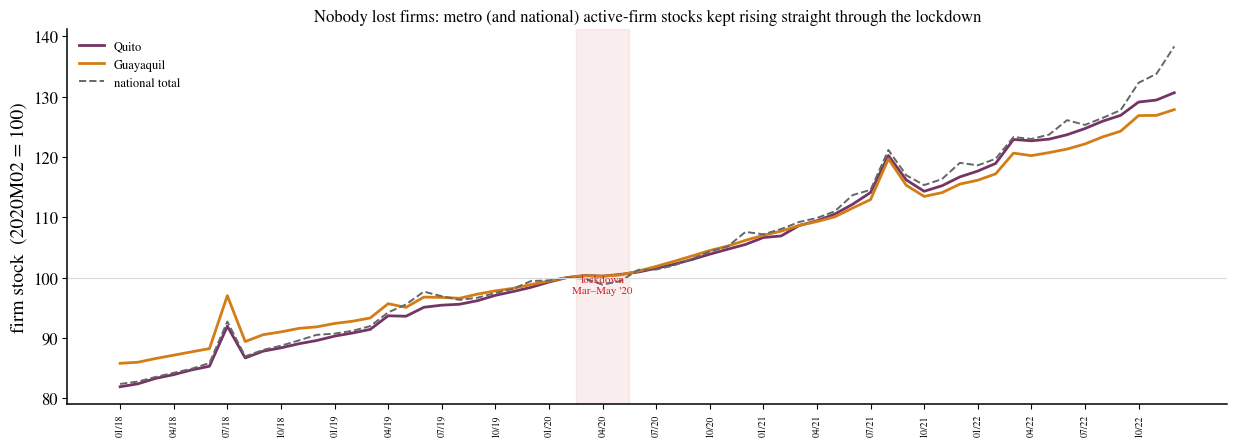


firm-weighted national fitness in the COVID step: W = 1.0669 (+6.7% firm growth)
               p  relfit       z0   sel_c      dz  trans_c       name  own_growth  sales_pct
cod_parr                                                                                    
170150    0.2606  0.0090  24.5332  0.0056 -0.2263  -0.0595      Quito      0.0765    -0.2025
090150    0.2895 -0.0025  24.5344 -0.0017 -0.1121  -0.0324  Guayaquil      0.0643    -0.1061
saved -> results/selection_anatomy/metro_sales_monthly.png


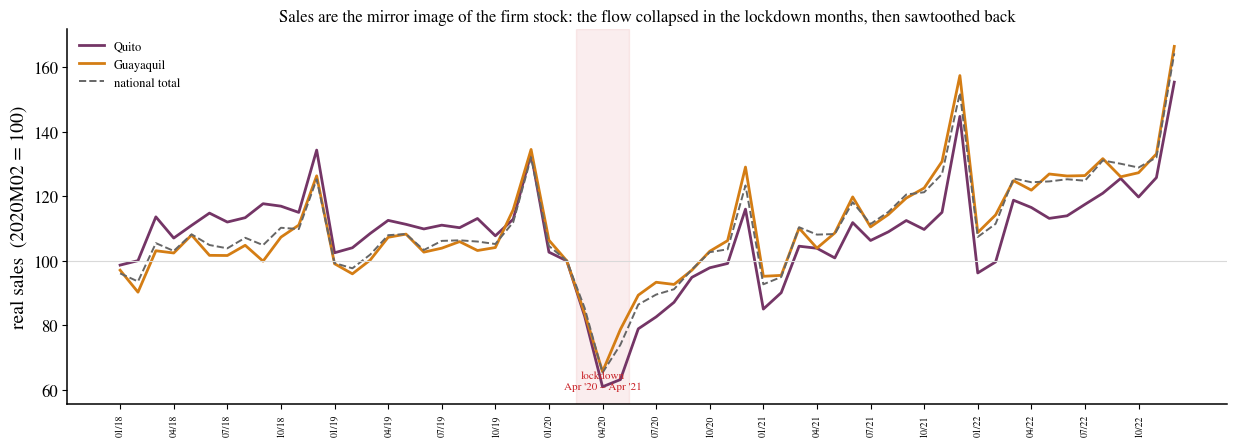

Quito      Apr-2020 sales =  61.0 (Feb-2020 = 100); first month back at 100: 2020M12
Guayaquil  Apr-2020 sales =  65.7 (Feb-2020 = 100); first month back at 100: 2020M10
national   Apr-2020 sales =  65.3 (Feb-2020 = 100); first month back at 100: 2020M10


In [17]:
# ==============================================================================
# STEP I -- metro monthly firm stocks through the pandemic + the fitness gap
# ------------------------------------------------------------------------------
# Monthly firm stock (sections summed) for the two metro parishes and the
# national total, indexed to Feb 2020 = 100. Then the exact decomposition
# ingredients for the two metros in the COVID step, straight from price_table.
# ==============================================================================
METROS = {"170150": ("Quito", style.CITY["Quito"]), "090150": ("Guayaquil", style.CITY["Guayaquil"])}

pm = panel.copy()                                   # anio, mes, cod_parr, total_firms
pm["t"] = pm["anio"].astype(str) + "M" + pm["mes"].astype(str).str.zfill(2)
mm = (pm.groupby(["cod_parr", "t"])["total_firms"].sum().unstack(0)
        .sort_index().loc["2018M01":"2022M12"])
nat = (pm.groupby("t")["total_firms"].sum().sort_index().loc["2018M01":"2022M12"])
BASE = "2020M02"

sm = (pm.groupby(["cod_parr", "t"])["real_sales"].sum().unstack(0)
        .sort_index().loc["2018M01":"2022M12"])          # metro monthly real sales
nat_s = pm.groupby("t")["real_sales"].sum().sort_index().loc["2018M01":"2022M12"]

xs_m = range(len(sm))
lock0, lock1 = sm.index.get_loc("2020M04"), sm.index.get_loc("2021M04")
xlab = [f"{m[5:]}/{m[2:4]}" for m in sm.index]


def style_month_axis(ax):
    ax.axvspan(lock0 - 0.5, lock1 + 0.5, color=style.RED, alpha=0.08, zorder=0)
    ax.set_xticks(list(xs_m)[::3])
    ax.set_xticklabels(xlab[::3], rotation=90, fontsize=7)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


fig, ax = plt.subplots(figsize=(12.5, 4.6))
xs_m = range(len(mm))
lock0, lock1 = mm.index.get_loc("2020M03"), mm.index.get_loc("2020M05")
ax.axvspan(lock0 - 0.5, lock1 + 0.5, color=style.RED, alpha=0.08, zorder=0)
ax.text((lock0 + lock1) / 2, 97.5, "lockdown\nMar–May '20", ha="center",
        fontsize=8, color=style.RED)
for parr, (nm, color) in METROS.items():
    ax.plot(xs_m, mm[parr] / mm.loc[BASE, parr] * 100, lw=2.0, color=color, label=nm)
ax.plot(xs_m, nat / nat.loc[BASE] * 100, lw=1.4, ls="--", color="0.4",
        label="national total")
ax.axhline(100, color="0.85", lw=0.8)
ax.set_xticks(list(xs_m)[::3])
ax.set_xticklabels([f"{m[5:]}/{m[2:4]}" for m in mm.index[::3]], rotation=90, fontsize=7)
ax.set_ylabel(f"firm stock  ({BASE} = 100)")
ax.set_title("Nobody lost firms: metro (and national) active-firm stocks kept rising "
             "straight through the lockdown", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(SEL_DIR / "metro_firm_stock_monthly.png", dpi=200, bbox_inches="tight")
fig.savefig(SEL_DIR / "metro_firm_stock_monthly.pdf", bbox_inches="tight")
print("saved ->", SEL_DIR / "metro_firm_stock_monthly.png")
plt.show()

t = price_table(*COVID_PAIR)
surv = sorted(VALID[COVID_PAIR[0]] & VALID[COVID_PAIR[1]])
n0, n1 = FIRMS.loc[surv, COVID_PAIR[0]], FIRMS.loc[surv, COVID_PAIR[1]]
W_bar = ((n0 / n0.sum()) * (n1 / n0)).sum()
print(f"\nfirm-weighted national fitness in the COVID step: W = {W_bar:.4f} "
      f"({W_bar-1:+.1%} firm growth)")
print(t.loc[list(METROS), ["p", "relfit", "z0", "sel_c", "dz", "trans_c"]]
      .assign(name=[METROS[i][0] for i in METROS],
              own_growth=lambda d: (1 + d["relfit"]) * W_bar - 1,
              sales_pct=lambda d: np.expm1(d["dz"]))
      .round(4).to_string())



# ---- figure 2: SALES indexed to Feb 2020 = 100 (firm-stock figure's format) --
fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.text((lock0 + lock1) / 2, 0.04, "lockdown\nApr '20 – Apr '21", ha="center",
        transform=ax.get_xaxis_transform(), fontsize=8, color=style.RED)
for parr, (nm, color) in METROS.items():
    ax.plot(xs_m, sm[parr] / sm.loc[BASE, parr] * 100, lw=2.0, color=color, label=nm)
ax.plot(xs_m, nat_s / nat_s.loc[BASE] * 100, lw=1.4, ls="--", color="0.4",
        label="national total")
ax.axhline(100, color="0.85", lw=0.8)
style_month_axis(ax)
ax.set_ylabel(f"real sales  ({BASE} = 100)")
ax.set_title("Sales are the mirror image of the firm stock: the flow collapsed in the "
             "lockdown months, then sawtoothed back", fontsize=12)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(SEL_DIR / "metro_sales_monthly.png", dpi=200, bbox_inches="tight")
fig.savefig(SEL_DIR / "metro_sales_monthly.pdf", bbox_inches="tight")
print("saved ->", SEL_DIR / "metro_sales_monthly.png")
plt.show()

# quick read of the crater, in numbers
for label, s in [("Quito", sm["170150"]), ("Guayaquil", sm["090150"]),
                 ("national", nat_s)]:
    apr = s.loc["2020M04"] / s.loc[BASE] * 100
    rec = (s.loc["2020M06":] / s.loc[BASE] * 100 >= 100).idxmax()
    print(f"{label:10s} Apr-2020 sales = {apr:5.1f} (Feb-2020 = 100); "
          f"first month back at 100: {rec}")


So, firms grew constantly throughout all of the time windows since 2018, inclusive desde el lockdown, aqui esta por trimestres, y justo en la franja que contiene a diciembre siempre hay picos en los 5 anios que se estan evaluando, algo curioso sucede entre Quyito y Guayaquil al principio Guayaquil crece mas rapido en terminos de que anade firmas, pero post covid la relacion cambia entre ambas tendencias y Quito empieza a anadir firmas mas rapido que Guayaquil.

saved -> results/selection_anatomy/metro_levels_monthly.png


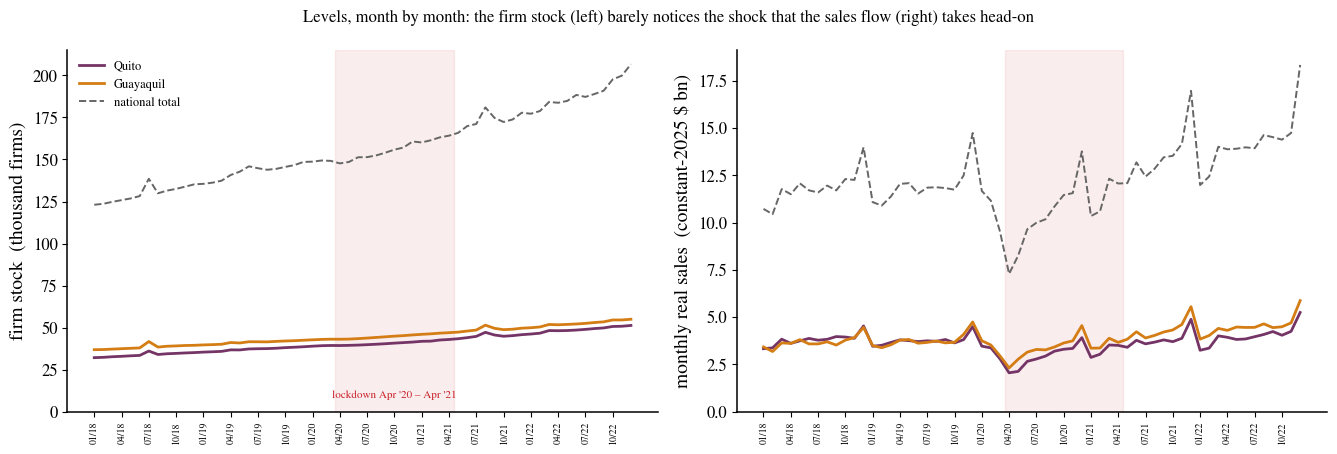

In [18]:
# ==============================================================================
# STEP I (cont.) -- the same monthly lens on SALES: levels + the Feb-2020 index
# ------------------------------------------------------------------------------
# Two companions to the firm-stock figure above, from the SAME monthly panel
# (CIIU sections summed per parish-month). Sales are real (constant-2025 $,
# the notebook's convention everywhere); swap "real_sales" -> "total_sales"
# below to see raw nominal dollars instead -- within a calendar year the two
# differ only by that year's constant IPC factor.
#   1) LEVELS: monthly firm stock (left) and monthly real sales (right) for
#      the two metros and the national total. The December sawtooth in sales
#      is real seasonality, so it is left unsmoothed.
#   2) INDEX: monthly real sales indexed to Feb 2020 = 100, in exactly the
#      firm-stock figure's format. The contrast with that figure IS the
#      finding: firm stocks never dipped, sales cratered during the lockdown.
# Reuses pm / mm / nat / BASE / METROS from the firm-stock cell.
# ==============================================================================
sm = (pm.groupby(["cod_parr", "t"])["real_sales"].sum().unstack(0)
        .sort_index().loc["2018M01":"2022M12"])          # metro monthly real sales
nat_s = pm.groupby("t")["real_sales"].sum().sort_index().loc["2018M01":"2022M12"]

xs_m = range(len(sm))
lock0, lock1 = sm.index.get_loc("2020M04"), sm.index.get_loc("2021M04")
xlab = [f"{m[5:]}/{m[2:4]}" for m in sm.index]


def style_month_axis(ax):
    ax.axvspan(lock0 - 0.5, lock1 + 0.5, color=style.RED, alpha=0.08, zorder=0)
    ax.set_xticks(list(xs_m)[::3])
    ax.set_xticklabels(xlab[::3], rotation=90, fontsize=7)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


# ---- figure 1: LEVELS, firms and sales side by side --------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
for ax, series, nat_series, ylab, scale in [
        (axes[0], mm, nat, "firm stock  (thousand firms)", 1e3),
        (axes[1], sm, nat_s, "monthly real sales  (constant-2025 $ bn)", 1e9)]:
    for parr, (nm, color) in METROS.items():
        ax.plot(xs_m, series[parr] / scale, lw=2.0, color=color, label=nm)
    ax.plot(xs_m, nat_series / scale, lw=1.4, ls="--", color="0.4",
            label="national total")
    style_month_axis(ax)
    ax.set_ylabel(ylab)
    ax.set_ylim(bottom=0)
axes[0].text((lock0 + lock1) / 2, 0.04, "lockdown Apr '20 – Apr '21", transform=axes[0].get_xaxis_transform(),
             ha="center", fontsize=8, color=style.RED)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Levels, month by month: the firm stock (left) barely notices the shock "
             "that the sales flow (right) takes head-on", fontsize=12)
fig.tight_layout()
fig.savefig(SEL_DIR / "metro_levels_monthly.png", dpi=200, bbox_inches="tight")
fig.savefig(SEL_DIR / "metro_levels_monthly.pdf", bbox_inches="tight")
print("saved ->", SEL_DIR / "metro_levels_monthly.png")
plt.show()

saved -> results/selection_anatomy/national_logs_monthly.svg


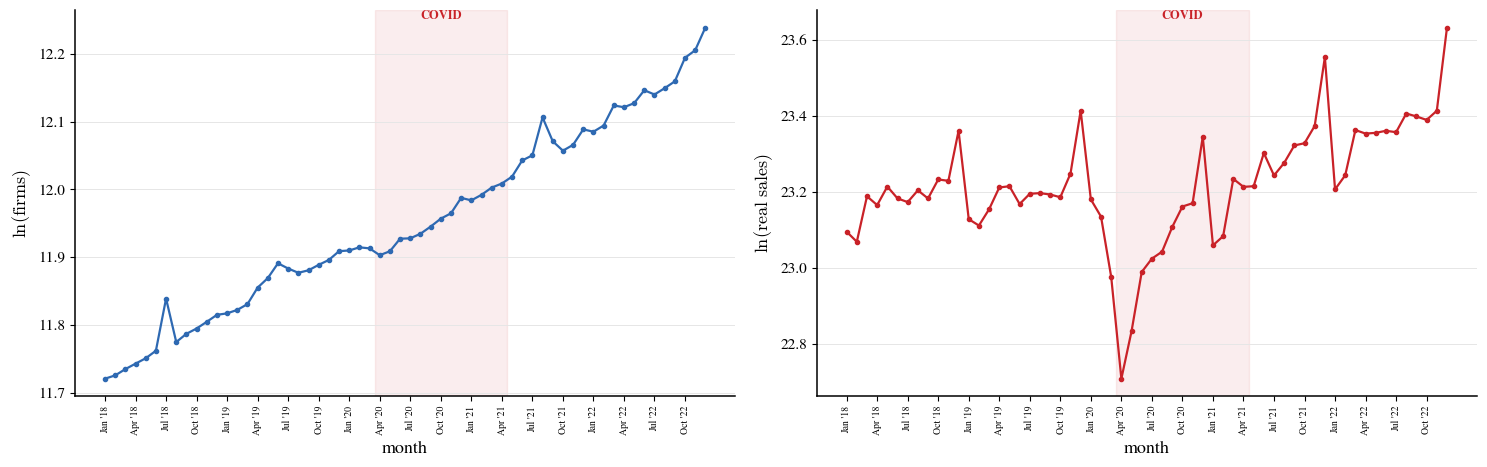

firms      2018M01 -> 2022M12: 123,074 -> 206,652 (+67.9%);  lockdown year +9.4%, trough 2020M04
real sales 2018M01 -> 2022M12: 10,719,704,958 -> 18,327,119,847 (+71.0%);  lockdown year +29.4%, trough 2020M04


In [19]:
# ==============================================================================
# STEP I (cont.) -- national monthly firms and sales, in logs
# ------------------------------------------------------------------------------
# The metro figure above, stripped down for the story: NATIONWIDE only (no Quito
# / Guayaquil lines), log firm stock (left, blue) and log real sales (right,
# red), 2018M01-2022M12. Drawn in the SAME monthly furniture as the pop / inc /
# den decomposition notebooks -- STIX serif, month labels every third month,
# light y-grid, shaded COVID band -- so the level series and the decomposition
# series read as one family of figures.
# In logs the SLOPE is the growth rate: the firm stock compounds through the
# shock (it only flattens), while sales take the hit head-on and carry the
# December seasonal spike the YoY decomposition windows difference away.
# Saved as SVG (vector).
# ==============================================================================
import calendar

plt.rcParams.update({
    "font.family":      "STIXGeneral",
    "mathtext.fontset": "cm",
    "axes.titlesize":   14,
    "axes.labelsize":   13,
    "xtick.labelsize":  11,
    "ytick.labelsize":  11,
    "axes.linewidth":   1.1,
    "axes.edgecolor":   "black",
})

FIRM_COLOR, SALES_COLOR = style.BLUE, style.RED     # same blue / red as the paths
COVID_C = style.RED
STRIDE_M = 3                                       # label every third month

pn = panel.copy()                                  # anio, mes, cod_parr, ...
pn["t"] = pn["anio"].astype(str) + "M" + pn["mes"].astype(str).str.zfill(2)
nat = (pn.groupby("t")[["total_firms", "real_sales"]].sum()
         .sort_index().loc["2018M01":"2022M12"])

xs_n = list(range(len(nat)))
mlab = [f"{calendar.month_abbr[int(m[5:])]} '{m[2:4]}" for m in nat.index]
lk0 = nat.index.get_loc("2020M04")                 # lockdown Mar-May 2020
lk1 = nat.index.get_loc("2021M04")

fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.8))
for ax, col, color, ylab in [
        (axes[0], "total_firms", FIRM_COLOR,
         r"$\ln(\mathrm{firms})$"),
        (axes[1], "real_sales", SALES_COLOR,
         r"$\ln(\mathrm{real\ sales})$")]:
    ax.axvspan(lk0 - 0.5, lk1 + 0.5, color=COVID_C, alpha=0.08, zorder=0)
    ax.plot(xs_n, np.log(nat[col].values), marker="o", ms=3, lw=1.6,
            color=color, zorder=3)
    ax.set_xticks(xs_n[::STRIDE_M])
    ax.set_xticklabels(mlab[::STRIDE_M], rotation=90, fontsize=7)
    ax.set_ylabel(ylab)
    ax.set_xlabel("month")
    ax.grid(axis="y", color="0.9", lw=0.7)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.text((lk0 + lk1) / 2, ax.get_ylim()[1], "COVID", ha="center", va="top",
            fontsize=9, fontweight="bold", color=COVID_C)

fig.tight_layout()
fig.savefig(SEL_DIR / "national_logs_monthly.svg", bbox_inches="tight")
print("saved ->", SEL_DIR / "national_logs_monthly.svg")
plt.show()

# the numbers the figure is telling
for col, name in [("total_firms", "firms"), ("real_sales", "real sales")]:
    s = nat[col]
    covid = s.loc["2020M03":"2021M03"]
    print(f"{name:10s} {s.index[0]} -> {s.index[-1]}: "
          f"{s.iloc[0]:,.0f} -> {s.iloc[-1]:,.0f} ({s.iloc[-1] / s.iloc[0] - 1:+.1%});  "
          f"lockdown year {covid.iloc[-1] / covid.iloc[0] - 1:+.1%}, "
          f"trough {covid.idxmin()}")

saved -> results/selection_anatomy/metro_sector_contributions.png


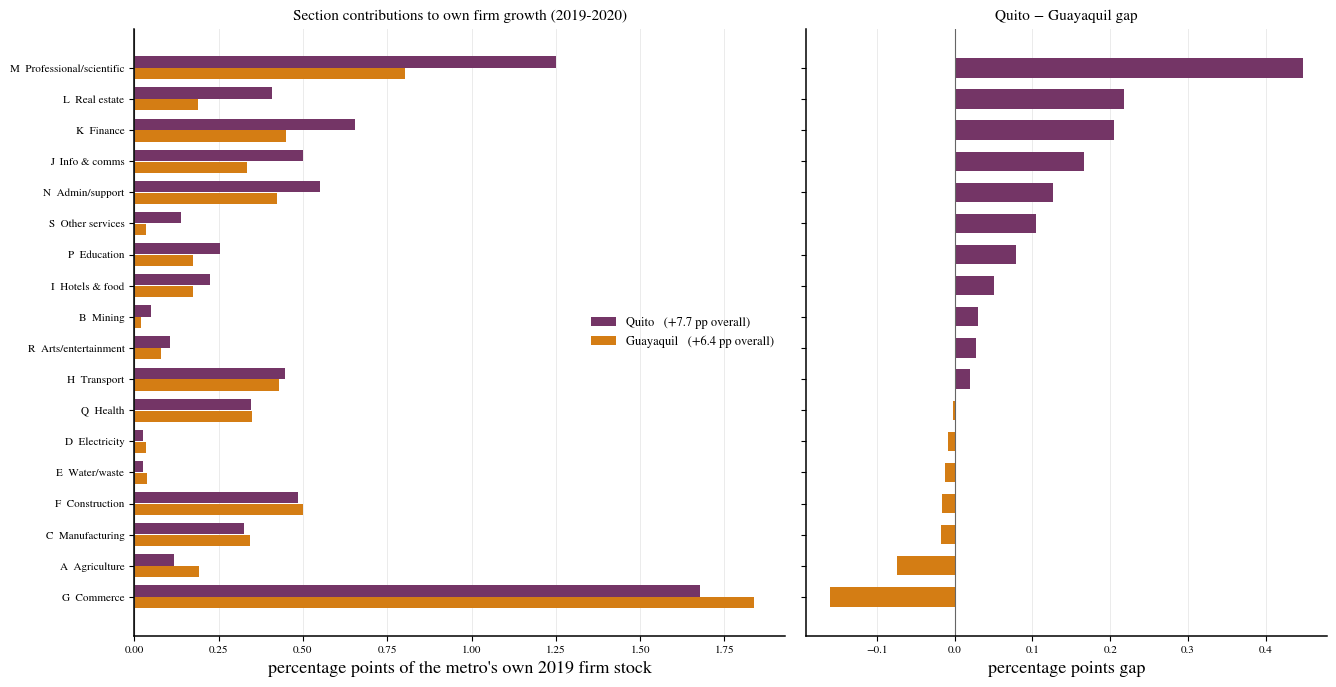

firm growth 2019->2020, all sections: Quito +7.65 pp, Guayaquil +6.43 pp.  Dropped 9/O/T/U/V: Quito +0.061 pp, Guayaquil +0.021 pp.

Quito-minus-Guayaquil gap by section (pp of own 2019 stock):
                     label  Quito  Guayaquil  gap
M  Professional/scientific   1.25       0.80 0.45
            L  Real estate   0.41       0.19 0.22
                K  Finance   0.65       0.45 0.20
           J  Info & comms   0.50       0.33 0.17
          N  Admin/support   0.55       0.42 0.13
         S  Other services   0.14       0.03 0.10
              P  Education   0.25       0.17 0.08
          I  Hotels & food   0.22       0.17 0.05
total gap: +1.22 pp   (log-growth gap +0.0114)


In [20]:
# ==============================================================================
# STEP I (cont.) -- WHERE Quito's fitness edge lives: CIIU sections
# ------------------------------------------------------------------------------
# Each metro's 2019 -> 2020 firm-count change split by CIIU rev-4 section
# (annual stock = mean of monthly stocks, matching the engine's collapse).
# Contributions are in pp = percentage points of the metro's OWN 2019 firm
# stock, so one metro's bars sum to its firm growth. Sections O/T/U/9 (public
# admin, households, extraterritorial, numeric-unclassified) are dropped -- a
# few dozen firms each, invisible on the axis; what they were worth is printed.
# LEFT: paired bars, Quito and Guayaquil on the same rows, sorted by the
# Quito-minus-Guayaquil gap. RIGHT: that gap itself, coloured by who leads.
# ==============================================================================
SECTION_NAME = {
    "A": "Agriculture", "B": "Mining", "C": "Manufacturing", "D": "Electricity",
    "E": "Water/waste", "F": "Construction", "G": "Commerce", "H": "Transport",
    "I": "Hotels & food", "J": "Info & comms", "K": "Finance", "L": "Real estate",
    "M": "Professional/scientific", "N": "Admin/support", "O": "Public admin",
    "P": "Education", "Q": "Health", "R": "Arts/entertainment", "S": "Other services",
    "T": "Households", "U": "Extraterritorial", "V": "Unclassified", "9": "Unclassified"}

DROP_SECTIONS = {"O", "T", "U", "9", "V"}

Q_BLUE, G_RED = METROS["170150"][1], METROS["090150"][1]

sec = pd.read_parquet(paths.FIRM_REVENUE_PARQUET, columns=["anio", "mes", "cod_parr",
                                             "cod_ciuu4", "total_firms"])
sec = sec[sec["cod_parr"].isin(METROS) &
          sec["anio"].isin([str(y) for y in COVID_PAIR])]
stock = (sec.groupby(["cod_parr", "anio", "cod_ciuu4", "mes"])["total_firms"].sum()
            .groupby(["cod_parr", "anio", "cod_ciuu4"]).mean().unstack("anio"))

contrib = {}
for parr, (nm, _) in METROS.items():
    d = stock.loc[parr].fillna(0.0)
    contrib[nm] = ((d[str(COVID_PAIR[1])] - d[str(COVID_PAIR[0])])
                   / d[str(COVID_PAIR[0])].sum() * 100)
gap = pd.DataFrame(contrib).fillna(0.0)
gap["gap"] = gap["Quito"] - gap["Guayaquil"]
gap["label"] = [f"{s}  {SECTION_NAME.get(s, s)}" for s in gap.index]

Q_TOT, G_TOT = gap["Quito"].sum(), gap["Guayaquil"].sum()   # all sections
drop = gap[gap.index.isin(DROP_SECTIONS)]
gap = gap[~gap.index.isin(DROP_SECTIONS)].sort_values("gap")   # Quito edge on top

ypos = np.arange(len(gap))
fig, axes = plt.subplots(1, 2, figsize=(13.5, 7.0), sharey=True,
                         gridspec_kw={"width_ratios": [1.25, 1]})

# LEFT: the two metros side by side, section by section
axes[0].barh(ypos + 0.19, gap["Quito"], height=0.36, color=Q_BLUE,
             label=f"Quito   ({Q_TOT:+.1f} pp overall)")
axes[0].barh(ypos - 0.19, gap["Guayaquil"], height=0.36, color=G_RED,
             label=f"Guayaquil   ({G_TOT:+.1f} pp overall)")
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(gap["label"], fontsize=8)
axes[0].set_title(f"Section contributions to own firm growth "
                  f"({COVID_PAIR[0]}-{COVID_PAIR[1]})", fontsize=11)
axes[0].set_xlabel("percentage points of the metro's own 2019 firm stock")
axes[0].legend(frameon=False, fontsize=9, loc="center right")

# RIGHT: the gap, coloured by who leads
axes[1].barh(ypos, gap["gap"], height=0.62,
             color=[Q_BLUE if v > 0 else G_RED for v in gap["gap"]])
axes[1].set_title(f"Quito − Guayaquil gap",
                  fontsize=11)
axes[1].set_xlabel("percentage points gap")

for ax in axes:
    ax.axvline(0, color="0.4", lw=0.8)
    ax.grid(axis="x", color="0.92", lw=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig.tight_layout()
for ext in ("png", "pdf", "svg"):
    fig.savefig(SEL_DIR / f"metro_sector_contributions.{ext}", dpi=200,
                bbox_inches="tight")
print("saved ->", SEL_DIR / "metro_sector_contributions.png")
plt.show()

print(f"firm growth {COVID_PAIR[0]}->{COVID_PAIR[1]}, all sections: "
      f"Quito {Q_TOT:+.2f} pp, Guayaquil {G_TOT:+.2f} pp.  Dropped "
      f"{'/'.join(sorted(DROP_SECTIONS))}: Quito {drop['Quito'].sum():+.3f} pp, "
      f"Guayaquil {drop['Guayaquil'].sum():+.3f} pp.")
print("\nQuito-minus-Guayaquil gap by section (pp of own 2019 stock):")
print(gap.sort_values("gap", ascending=False)[["label", "Quito", "Guayaquil", "gap"]]
      .head(8).round(2).to_string(index=False))
g_q = np.log(stock.loc["170150", str(COVID_PAIR[1])].sum()
             / stock.loc["170150", str(COVID_PAIR[0])].sum())
g_g = np.log(stock.loc["090150", str(COVID_PAIR[1])].sum()
             / stock.loc["090150", str(COVID_PAIR[0])].sum())
print(f"total gap: {Q_TOT - G_TOT:+.2f} pp   (log-growth gap {g_q - g_g:+.4f})")

In [21]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.affinity import rotate, scale

# ==============================================================================
# 1. SETUP PATHS & CONFIGURATION
# ==============================================================================

CANT_NAME = {c[:4]: k.title().strip() for c, k in zip(dpa[1], dpa[5])}
PROV_NAME = {c[:2]: pr.title().strip() for c, pr in zip(dpa[1], dpa[3])}

LEVEL_SHAPES = {
    "parish":   (paths.SHAPEFILES["parish"],
                 "DPA_PARROQ", PARR_NAME),
    "canton":   (paths.SHAPEFILES["canton"],
                 "DPA_CANTON", CANT_NAME),
    "province": (paths.SHAPEFILES["province"],
                 "DPA_PROVIN", PROV_NAME),
}

# Output directory for exported SVGs
OUTPUT_DIR = SEL_DIR if 'SEL_DIR' in globals() else Path("./exported_svgs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Styling Parameters
MAP_FILL_COLOR = style.BLUE  # Solid deep vector blue
BORDER_COLOR   = style.EDGE  # Crisp white border lines

LINE_WIDTHS = {
    "province": 0.8,
    "canton":   0.5,
    "parish":   0.2,
}

# ==============================================================================
# 2. GENERATE & EXPORT SVGs (NORMAL + OPPOSITE ISOMETRIC -45°)
# ==============================================================================
print("Exporting raw flat and -45° rotated isometric SVGs...")

for level in ["province", "canton", "parish"]:
    shp_path, key, _ = LEVEL_SHAPES[level]
    lw = LINE_WIDTHS[level]
    
    # Read original shapefile without simplification
    gdf = gpd.read_file(shp_path)
    
    # --------------------------------------------------------------------------
    # A. NORMAL (FLAT 2D / NO ROTATION) SVG EXPORT
    # --------------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf.plot(
        ax=ax,
        color=MAP_FILL_COLOR,
        edgecolor=BORDER_COLOR,
        linewidth=lw,
        antialiased=True
    )
    ax.set_axis_off()
    ax.set_aspect('equal')
    
    flat_output = OUTPUT_DIR / f"ecuador_{level}_flat_normal.svg"
    plt.savefig(
        flat_output,
        format="svg",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0
    )
    plt.close(fig)
    print(f"Saved Normal Flat: {flat_output}")

    # --------------------------------------------------------------------------
    # B. -45° ROTATED ISOMETRIC PROJECTION SVG EXPORT
    # --------------------------------------------------------------------------
    # Calculate geometric centroid for rotation anchor
    center = gdf.union_all().centroid if hasattr(gdf, "union_all") else gdf.unary_union.centroid
    
    # Rotate -45 degrees (opposite direction) and scale Y by 57.735%
    projected_geoms = gdf["geometry"].apply(
        lambda geom: scale(rotate(geom, angle=-45, origin=center), xfact=1.0, yfact=0.57735, origin=center)
    )
    
    gdf_iso = gdf.copy()
    gdf_iso["geometry"] = projected_geoms
    
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf_iso.plot(
        ax=ax,
        color=MAP_FILL_COLOR,
        edgecolor=BORDER_COLOR,
        linewidth=lw,
        antialiased=True
    )
    ax.set_axis_off()
    ax.set_aspect('equal')
    
    iso_output = OUTPUT_DIR / f"ecuador_{level}_minus45deg_isometric.svg"
    plt.savefig(
        iso_output,
        format="svg",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0
    )
    plt.close(fig)
    print(f"Saved Isometric (-45°): {iso_output}")

print("\nAll SVG layers generated successfully.")

Exporting raw flat and -45° rotated isometric SVGs...


Saved Normal Flat: results/selection_anatomy/ecuador_province_flat_normal.svg


Saved Isometric (-45°): results/selection_anatomy/ecuador_province_minus45deg_isometric.svg


Saved Normal Flat: results/selection_anatomy/ecuador_canton_flat_normal.svg


Saved Isometric (-45°): results/selection_anatomy/ecuador_canton_minus45deg_isometric.svg


Saved Normal Flat: results/selection_anatomy/ecuador_parish_flat_normal.svg


Saved Isometric (-45°): results/selection_anatomy/ecuador_parish_minus45deg_isometric.svg

All SVG layers generated successfully.


In [22]:
import geopandas as gpd
import matplotlib.pyplot as plt
import re
from pathlib import Path
from shapely.affinity import rotate, scale

# ==============================================================================
# 1. SETUP PATHS & CONFIGURATION
# ==============================================================================

CANT_NAME = {c[:4]: k.title().strip() for c, k in zip(dpa[1], dpa[5])}
PROV_NAME = {c[:2]: pr.title().strip() for c, pr in zip(dpa[1], dpa[3])}

LEVEL_SHAPES = {
    "parish":   (paths.SHAPEFILES["parish"],
                 "DPA_PARROQ", PARR_NAME),
    "canton":   (paths.SHAPEFILES["canton"],
                 "DPA_CANTON", CANT_NAME),
    "province": (paths.SHAPEFILES["province"],
                 "DPA_PROVIN", PROV_NAME),
}

# Output directory for exported SVGs
OUTPUT_DIR = SEL_DIR if 'SEL_DIR' in globals() else Path("./exported_svgs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Styling Parameters
MAP_FILL_COLOR = style.BLUE  # Solid deep vector blue
BORDER_COLOR   = style.EDGE  # Crisp white border lines

LINE_WIDTHS = {
    "province": 0.8,
    "canton":   0.5,
    "parish":   0.2,
}

# ==============================================================================
# 2. SVG TEXT OPTIMIZER HELPER
# ==============================================================================
def optimize_svg_file(filepath):
    """Strips excessive decimal precision from SVG text to drastically reduce file size."""
    with open(filepath, 'r', encoding='utf-8') as f:
        svg_content = f.read()
    
    # Truncate coordinates to 4 decimal places (accurate to ~11 meters, safe for Lat/Lon)
    # E.g., changes -78.123456789 to -78.1234
    optimized_svg = re.sub(r'([-+]?\d+\.\d{4})\d+', r'\1', svg_content)
    
    with open(filepath, 'w', encoding='utf-8') as f:
        f.write(optimized_svg)

# ==============================================================================
# 3. GENERATE & EXPORT SVGs (NORMAL + OPPOSITE ISOMETRIC -45°)
# ==============================================================================
print("Exporting flat and -45° rotated isometric SVGs (Optimized)...")

for level in ["province", "canton", "parish"]:
    shp_path, key, _ = LEVEL_SHAPES[level]
    lw = LINE_WIDTHS[level]
    
    # Read shapefile
    gdf = gpd.read_file(shp_path)
    
    # --------------------------------------------------------------------------
    # OPTIMIZATION: INVISIBLE MICRO-SIMPLIFICATION
    # --------------------------------------------------------------------------
    # Temporarily project to metric (UTM 17S) to use exactly meters for tolerance
    gdf_metric = gdf.to_crs(epsg=32717)
    
    # 50 meters is imperceptible at the national scale but removes thousands 
    # of redundant coordinate points along jagged boundaries.
    gdf_metric["geometry"] = gdf_metric["geometry"].simplify(tolerance=50, preserve_topology=True)
    
    # Reproject back to standard Lat/Lon (WGS84)
    gdf_optimized = gdf_metric.to_crs(epsg=4326)
    
    # --------------------------------------------------------------------------
    # A. NORMAL (FLAT 2D / NO ROTATION) SVG EXPORT
    # --------------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf_optimized.plot(
        ax=ax,
        color=MAP_FILL_COLOR,
        edgecolor=BORDER_COLOR,
        linewidth=lw,
        antialiased=True
    )
    ax.set_axis_off()
    ax.set_aspect('equal')
    
    flat_output = OUTPUT_DIR / f"ecuador_{level}_flat_normal.svg"
    plt.savefig(
        flat_output,
        format="svg",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0
    )
    plt.close(fig)
    optimize_svg_file(flat_output) # Strip SVG float bloat
    print(f"Saved & Optimized Normal Flat: {flat_output}")

    # --------------------------------------------------------------------------
    # B. -45° ROTATED ISOMETRIC PROJECTION SVG EXPORT
    # --------------------------------------------------------------------------
    center = gdf_optimized.union_all().centroid if hasattr(gdf_optimized, "union_all") else gdf_optimized.unary_union.centroid
    
    # Rotate -45 degrees and scale Y by 57.735% to fake a 3D isometric plane
    projected_geoms = gdf_optimized["geometry"].apply(
        lambda geom: scale(rotate(geom, angle=-45, origin=center), xfact=1.0, yfact=0.57735, origin=center)
    )
    
    gdf_iso = gdf_optimized.copy()
    gdf_iso["geometry"] = projected_geoms
    
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf_iso.plot(
        ax=ax,
        color=MAP_FILL_COLOR,
        edgecolor=BORDER_COLOR,
        linewidth=lw,
        antialiased=True
    )
    ax.set_axis_off()
    ax.set_aspect('equal')
    
    iso_output = OUTPUT_DIR / f"ecuador_{level}_minus45deg_isometric.svg"
    plt.savefig(
        iso_output,
        format="svg",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0
    )
    plt.close(fig)
    optimize_svg_file(iso_output) # Strip SVG float bloat
    print(f"Saved & Optimized Isometric (-45°): {iso_output}")

print("\nAll optimized SVG layers generated successfully.")

Exporting flat and -45° rotated isometric SVGs (Optimized)...


Saved & Optimized Normal Flat: results/selection_anatomy/ecuador_province_flat_normal.svg
Saved & Optimized Isometric (-45°): results/selection_anatomy/ecuador_province_minus45deg_isometric.svg


Saved & Optimized Normal Flat: results/selection_anatomy/ecuador_canton_flat_normal.svg


Saved & Optimized Isometric (-45°): results/selection_anatomy/ecuador_canton_minus45deg_isometric.svg


Saved & Optimized Normal Flat: results/selection_anatomy/ecuador_parish_flat_normal.svg


Saved & Optimized Isometric (-45°): results/selection_anatomy/ecuador_parish_minus45deg_isometric.svg

All optimized SVG layers generated successfully.


In [23]:
import geopandas as gpd
import matplotlib.pyplot as plt
import re
from pathlib import Path
from shapely.affinity import affine_transform

# ==============================================================================
# 1. SETUP PATHS & CONFIGURATION
# ==============================================================================

CANT_NAME = {c[:4]: k.title().strip() for c, k in zip(dpa[1], dpa[5])}
PROV_NAME = {c[:2]: pr.title().strip() for c, pr in zip(dpa[1], dpa[3])}

LEVEL_SHAPES = {
    "parish":   (paths.SHAPEFILES["parish"],
                 "DPA_PARROQ", PARR_NAME),
    "canton":   (paths.SHAPEFILES["canton"],
                 "DPA_CANTON", CANT_NAME),
    "province": (paths.SHAPEFILES["province"],
                 "DPA_PROVIN", PROV_NAME),
}

OUTPUT_DIR = SEL_DIR if 'SEL_DIR' in globals() else Path("./exported_svgs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Oblique Projection Parameters (Matches reference diagram plane tilt)
SHEAR_X = 0.55   # Slant factor along X-axis (keeps top/bottom horizontal)
SCALE_Y = 0.35   # Vertical compression factor

# Map Styling
MAP_FILL_COLOR = style.BLUE  # Deep vector blue
BORDER_COLOR   = style.EDGE  # Crisp white borders

LINE_WIDTHS = {
    "province": 0.8,
    "canton":   0.5,
    "parish":   0.2,
}

def optimize_svg(filepath):
    """Strips excessive coordinate decimals to keep SVG file size lightweight."""
    with open(filepath, 'r', encoding='utf-8') as f:
        svg_text = f.read()
    optimized = re.sub(r'([-+]?\d+\.\d{3})\d+', r'\1', svg_text)
    with open(filepath, 'w', encoding='utf-8') as f:
        f.write(optimized)

# ==============================================================================
# 2. EXPORT INDIVIDUAL OBLIQUE SVGs
# ==============================================================================
print("Exporting oblique-projected SVG layers...")

for level in ["province", "canton", "parish"]:
    shp_path, _, _ = LEVEL_SHAPES[level]
    lw = LINE_WIDTHS[level]
    
    # 1. Read shapefile
    gdf = gpd.read_file(shp_path)
    
    # 2. Micro-simplify (50m) to trim vertex bloat without losing boundary precision
    gdf_metric = gdf.to_crs(epsg=32717)
    gdf_metric["geometry"] = gdf_metric["geometry"].simplify(50, preserve_topology=True)
    gdf_clean = gdf_metric.to_crs(epsg=4326)
    
    # 3. Apply Oblique Shear Transformation
    projected_geoms = gdf_clean["geometry"].apply(
        lambda geom: affine_transform(geom, [1.0, SHEAR_X, 0.0, SCALE_Y, 0.0, 0.0])
    )
    gdf_projected = gdf_clean.copy()
    gdf_projected["geometry"] = projected_geoms
    
    # 4. Render clean vector canvas
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf_projected.plot(
        ax=ax,
        color=MAP_FILL_COLOR,
        edgecolor=BORDER_COLOR,
        linewidth=lw,
        antialiased=True
    )
    
    ax.set_axis_off()
    ax.set_aspect('equal')
    
    # 5. Save transparent SVG
    output_filepath = OUTPUT_DIR / f"ecuador_{level}_oblique.svg"
    plt.savefig(
        output_filepath,
        format="svg",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0
    )
    plt.close(fig)
    
    # 6. Post-process to minimize file size
    optimize_svg(output_filepath)
    print(f"Saved: {output_filepath}")

print("\nDone! Exported 3 standalone oblique vector layers.")

Exporting oblique-projected SVG layers...


Saved: results/selection_anatomy/ecuador_province_oblique.svg


Saved: results/selection_anatomy/ecuador_canton_oblique.svg


Saved: results/selection_anatomy/ecuador_parish_oblique.svg

Done! Exported 3 standalone oblique vector layers.


### What is it about Quito — the answer in three layers

**Layer 1: nobody actually lost firms — the whole contest is relative.** The monthly plot shows both metros' (and the national) active-firm stocks rising *straight through the lockdown*: Quito 2019→20 firm growth +7.4%, Guayaquil +6.2%, firm-weighted national average ≈ +6.7%. Quito sits ~0.9 pp **above** the bar, Guayaquil ~0.3 pp **below** it — and because both carry ≈ a quarter of all firms at ≈ +2.4 log points of trait, those sub-percentage-point deviations become the largest single + and − selection contributions in the country. (Registrations are stocks of active RUCs: they capture firms *existing*, and de-registration is slow, so the shock shows up as slower accumulation, not decline.)

**Layer 2: Quito's edge lives in teleworkable services.** The section split shows commerce (G) added the most firms in *both* metros at an almost identical pace (+1.7 vs +1.8 pp). The gap is concentrated in **M professional/scientific (+1.3 vs +0.8 pp), K finance (+0.7 vs +0.4), N admin/support (+0.6 vs +0.4) and J information (+0.5 vs +0.3)** — precisely the sectors where a newly independent professional can register a RUC and operate from home during a lockdown. Quito, as the capital, hosts the government-adjacent, HQ and professional-services ecosystem where that response is available; Guayaquil's port-commerce-transport mix has fewer such margins. A plausible reading (interpretation, not directly tested): part of Quito's firm-creation surge is **necessity entrepreneurship** — salaried workers who lost income re-registering as independent service providers.

**Layer 3: the intensive margin points the other way — and *that* answers "why do all the metros take the biggest transmission hit".** Transmission contributions are (final firm share) × (own sales change): the metros dominate mechanically because they hold ≈ 55% of all firms. But note the twist in the printed table: **Quito's own real sales fell *more* than Guayaquil's** (Δln ≈ −0.22, ≈ −20%, vs ≈ −0.11, ≈ −11%) — despite Guayaquil being the epidemiological epicentre in April 2020. Quito had the country's largest sales collapse *and* above-average firm creation *at the same time*: existing firms' revenue crashed (long metropolitan lockdown, service-sector shutdown) while cheap-to-create service RUCs kept accumulating. The two Price terms are not contradicting each other — they are measuring different margins of the same event, and Quito is the cleanest example in the data of the extensive margin (selection, +) decoupling from the intensive margin (transmission, −).

One more corroborating detail from the maps: Guayaquil's *satellites* (Daule, Samborondón, Durán) kept out-growing the average — some of Guayas' formal-firm creation relocated to the suburban ring rather than the core parish, further shaving Guayaquil's own relative fitness.